## 1. Environnement et vérification

In [25]:

import torch
import pandas as pd
import numpy as np
import sklearn
import os

print("PyTorch :", torch.__version__)
print("Pandas :", pd.__version__)
print("Scikit-learn :", sklearn.__version__)

print("\nGPU disponible :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("Nom du GPU :", torch.cuda.get_device_name(0))
else:
    print("Environnement CPU")


PyTorch : 2.11.0+cu128
Pandas : 2.3.3
Scikit-learn : 1.6.1

GPU disponible : True
Nom du GPU : Tesla T4


# 2. Télécharger le dataset MLMA

In [26]:

import subprocess
from pathlib import Path

repo_url = "https://github.com/HKUST-KnowComp/MLMA_hate_speech.git"
repo_dir = Path("/kaggle/working/mlma_data/MLMA_hate_speech")

repo_dir.parent.mkdir(parents=True, exist_ok=True)

print("URL utilisée :", repo_url)

if not repo_dir.exists():
    result = subprocess.run(
        ["git", "clone", "--depth", "1", repo_url, str(repo_dir)],
        capture_output=True,
        text=True
    )
    print("Code retour :", result.returncode)
    print("Message Git :", result.stderr)
else:
    print("Dépôt déjà présent")


URL utilisée : https://github.com/HKUST-KnowComp/MLMA_hate_speech.git
Dépôt déjà présent


# 3. Extraire les fichiers CSV

In [27]:

from pathlib import Path
import zipfile

extract_dir = Path(
    "/kaggle/working/mlma_data/extracted"
)

data_dir = extract_dir / "hate_speech_mlma"

required_files = [
    "ar_dataset.csv",
    "fr_dataset.csv",
    "en_dataset.csv"
]

# Vérifier si les datasets sont déjà extraits
if all((data_dir / name).exists() for name in required_files):

    print("Les datasets sont déjà extraits.")
    print("Aucune extraction nécessaire.")

else:

    zip_path = Path(
        "/kaggle/working/mlma_data/MLMA_hate_speech/hate_speech_mlma.zip"
    )

    if zip_path.exists():

        extract_dir.mkdir(parents=True, exist_ok=True)

        with zipfile.ZipFile(zip_path, "r") as z:
            z.extractall(extract_dir)

        print("Extraction terminée.")

    else:
        raise FileNotFoundError(
            "Datasets et archive ZIP introuvables. "
            "Vérifie les fichiers dans /kaggle/input."
        )

print("\nFichiers disponibles :")

for name in required_files:
    path = data_dir / name
    print(name, ":", "OK" if path.exists() else "MANQUANT")


Les datasets sont déjà extraits.
Aucune extraction nécessaire.

Fichiers disponibles :
ar_dataset.csv : OK
fr_dataset.csv : OK
en_dataset.csv : OK


# 4. Charger les trois datasets

In [28]:

from pathlib import Path

required_files = [
    "ar_dataset.csv",
    "fr_dataset.csv",
    "en_dataset.csv"
]

csv_files = {}

for filename in required_files:
    matches = list(Path("/kaggle").rglob(filename))

    if matches:
        csv_files[filename] = matches[0]
        print(f"OK : {filename} -> {matches[0]}")
    else:
        print(f"INTROUVABLE : {filename}")

if len(csv_files) != 3:
    raise FileNotFoundError(
        "Les trois datasets MLMA ne sont pas disponibles. "
        "Vérifie le téléchargement ou l'extraction."
    )


OK : ar_dataset.csv -> /kaggle/working/mlma_data/extracted/hate_speech_mlma/ar_dataset.csv
OK : fr_dataset.csv -> /kaggle/working/mlma_data/extracted/hate_speech_mlma/fr_dataset.csv
OK : en_dataset.csv -> /kaggle/working/mlma_data/extracted/hate_speech_mlma/en_dataset.csv


In [29]:

df_ar = pd.read_csv(csv_files["ar_dataset.csv"])
df_fr = pd.read_csv(csv_files["fr_dataset.csv"])
df_en = pd.read_csv(csv_files["en_dataset.csv"])

datasets = {
    "Arabe": df_ar,
    "Français": df_fr,
    "Anglais": df_en
}

for langue, df in datasets.items():
    print(f"\n===== {langue.upper()} =====")
    print("Dimensions :", df.shape)
    print("Colonnes :", df.columns.tolist())
    print("Valeurs manquantes :", df.isnull().sum().sum())
    
display(df_ar.head())



===== ARABE =====
Dimensions : (3353, 7)
Colonnes : ['HITId', 'tweet', 'sentiment', 'directness', 'annotator_sentiment', 'target', 'group']
Valeurs manquantes : 0

===== FRANÇAIS =====
Dimensions : (4014, 7)
Colonnes : ['HITId', 'tweet', 'sentiment', 'directness', 'annotator_sentiment', 'target', 'group']
Valeurs manquantes : 0

===== ANGLAIS =====
Dimensions : (5647, 7)
Colonnes : ['HITId', 'tweet', 'sentiment', 'directness', 'annotator_sentiment', 'target', 'group']
Valeurs manquantes : 0


,HITId,tweet,sentiment,directness,annotator_sentiment,target,group
0,1,صلاة الفجر خير لك من ترديد بول البعير وسبي الن...,hateful_normal,indirect,shock,gender,individual
1,2,صراحة نفسي اشوف ولاد الوسخة اللي قالوا مدرب اج...,offensive,indirect,anger_confusion_sadness_indifference_disgust,other,other
2,3,طيب! هي متبرجة وعبايتها ملونه وطالعة من بيتهم ...,offensive,indirect,indifference,other,individual
3,4,@user @user انا اوافقك بخصوص السوريين و العراق...,normal,direct,indifference,origin,other
4,5,هذه السعودية التي شعبها شعب الخيم و بول البعير...,normal,indirect,indifference,origin,other


## Audit initial des données

In [30]:

import pandas as pd
import numpy as np
from pathlib import Path

# Fichier de sortie
OUTPUT_FILE = Path("/kaggle/working/audit_results.txt")

null_tokens = {"null", "none", "nan", "n/a", "na"}
label_cols = [
    "target", "sentiment", "directness",
    "group", "annotator_sentiment"
]

with open(OUTPUT_FILE, "w", encoding="utf-8") as f:

    def log(message=""):
        print(message)
        f.write(str(message) + "\n")

    log("=" * 75)
    log("TP2 - AUDIT DES DATASETS MLMA HATE SPEECH")
    log("=" * 75)

    for langue, df in datasets.items():

        log("\n" + "=" * 75)
        log(f"DATASET : {langue.upper()}")
        log("=" * 75)

        log(f"Nombre de lignes   : {df.shape[0]}")
        log(f"Nombre de colonnes : {df.shape[1]}")
        log(f"Colonnes : {list(df.columns)}")

        # 1. Valeurs manquantes
        nulls = df.isna().sum()

        empty = pd.Series(0, index=df.columns, dtype=int)
        textual_nulls = pd.Series(0, index=df.columns, dtype=int)

        for col in df.select_dtypes(
            include=["object", "string"]
        ).columns:

            values = df[col].astype("string").str.strip()

            empty[col] = values.eq("").sum()
            textual_nulls[col] = (
                values.str.lower().isin(null_tokens).sum()
            )

        # 2. Tableau de qualité
        audit = pd.DataFrame({
            "Type": df.dtypes.astype(str),
            "Valeurs uniques": df.nunique(dropna=True),
            "NaN / NULL": nulls,
            "Vides / Espaces": empty,
            "NULL textuels": textual_nulls
        })

        audit["Total manquant"] = (
            audit["NaN / NULL"]
            + audit["Vides / Espaces"]
            + audit["NULL textuels"]
        )

        audit["% manquant"] = (
            100 * audit["Total manquant"] / len(df)
        ).round(2)

        log("\n--- QUALITE DES COLONNES ---")
        log(audit.to_string())

        # 3. Doublons
        log("\n--- DOUBLONS ---")
        log(f"Lignes identiques : {df.duplicated().sum()}")

        if "tweet" in df.columns:
            log(
                f"Tweets identiques : "
                f"{df['tweet'].duplicated().sum()}"
            )

        # 4. Distribution des labels
        for col in label_cols:

            if col in df.columns:
                log(f"\n--- DISTRIBUTION : {col.upper()} ---")

                distribution = df[col].value_counts(
                    dropna=False
                )

                log(distribution.to_string())

        log("\n")

    log("=" * 75)
    log("FIN DE L'AUDIT")
    log("=" * 75)

print(f"\nFichier enregistré : {OUTPUT_FILE}")
print(f"Taille : {OUTPUT_FILE.stat().st_size / 1024:.2f} Ko")


TP2 - AUDIT DES DATASETS MLMA HATE SPEECH

DATASET : ARABE
Nombre de lignes   : 3353
Nombre de colonnes : 7
Colonnes : ['HITId', 'tweet', 'sentiment', 'directness', 'annotator_sentiment', 'target', 'group']

--- QUALITE DES COLONNES ---
                       Type  Valeurs uniques  NaN / NULL  Vides / Espaces  NULL textuels  Total manquant  % manquant
HITId                 int64             3353           0                0              0               0         0.0
tweet                object             3352           0                0              0               0         0.0
sentiment            object               37           0                0              0               0         0.0
directness           object                2           0                0              0               0         0.0
annotator_sentiment  object               46           0                0              0               0         0.0
target               object                5           0     

# separation sentiments 

In [31]:

import pandas as pd

# Les 6 types de sentiments
sentiment_labels = [
    "abusive",
    "hateful",
    "offensive",
    "normal",
    "disrespectful",
    "fearful"
]

# Modifier directement les DataFrames existants
for langue, df in datasets.items():

    print(f"\n{'='*60}")
    print(f"DATASET : {langue.upper()}")
    print(f"{'='*60}")

    # Séparer les labels avec "_"
    split_labels = df["sentiment"].str.split("_")

    # Créer les 6 colonnes binaires
    for label in sentiment_labels:
        df[f"sentiment_{label}"] = split_labels.apply(
            lambda labels: int(label in labels)
        )

    print("Dimensions après encodage :", df.shape)

    # Afficher les nouvelles colonnes
    cols = ["sentiment"] + [
        f"sentiment_{label}" for label in sentiment_labels
    ]

    display(df[cols].head(10))

    # Vérification
    print("\nNombre de tweets par catégorie :")
    print(df[cols[1:]].sum())

    print("\nTweets sans aucun label :")
    print((df[cols[1:]].sum(axis=1) == 0).sum())



DATASET : ARABE
Dimensions après encodage : (3353, 13)


,sentiment,sentiment_abusive,sentiment_hateful,sentiment_offensive,sentiment_normal,sentiment_disrespectful,sentiment_fearful
0,hateful_normal,0,1,0,1,0,0
1,offensive,0,0,1,0,0,0
2,offensive,0,0,1,0,0,0
3,normal,0,0,0,1,0,0
4,normal,0,0,0,1,0,0
5,offensive_disrespectful,0,0,1,0,1,0
6,offensive_normal,0,0,1,1,0,0
7,normal,0,0,0,1,0,0
8,offensive_disrespectful,0,0,1,0,1,0
9,hateful,0,1,0,0,0,0



Nombre de tweets par catégorie :
sentiment_abusive           610
sentiment_hateful           755
sentiment_offensive        1151
sentiment_normal           1197
sentiment_disrespectful     615
sentiment_fearful            41
dtype: int64

Tweets sans aucun label :
0

DATASET : FRANÇAIS
Dimensions après encodage : (4014, 13)


,sentiment,sentiment_abusive,sentiment_hateful,sentiment_offensive,sentiment_normal,sentiment_disrespectful,sentiment_fearful
0,abusive,1,0,0,0,0,0
1,offensive,0,0,1,0,0,0
2,hateful,0,1,0,0,0,0
3,normal,0,0,0,1,0,0
4,normal,0,0,0,1,0,0
5,offensive,0,0,1,0,0,0
6,normal,0,0,0,1,0,0
7,normal,0,0,0,1,0,0
8,offensive,0,0,1,0,0,0
9,offensive,0,0,1,0,0,0



Nombre de tweets par catégorie :
sentiment_abusive          1056
sentiment_hateful           399
sentiment_offensive        1690
sentiment_normal           1124
sentiment_disrespectful     396
sentiment_fearful           388
dtype: int64

Tweets sans aucun label :
0

DATASET : ANGLAIS
Dimensions après encodage : (5647, 13)


,sentiment,sentiment_abusive,sentiment_hateful,sentiment_offensive,sentiment_normal,sentiment_disrespectful,sentiment_fearful
0,offensive,0,0,1,0,0,0
1,offensive_disrespectful,0,0,1,0,1,0
2,fearful_abusive_offensive_hateful,1,1,1,0,0,1
3,fearful_abusive_hateful_disrespectful_normal,1,1,0,1,1,1
4,offensive,0,0,1,0,0,0
5,offensive,0,0,1,0,0,0
6,offensive,0,0,1,0,0,0
7,offensive,0,0,1,0,0,0
8,offensive,0,0,1,0,0,0
9,offensive,0,0,1,0,0,0



Nombre de tweets par catégorie :
sentiment_abusive           671
sentiment_hateful          1278
sentiment_offensive        4020
sentiment_normal           1359
sentiment_disrespectful     782
sentiment_fearful           562
dtype: int64

Tweets sans aucun label :
0


# Voire keyword.txxt

In [32]:

from pathlib import Path

# Chercher keywords.txt dans le dépôt téléchargé
files = list(repo_dir.rglob("keywords.txt"))

if files:
    for file in files:
        print(f"\nFichier trouvé : {file}")
        print("=" * 70)
        print(file.read_text(encoding="utf-8-sig"))
else:
    print("keywords.txt introuvable dans le dépôt.")



Fichier trouvé : /kaggle/working/mlma_data/MLMA_hate_speech/keywords.txt
*** Below are keywords/phrases that we used for our search. They include different spellings of common slurs, controversial topics, 
                              insulting patterns during debates, ... ***

  ENGLISH
___________
Immigrants 
refugees
Africa
AllLivesMatter
immigrant terror 
abusive women 
harassment
fake empowerment 
African attack 
protect from immigrants 
Eurafrica 
Immigrant not welcome
illegal immigrants
It's okay to be white 
feminazi
violence
refugees impact
asians
terrorist leftist
terrorist threat
ching chong
dirty jew
dirty pig
redneck
bring Ebola
bring disease
negro
illegal aliens
intellectual terrorist
intellectual terrorism
women threat
woman terrorist
shithole country
shithole countries
go back to where you come from
go back to where they come from
loud mexican
muslim countries
muslim country
muslim immigrant
muslim refugee
white christian 
christian country
immigrant invasion
muslim i

# analyser les doublons et les classes rares

In [33]:

from pathlib import Path
import pandas as pd

OUTPUT = Path("/kaggle/working/audit_details.txt")

with open(OUTPUT, "w", encoding="utf-8") as f:

    def log(text=""):
        print(text)
        f.write(str(text) + "\n")

    for langue, df in datasets.items():

        log(f"\n{'=' * 65}")
        log(f"LANGUE : {langue.upper()}")
        log("=" * 65)

        # Classes rares de target
        log("\nCLASSES TARGET AVEC MOINS DE 10 EXEMPLES")
        counts = df["target"].value_counts()
        log(counts[counts < 10].to_string())

        # Doublons exacts du texte
        duplicates = df[
            df.duplicated(subset=["tweet"], keep=False)
        ].copy()

        log(f"\nLignes appartenant à des groupes de doublons : {len(duplicates)}")

        # Doublons avec target contradictoire
        conflicts = (
            df.groupby("tweet")["target"]
            .nunique()
        )
        conflicting_tweets = conflicts[conflicts > 1].index

        log(f"Tweets avec target contradictoire : {len(conflicting_tweets)}")

        if len(conflicting_tweets) > 0:
            conflict_rows = df[
                df["tweet"].isin(conflicting_tweets)
            ][["HITId", "tweet", "target"]]

            log("\nEXEMPLES DE CONTRADICTIONS")
            log(conflict_rows.head(20).to_string(index=False))

        # Normalisation légère pour détecter des doublons cachés
        normalized = (
            df["tweet"]
            .astype(str)
            .str.strip()
            .str.lower()
            .str.replace(r"\s+", " ", regex=True)
        )

        log(
            "\nDoublons après normalisation légère : "
            f"{normalized.duplicated().sum()}"
        )

print(f"\nFichier enregistré : {OUTPUT}")


LANGUE : ARABE

CLASSES TARGET AVEC MOINS DE 10 EXEMPLES
target
disability    1

Lignes appartenant à des groupes de doublons : 2
Tweets avec target contradictoire : 1

EXEMPLES DE CONTRADICTIONS
 HITId                     tweet target
  1128 وانتي متبرجة مثيرة للشفقة gender
  2123 وانتي متبرجة مثيرة للشفقة  other

Doublons après normalisation légère : 3

LANGUE : FRANÇAIS

CLASSES TARGET AVEC MOINS DE 10 EXEMPLES
Series([], )

Lignes appartenant à des groupes de doublons : 16
Tweets avec target contradictoire : 3

EXEMPLES DE CONTRADICTIONS
 HITId                   tweet     target
   666 @user vai dormir mongol disability
  1352 @user vai dormir mongol      other
  2257          @user 1 mongol disability
  2936          @user 1 mongol     origin
  3618       @user tu é mongol      other
  3776       @user tu é mongol disability

Doublons après normalisation légère : 8

LANGUE : ANGLAIS

CLASSES TARGET AVEC MOINS DE 10 EXEMPLES
Series([], )

Lignes appartenant à des groupes de doublo

# Cleaning

In [34]:

import pandas as pd
from pathlib import Path

OUTPUT_DIR = Path("/kaggle/working/cleaned_data")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

label_cols = [
    "target",
    "sentiment",
    "directness",
    "group",
    "annotator_sentiment"
]

cleaned_datasets = {}
cleaning_report = []

for langue, df in datasets.items():

    data = df.copy()
    initial_size = len(data)

    # 1. Fusion de la classe rare en arabe
    if langue == "Arabe":
        data["target"] = data["target"].replace(
            {"disability": "other"}
        )

    # 2. Normalisation légère uniquement pour les doublons
    data["_normalized"] = (
        data["tweet"]
        .astype(str)
        .str.strip()
        .str.lower()
        .str.replace(r"\s+", " ", regex=True)
    )

    # 3. Détecter les groupes contradictoires
    conflicts = (
        data.groupby("_normalized")[label_cols]
        .nunique(dropna=False)
        .gt(1)
        .any(axis=1)
    )

    conflict_keys = conflicts[conflicts].index

    # 4. Sauvegarder les lignes contradictoires
    conflicting_rows = data[
        data["_normalized"].isin(conflict_keys)
    ].copy()

    # 5. Supprimer toutes les lignes contradictoires
    data = data[
        ~data["_normalized"].isin(conflict_keys)
    ].copy()

    after_conflicts = len(data)

    # 6. Retirer les doublons restants
    data = data.drop_duplicates(
        subset="_normalized",
        keep="first"
    )

    # 7. Calculer les suppressions
    n_conflicts = len(conflicting_rows)
    n_duplicates = after_conflicts - len(data)

    # 8. Supprimer la colonne temporaire
    data = data.drop(columns=["_normalized"])

    cleaned_datasets[langue] = data.reset_index(drop=True)

    # 9. Enregistrer les CSV
    code = {
        "Arabe": "ar",
        "Français": "fr",
        "Anglais": "en"
    }[langue]

    data.to_csv(
        OUTPUT_DIR / f"{code}_clean.csv",
        index=False,
        encoding="utf-8-sig"
    )

    conflicting_rows.to_csv(
        OUTPUT_DIR / f"{code}_conflicts.csv",
        index=False,
        encoding="utf-8-sig"
    )

    cleaning_report.append({
        "Langue": langue,
        "Initial": initial_size,
        "Contradictoires supprimés": n_conflicts,
        "Doublons supprimés": n_duplicates,
        "Final": len(data)
    })

summary = pd.DataFrame(cleaning_report)

display(summary)

summary.to_csv(
    OUTPUT_DIR / "cleaning_summary.csv",
    index=False
)

print("\nFichiers enregistrés :", OUTPUT_DIR)


,Langue,Initial,Contradictoires supprimés,Doublons supprimés,Final
0,Arabe,3353,6,0,3347
1,Français,4014,14,1,3999
2,Anglais,5647,100,0,5547



Fichiers enregistrés : /kaggle/working/cleaned_data


# visualisation 

In [35]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

FIG_DIR = Path("/kaggle/working/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (11, 6),
    "figure.dpi": 120,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "savefig.dpi": 300
})

# Utiliser les datasets après nettoyage
viz_datasets = cleaned_datasets

# Regrouper toutes les langues
df_all = pd.concat(
    [
        df.assign(language=langue)
        for langue, df in viz_datasets.items()
    ],
    ignore_index=True
)

LANG_ORDER = ["Arabe", "Français", "Anglais"]

print("Total de tweets après nettoyage :", len(df_all))
display(df_all.groupby("language").size())


Total de tweets après nettoyage : 12893


language
Anglais     5547
Arabe       3347
Français    3999
dtype: int64

# Distribution de target par langue

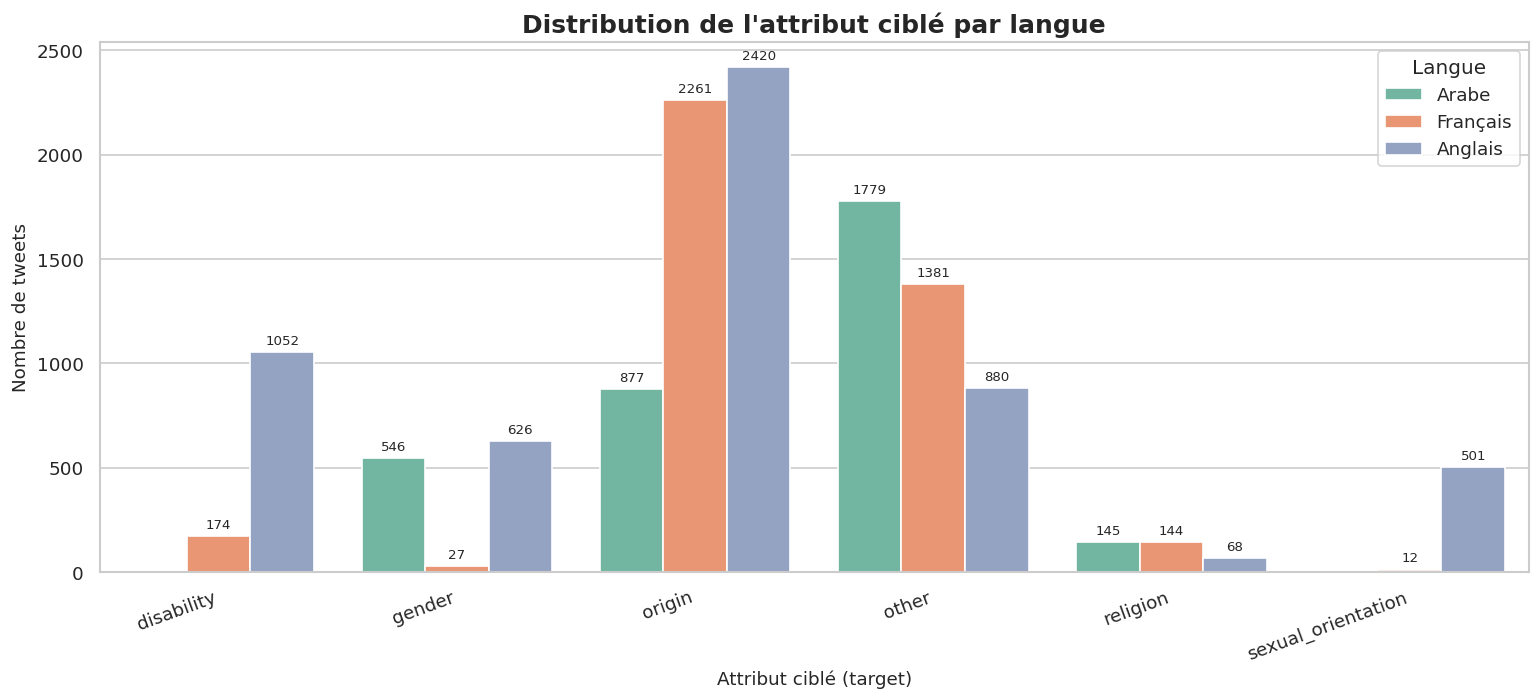

In [36]:

target_counts = (
    df_all.groupby(["language", "target"])
    .size()
    .reset_index(name="count")
)

plt.figure(figsize=(13, 6))

ax = sns.barplot(
    data=target_counts,
    x="target",
    y="count",
    hue="language",
    hue_order=LANG_ORDER,
    palette="Set2"
)

plt.title("Distribution de l'attribut ciblé par langue")
plt.xlabel("Attribut ciblé (target)")
plt.ylabel("Nombre de tweets")
plt.xticks(rotation=20, ha="right")
plt.legend(title="Langue")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3, fontsize=8)

plt.tight_layout()
plt.savefig(FIG_DIR / "01_target_distribution.png", bbox_inches="tight")
plt.show()
 

# Figure 2 — Distribution des six types de sentiments

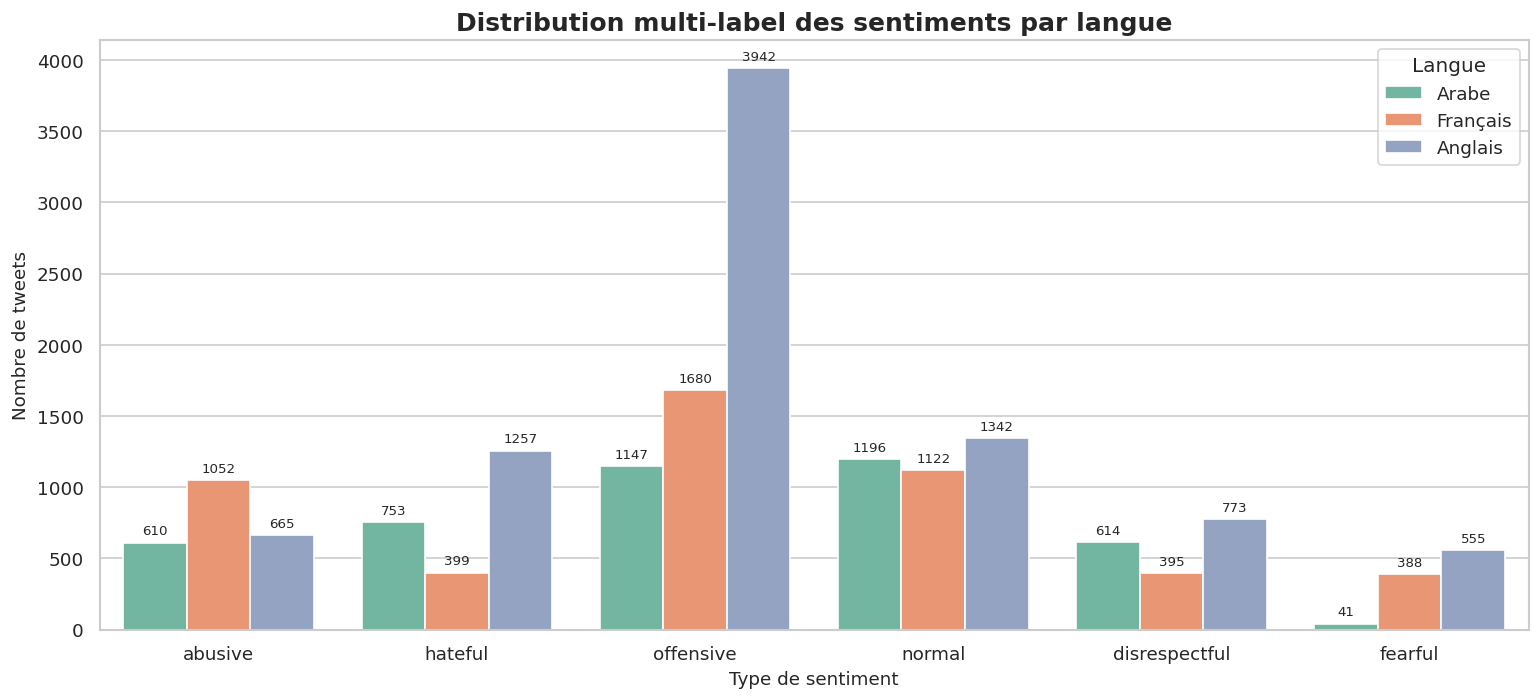

In [37]:

sentiment_labels = [
    "abusive", "hateful", "offensive",
    "normal", "disrespectful", "fearful"
]

sentiment_rows = []

for langue, df in viz_datasets.items():
    tokens = df["sentiment"].fillna("").str.split("_")

    for label in sentiment_labels:
        sentiment_rows.append({
            "language": langue,
            "sentiment": label,
            "count": tokens.apply(lambda x: label in x).sum()
        })

sentiment_counts = pd.DataFrame(sentiment_rows)

plt.figure(figsize=(13, 6))

ax = sns.barplot(
    data=sentiment_counts,
    x="sentiment",
    y="count",
    hue="language",
    hue_order=LANG_ORDER,
    palette="Set2"
)

plt.title("Distribution multi-label des sentiments par langue")
plt.xlabel("Type de sentiment")
plt.ylabel("Nombre de tweets")
plt.legend(title="Langue")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3, fontsize=8)

plt.tight_layout()
plt.savefig(FIG_DIR / "02_sentiment_distribution.png", bbox_inches="tight")
plt.show()
 

# Heatmap : relation entre target et group

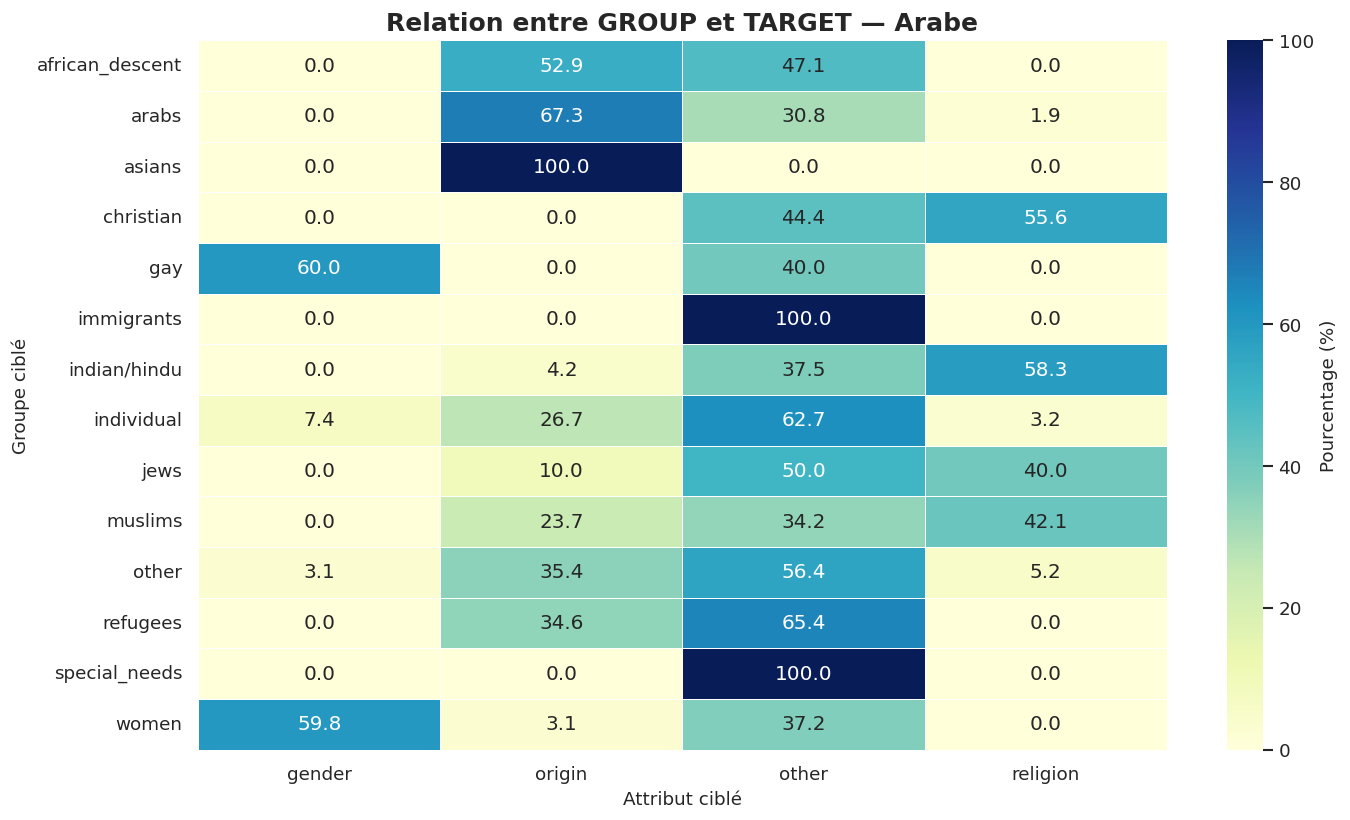

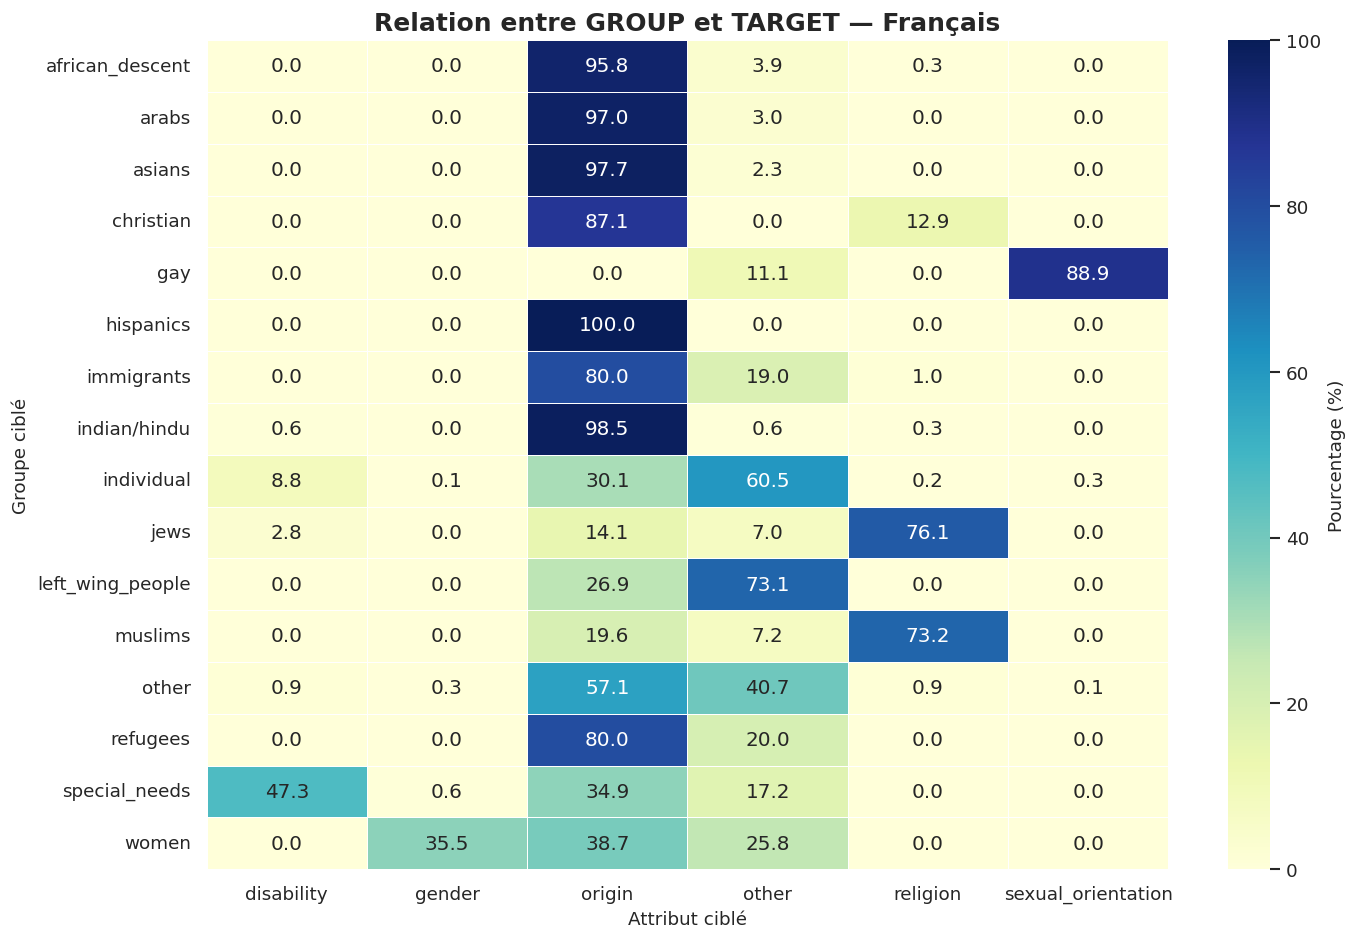

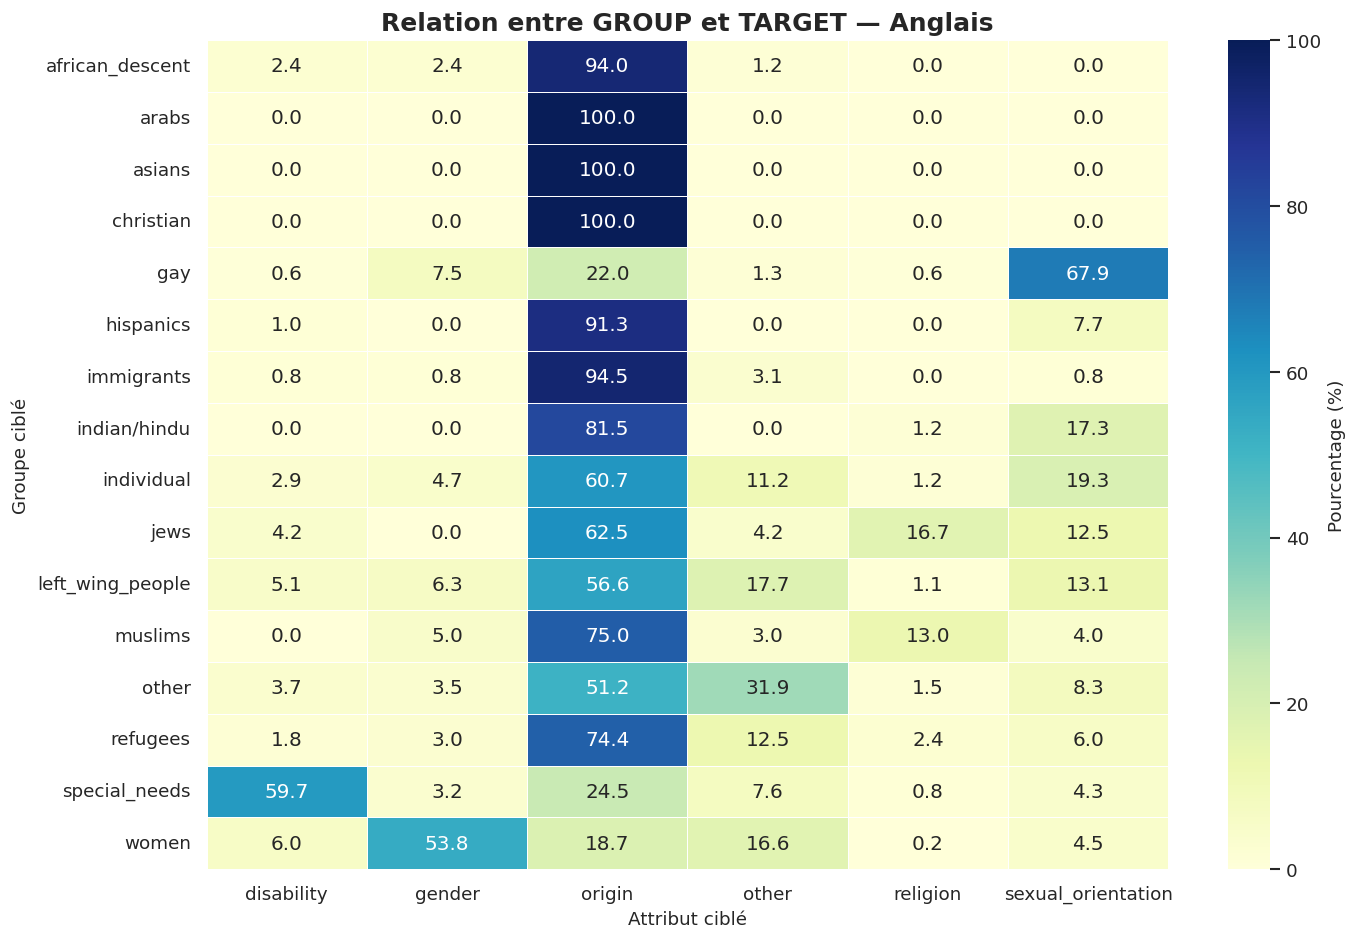

In [38]:

for langue, df in viz_datasets.items():

    table = pd.crosstab(df["group"], df["target"])

    # Pourcentage par groupe
    table_pct = table.div(
        table.sum(axis=1), axis=0
    ).mul(100).fillna(0)

    plt.figure(figsize=(12, max(7, len(table) * 0.5)))

    sns.heatmap(
        table_pct,
        annot=True,
        fmt=".1f",
        cmap="YlGnBu",
        linewidths=0.5,
        vmin=0,
        vmax=100,
        cbar_kws={"label": "Pourcentage (%)"}
    )

    plt.title(f"Relation entre GROUP et TARGET — {langue}")
    plt.xlabel("Attribut ciblé")
    plt.ylabel("Groupe ciblé")

    plt.tight_layout()
    plt.savefig(
        FIG_DIR / f"04_target_group_{langue.lower()}.png",
        bbox_inches="tight"
    )
    plt.show()


# Analyser la longueur des tweets

In [39]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

TEXT_FIG_DIR = Path("/kaggle/working/figures/text_eda")
TEXT_FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

# Créer une copie pour l'analyse exploratoire
text_datasets = {}

for langue, df in cleaned_datasets.items():
    data = df.copy()

    data["n_characters"] = data["tweet"].astype(str).str.len()
    data["n_words"] = (
        data["tweet"].astype(str).str.split().str.len()
    )

    text_datasets[langue] = data

# Combinaison des langues
df_text = pd.concat(
    [
        df.assign(language=langue)
        for langue, df in text_datasets.items()
    ],
    ignore_index=True
)

# Statistiques descriptives
stats = df_text.groupby("language")[
    ["n_characters", "n_words"]
].agg(["mean", "median", "std", "min", "max"])

display(stats.round(2))


n_characters                        n_words                     
                 mean median    std min  max    mean median   std min max
language                                                                 
Anglais         55.99   56.0  25.17   4  128    8.79    9.0  3.81   1  24
Arabe           72.12   68.0  33.20   5  140   13.21   13.0  6.19   1  29
Français        83.28   91.0  31.85   6  158   14.87   16.0  5.83   1  28

# Distribution des longueurs

In [40]:

!apt-get update -qq
!apt-get install -y -qq fonts-dejavu-core fonts-noto-core
!fc-cache -f
%pip install -q arabic-reshaper python-bidi

W: https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64/InRelease: Key is stored in legacy trusted.gpg keyring (/etc/apt/trusted.gpg), see the DEPRECATION section in apt-key(8) for details.
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package fonts-dejavu-mono.
(Reading database ... 129796 files and directories currently installed.)
Preparing to unpack .../fonts-dejavu-mono_2.37-8_all.deb ...
Unpacking fonts-dejavu-mono (2.37-8) ...
Selecting previously unselected package fonts-dejavu-core.
Preparing to unpack .../fonts-dejavu-core_2.37-8_all.deb ...
Unpacking fonts-dejavu-core (2.37-8) ...
Selecting previously unselected package fonts-noto-core.
Preparing to unpack .../fonts-noto-core_20201225-2_all.deb ...
Unpacking fonts-noto-core (20201225-2) ...
Setting up fonts-dejavu-mono (2.37-8) ...

Police sélectionnée : /usr/share/fonts/truetype/dejavu/DejaVuSans.ttf
Nom : DejaVu Sans


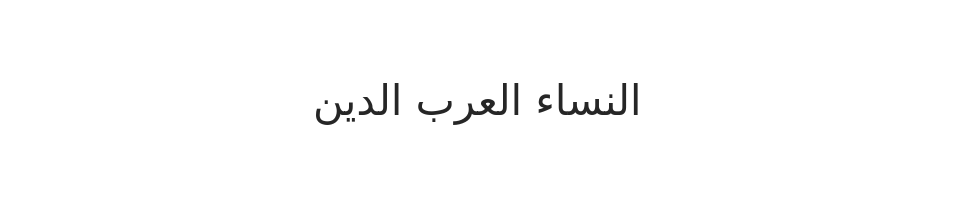

In [41]:

from matplotlib import font_manager
from pathlib import Path
import matplotlib.pyplot as plt
import arabic_reshaper
from bidi.algorithm import get_display

# Chercher les polices disponibles sur Kaggle
fonts = font_manager.findSystemFonts(fontext="ttf")

# Privilégier les polices qui prennent en charge l'arabe
preferred = [
    "DejaVuSans.ttf",
    "NotoNaskhArabic-Regular.ttf",
    "NotoSansArabic-Regular.ttf",
    "Amiri-Regular.ttf"
]

font_path = None

for name in preferred:
    matches = [
        f for f in fonts
        if Path(f).name.lower() == name.lower()
    ]
    if matches:
        font_path = matches[0]
        break

if font_path is None:
    raise RuntimeError(
        "Aucune police arabe compatible trouvée."
    )

font_manager.fontManager.addfont(font_path)

arabic_font = font_manager.FontProperties(
    fname=font_path
)

print("Police sélectionnée :", font_path)
print("Nom :", arabic_font.get_name())

def fix_arabic(text):
    return get_display(
        arabic_reshaper.reshape(str(text))
    )

# Test d'affichage
fig, ax = plt.subplots(figsize=(10, 2))

ax.text(
    0.5, 0.5,
    fix_arabic("النساء العرب الدين"),
    fontproperties=arabic_font,
    fontsize=25,
    ha="center",
    va="center"
)

ax.axis("off")
plt.show()


## Exploration lexicale arabe

/tmp/ipykernel_49/2790358414.py:87: UserWarning: Glyph 65010 (\N{ARABIC LIGATURE ALLAH ISOLATED FORM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_49/2790358414.py:89: UserWarning: Glyph 65010 (\N{ARABIC LIGATURE ALLAH ISOLATED FORM}) missing from font(s) DejaVu Sans.
  plt.savefig(
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 65010 (\N{ARABIC LIGATURE ALLAH ISOLATED FORM}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


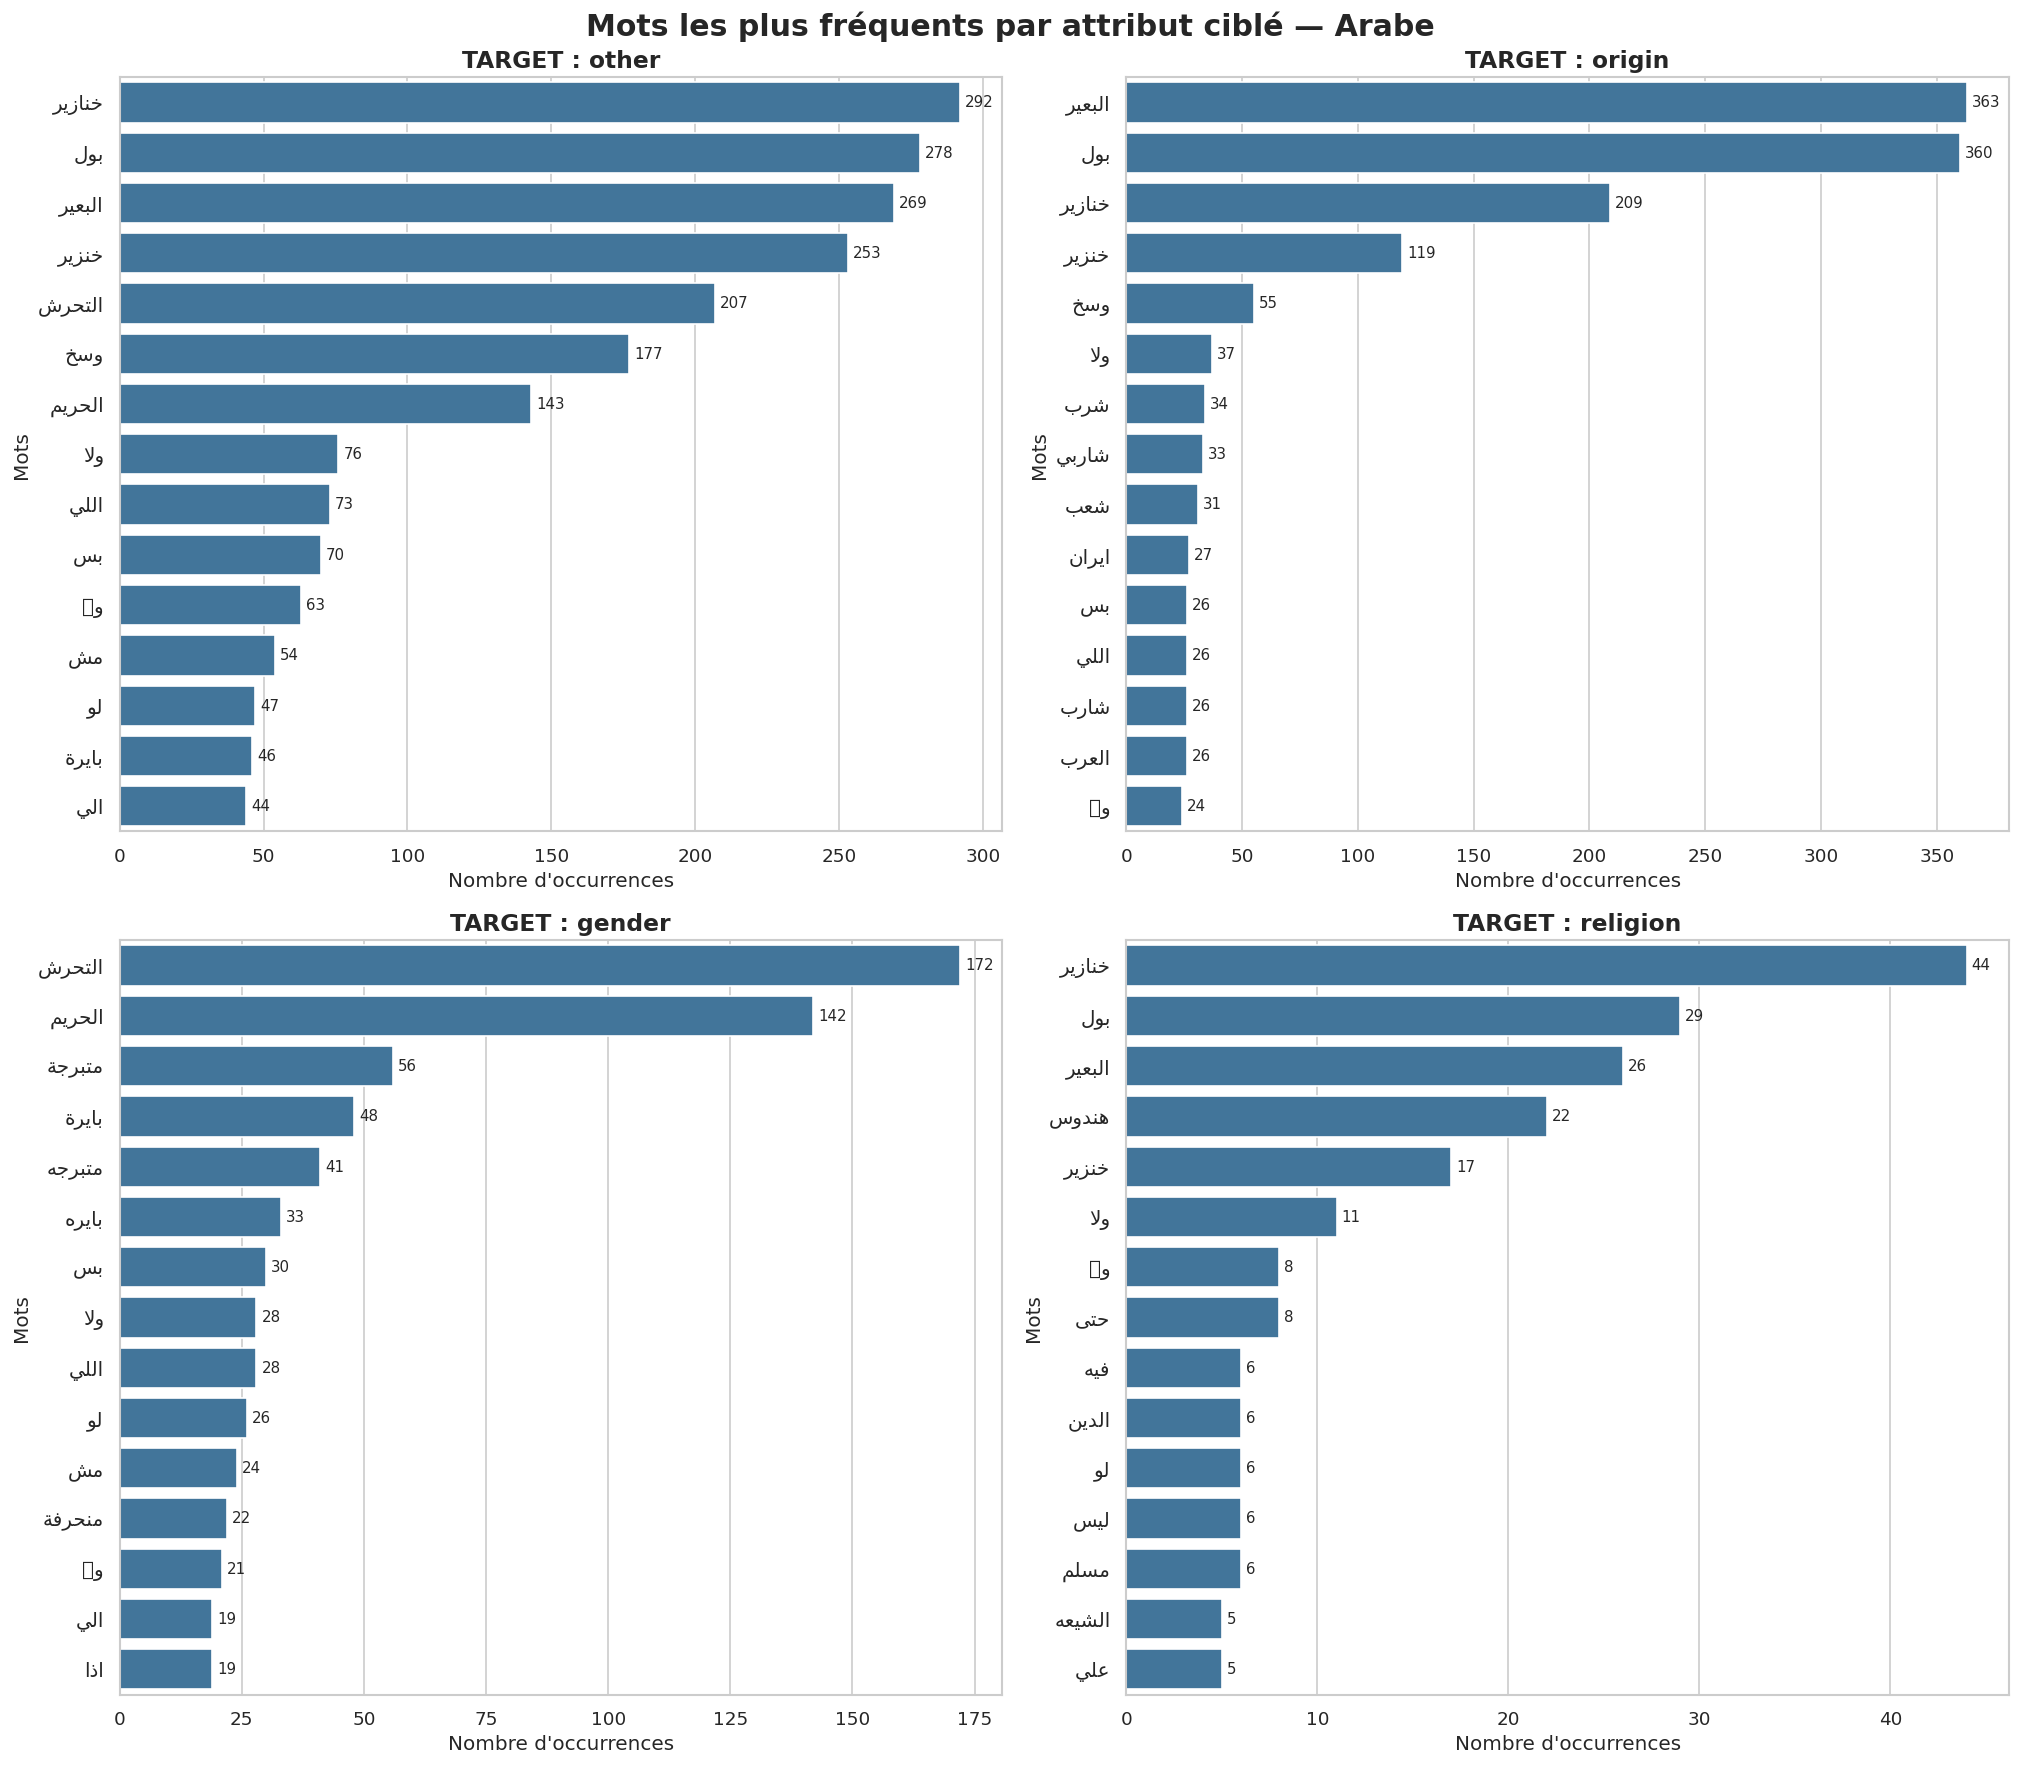

In [42]:

import re
import math
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from pathlib import Path

FIG_DIR = Path("/kaggle/working/figures/text_eda")
FIG_DIR.mkdir(parents=True, exist_ok=True)

df_ar_clean = cleaned_datasets["Arabe"].copy()

# Stopwords de base pour l'analyse uniquement
stopwords_ar = {
    "في", "من", "على", "الى", "إلى", "عن",
    "هذا", "هذه", "ذلك", "التي", "الذي",
    "هو", "هي", "هم", "ان", "أن", "كان",
    "ما", "لا", "لم", "لن", "و", "او",
    "أو", "يا", "مع", "كل", "بعد", "قبل",
    "انا", "انت", "أنت", "الله"
}

def tokenize_arabic(text):
    text = str(text).lower()

    # Exclure les marqueurs techniques pour la visualisation
    text = re.sub(
        r"@user\b|@url\b|https?://\S+",
        " ", text, flags=re.IGNORECASE
    )

    # Extraire les mots arabes
    words = re.findall(r"[\u0621-\u064A]+", text)

    return [
        w for w in words
        if w not in stopwords_ar and len(w) > 1
    ]

targets = df_ar_clean["target"].value_counts().index.tolist()

fig, axes = plt.subplots(
    2, 2, figsize=(17, 15)
)
axes = axes.flatten()

for ax, target in zip(axes, targets):

    tweets = df_ar_clean.loc[
        df_ar_clean["target"] == target, "tweet"
    ]

    tokens = []
    for tweet in tweets:
        tokens.extend(tokenize_arabic(tweet))

    top_words = Counter(tokens).most_common(15)

    if top_words:
        words, freqs = zip(*top_words)

        sns.barplot(
            x=list(freqs),
            y=[fix_arabic(w) for w in words],
            color="#3478A8",
            ax=ax
        )

        for label in ax.get_yticklabels():
            label.set_fontproperties(arabic_font)

        for container in ax.containers:
            ax.bar_label(container, padding=3, fontsize=9)

    ax.set_title(f"TARGET : {target}", fontsize=14, fontweight="bold")
    ax.set_xlabel("Nombre d'occurrences")
    ax.set_ylabel("Mots")

# Retirer les panneaux inutilisés
for ax in axes[len(targets):]:
    ax.set_visible(False)

plt.suptitle(
    "Mots les plus fréquents par attribut ciblé — Arabe",
    fontsize=18, fontweight="bold"
)
plt.tight_layout()

plt.savefig(
    FIG_DIR / "arabic_top_words_by_target.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


/tmp/ipykernel_49/2902597531.py:68: UserWarning: Glyph 65010 (\N{ARABIC LIGATURE ALLAH ISOLATED FORM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_49/2902597531.py:69: UserWarning: Glyph 65010 (\N{ARABIC LIGATURE ALLAH ISOLATED FORM}) missing from font(s) DejaVu Sans.
  plt.savefig(
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 65010 (\N{ARABIC LIGATURE ALLAH ISOLATED FORM}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


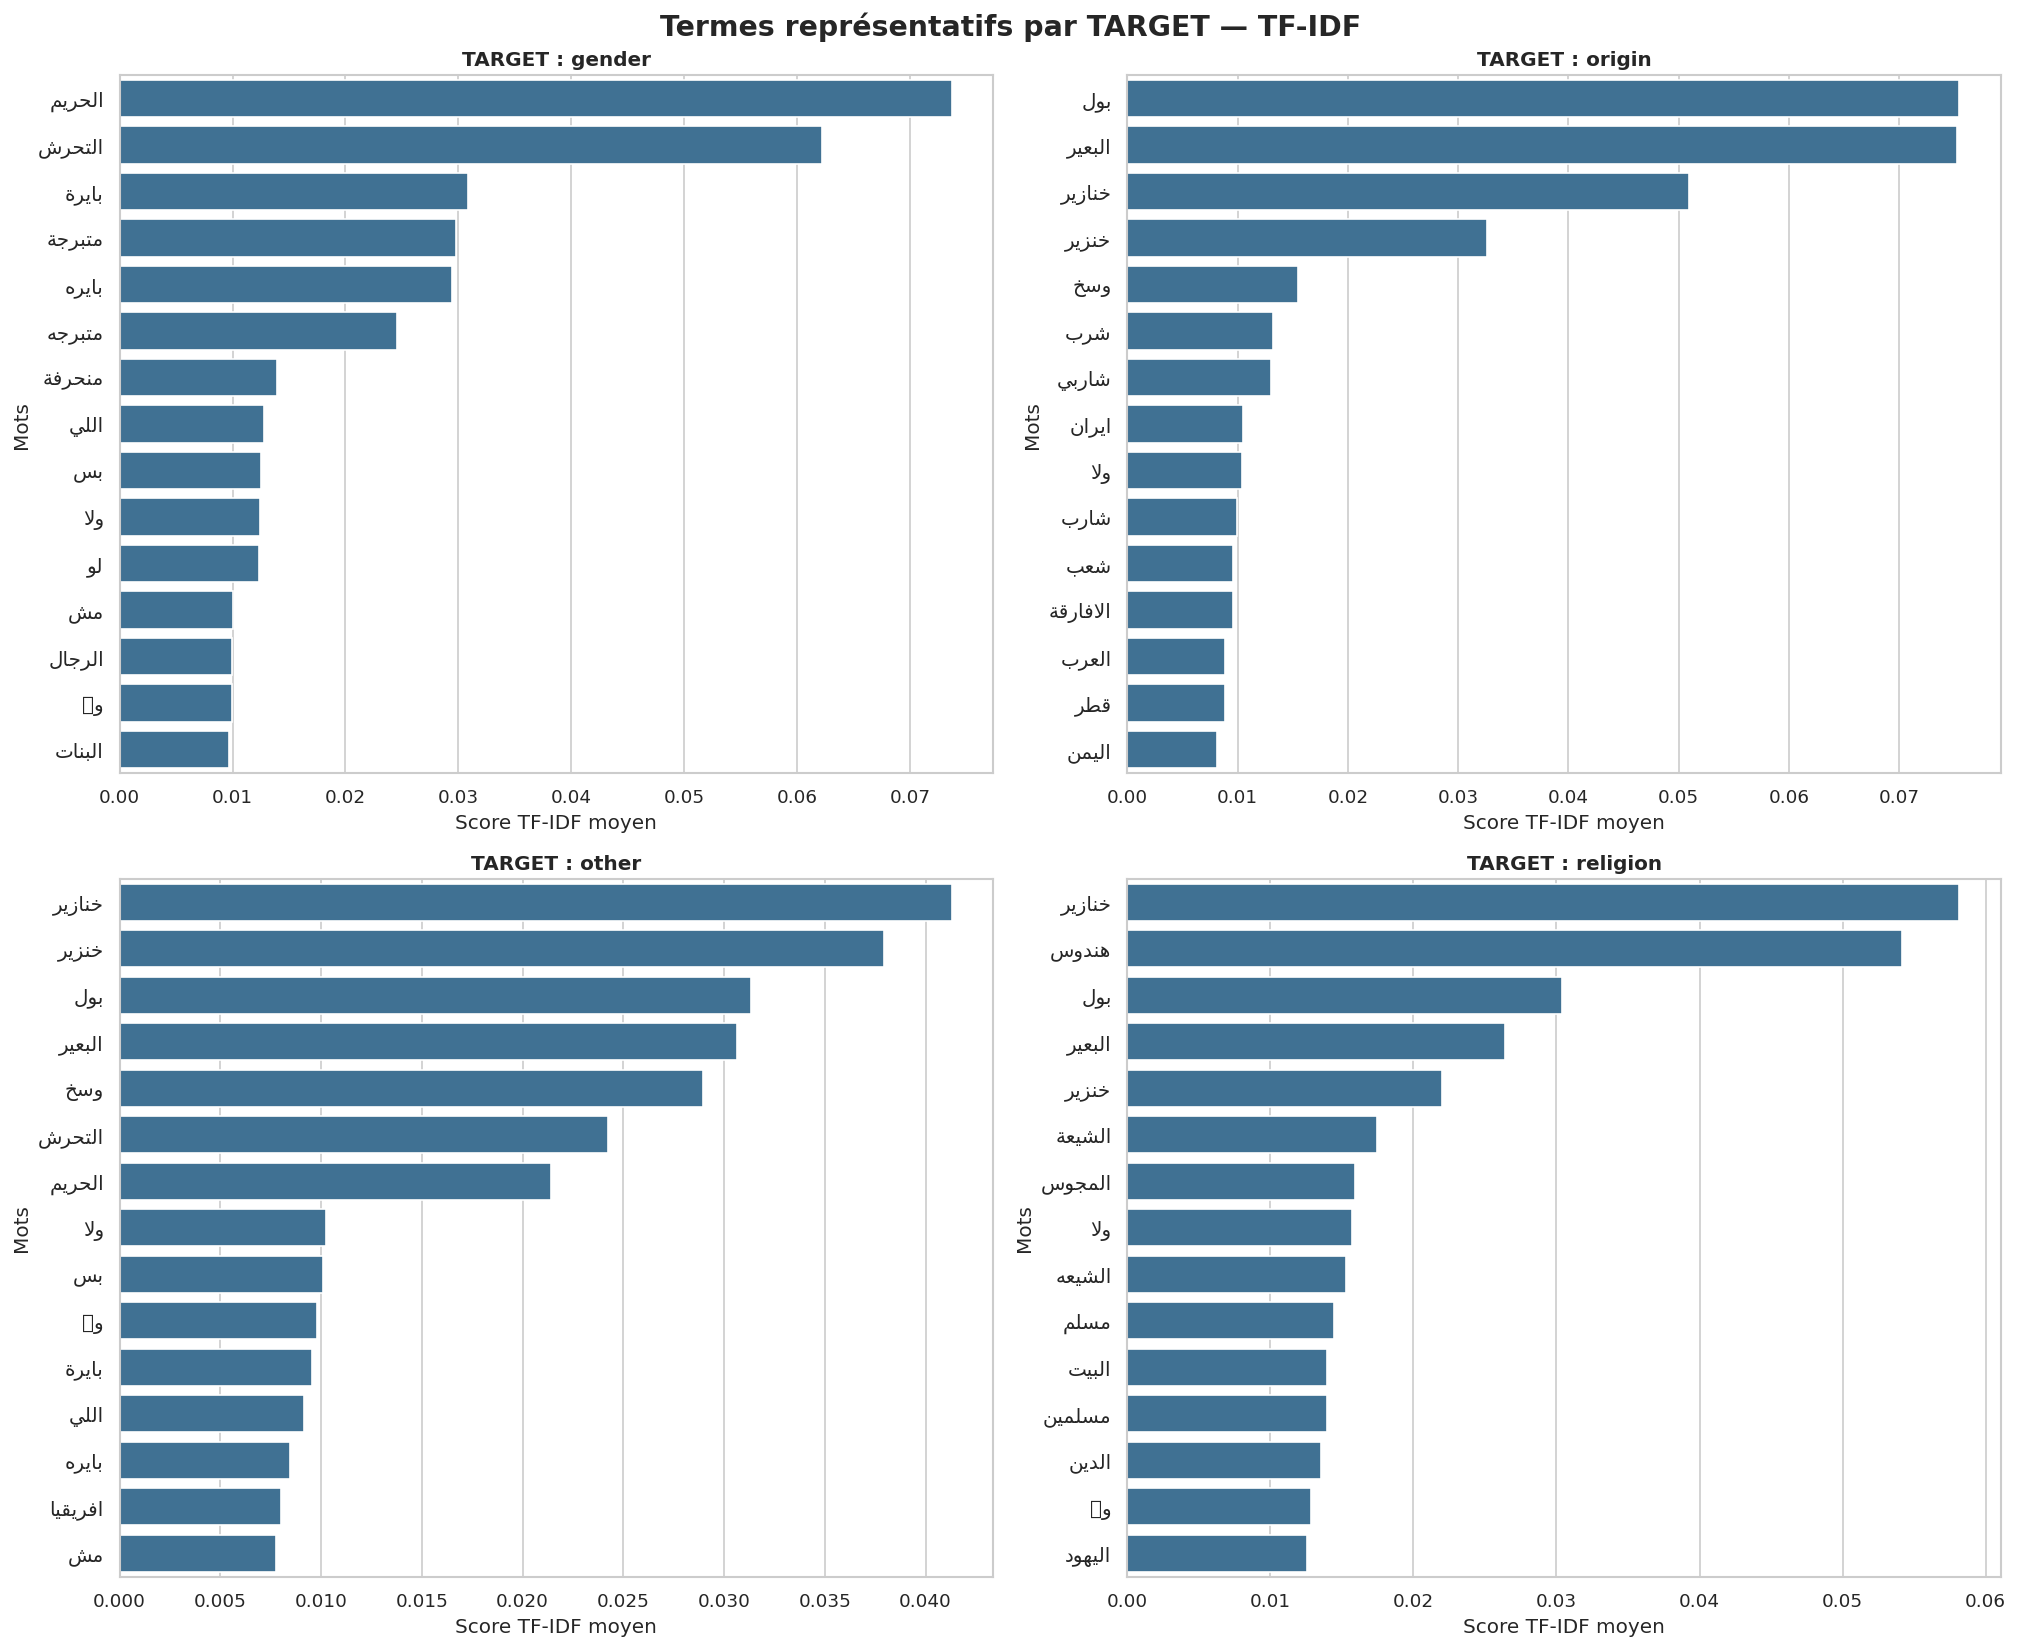

In [43]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from pathlib import Path

FIG_DIR = Path("/kaggle/working/figures/text_eda")
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = cleaned_datasets["Arabe"].copy()

# Utiliser le tokenizer arabe précédent
vectorizer = TfidfVectorizer(
    tokenizer=tokenize_arabic,
    token_pattern=None,
    lowercase=False,
    min_df=2,
    max_features=5000,
    sublinear_tf=True
)

X = vectorizer.fit_transform(df["tweet"].astype(str))
feature_names = np.array(vectorizer.get_feature_names_out())

targets = sorted(df["target"].unique())

fig, axes = plt.subplots(2, 2, figsize=(17, 14))
axes = axes.flatten()

for ax, target in zip(axes, targets):

    mask = (df["target"].to_numpy() == target)

    # Score TF-IDF moyen pour les tweets de la classe
    mean_scores = np.asarray(
        X[mask].mean(axis=0)
    ).ravel()

    top_idx = np.argsort(mean_scores)[-15:][::-1]

    words = feature_names[top_idx]
    scores = mean_scores[top_idx]

    sns.barplot(
        x=scores,
        y=[fix_arabic(w) for w in words],
        ax=ax,
        color="#3274A1"
    )

    for label in ax.get_yticklabels():
        label.set_fontproperties(arabic_font)

    ax.set_title(f"TARGET : {target}", fontweight="bold")
    ax.set_xlabel("Score TF-IDF moyen")
    ax.set_ylabel("Mots")

for ax in axes[len(targets):]:
    ax.set_visible(False)

plt.suptitle(
    "Termes représentatifs par TARGET — TF-IDF",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig(
    FIG_DIR / "arabic_tfidf_by_target.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [44]:

arabic_keywords = [
    "اللاجئون", "اللاجئون ضرر", "اللاجئون خطر",
    "اللاجئون و الامراض", "افارقة ايبولا",
    "افارقة كوليرا", "افارقة مرض", "خنازير",
    "حرمة قاصر", "سوري وسخ", "هندوس",
    "بايرة", "مراة عورة", "مراة متسلطة",
    "شينغ شونغ", "لاجئ وسخ", "مراة قاصر",
    "افارقة نجس", "افارقة وسخ", "عرب وسخ",
    "بول البعير", "سواقة حريم", "خنزير وسخ",
    "منحرفة", "العادات و التقاليد", "الحريم",
    "بهيم", "الافارقة السود", "متبرجة",
    "الزواج و الطلاق للمراة", "ديوث",
    "فمينيست", "العنف", "اسقاط ولاية المراة",
    "الصينيون", "افريقيا السمراء", "التحرش",
    "افريقيا اغبياء", "منغول", "مغول",
    "وسخ", "شيعة", "ايران وسخ",
    "طائفة", "طائفي", "علماني", "جهاد",
    "كحالش", "معاق ذهني", "شيعة رافضة",
    "شيعي", "رافضي", "علوي", "اكراد",
    "لجوء", "احتلال", "لاجئ احتلال",
    "مثلية", "مثليين", "كلب", "ايران",
    "فارسي وسخ"
]

arabic_keywords = list(dict.fromkeys(arabic_keywords))

print("Expressions de référence :", len(arabic_keywords))


Expressions de référence : 62


In [45]:

import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df_kw = cleaned_datasets["Arabe"].copy()

def normalize_keyword_text(text):
    text = str(text)
    text = re.sub(r"[\u064B-\u065F\u0670]", "", text)
    text = re.sub(r"[إأآٱ]", "ا", text)
    text = re.sub(r"ـ", "", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip().lower()

df_kw["text_norm"] = df_kw["tweet"].apply(normalize_keyword_text)

def keyword_present(text, keyword):
    keyword = normalize_keyword_text(keyword)
    parts = [re.escape(p) for p in keyword.split()]
    pattern = r"(?<!\w)" + r"\s+".join(parts) + r"(?!\w)"
    return bool(re.search(pattern, text))

results = []

for keyword in arabic_keywords:
    mask = df_kw["text_norm"].apply(
        lambda text: keyword_present(text, keyword)
    )

    subset = df_kw.loc[mask]

    results.append({
        "keyword": keyword,
        "n_tweets": int(mask.sum()),
        **{
            f"target_{target}": int((subset["target"] == target).sum())
            for target in sorted(df_kw["target"].unique())
        }
    })

keyword_stats = pd.DataFrame(results)
keyword_stats = keyword_stats.sort_values(
    "n_tweets", ascending=False
).reset_index(drop=True)

display(keyword_stats.head(30))

keyword_stats.to_csv(
    "/kaggle/working/keyword_target_analysis.csv",
    index=False,
    encoding="utf-8-sig"
)


,keyword,n_tweets,target_gender,target_origin,target_other,target_religion
0,بول البعير,626,4,345,253,24
1,خنازير,537,1,204,288,44
2,التحرش,380,166,13,196,5
3,الحريم,298,140,17,140,1
4,وسخ,239,6,54,177,2
5,متبرجة,101,56,2,39,4
6,بايرة,92,45,3,44,0
7,منحرفة,67,22,6,36,3
8,هندوس,65,1,2,39,23
9,ايران,45,0,34,7,4


## Analyse des caractéristiques Twitter

In [46]:
from pathlib import Path

files = list(Path("/kaggle").rglob("*.csv"))

for file in files:
    print(file)

/kaggle/working/keyword_target_analysis.csv
/kaggle/working/cleaned_data/fr_conflicts.csv
/kaggle/working/cleaned_data/fr_clean.csv
/kaggle/working/cleaned_data/en_clean.csv
/kaggle/working/cleaned_data/cleaning_summary.csv
/kaggle/working/cleaned_data/ar_clean.csv
/kaggle/working/cleaned_data/en_conflicts.csv
/kaggle/working/cleaned_data/ar_conflicts.csv
/kaggle/working/mlma_data/extracted/hate_speech_mlma/ar_dataset.csv
/kaggle/working/mlma_data/extracted/hate_speech_mlma/en_dataset_with_stop_words.csv
/kaggle/working/mlma_data/extracted/hate_speech_mlma/en_dataset.csv
/kaggle/working/mlma_data/extracted/hate_speech_mlma/fr_dataset.csv


(3347, 13)
['HITId', 'tweet', 'sentiment', 'directness', 'annotator_sentiment', 'target', 'group', 'sentiment_abusive', 'sentiment_hateful', 'sentiment_offensive', 'sentiment_normal', 'sentiment_disrespectful', 'sentiment_fearful']


,Élément,Tweets,Pourcentage
0,Mentions (@user),2305,68.87
1,URL (@url / http),1067,31.88
2,Emojis,5,0.15


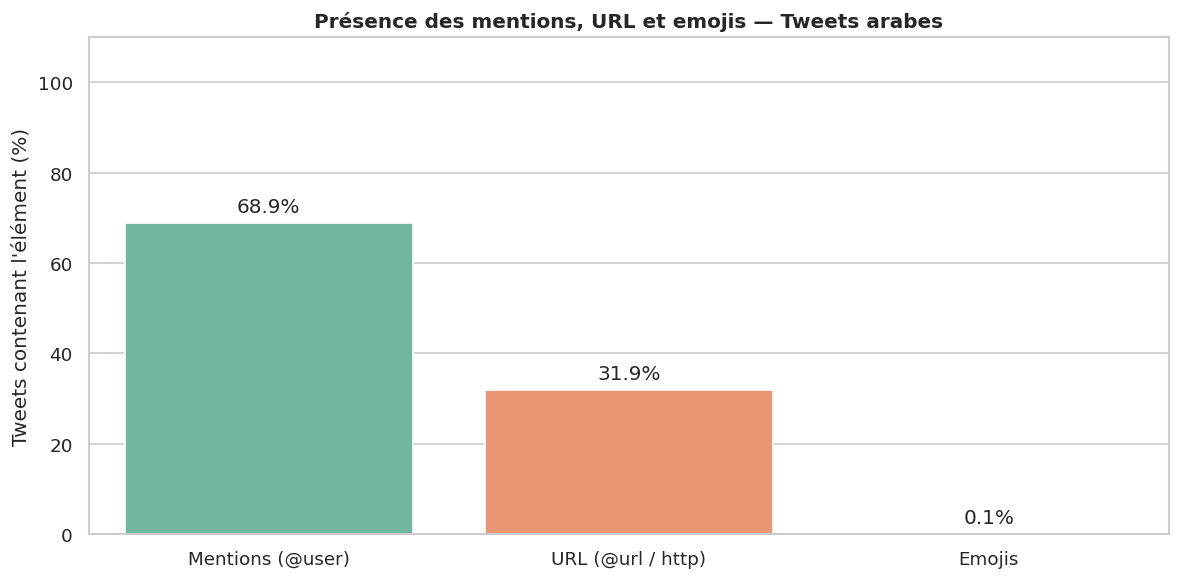

In [47]:
import pandas as pd

df_ar_eda = cleaned_datasets["Arabe"].copy()

print(df_ar_eda.shape)
print(df_ar_eda.columns.tolist())

# Caractéristiques Twitter calculées sur le texte original
import re

original_texts = df_ar_eda["tweet"].fillna("").astype(str)

df_ar_eda["has_mentions"] = original_texts.str.contains(
    r"@(?:user\b|[A-Za-z0-9_]+)", case=False, regex=True
)
df_ar_eda["has_urls"] = original_texts.str.contains(
    r"@url\b|https?://|www\.", case=False, regex=True
)
df_ar_eda["has_emojis"] = original_texts.str.contains(
    r"[\U0001F300-\U0001FAFF\u2600-\u27BF]", regex=True
)

features = {
    "Mentions (@user)": "has_mentions",
    "URL (@url / http)": "has_urls",
    "Emojis": "has_emojis"
}

summary_features = pd.DataFrame([
    {
        "Élément": label,
        "Tweets": int(df_ar_eda[col].sum()),
        "Pourcentage": df_ar_eda[col].mean() * 100
    }
    for label, col in features.items()
])

display(summary_features.round(2))

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=summary_features,
    x="Élément",
    y="Pourcentage",
    hue="Élément",
    palette="Set2",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=4)

plt.title("Présence des mentions, URL et emojis — Tweets arabes")
plt.xlabel("")
plt.ylabel("Tweets contenant l'élément (%)")
plt.ylim(0, 110)

plt.tight_layout()
plt.savefig(FIG_DIR / "arabic_twitter_features.png", dpi=300)
plt.show()


,Mentions,URL,Emojis
target,,,
gender,60.44,34.43,0.37
origin,82.90,31.58,0.00
other,63.41,30.97,0.17
religion,82.76,35.17,0.00


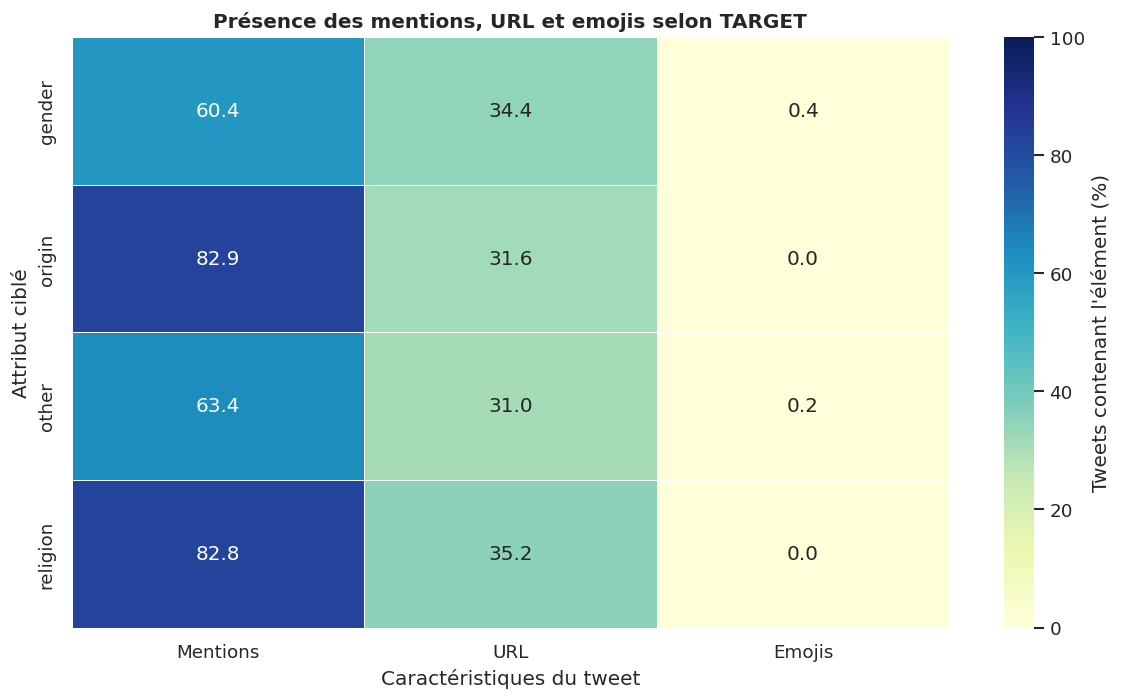

In [48]:

feature_cols = [
    "has_mentions",
    "has_urls",
    "has_emojis"
]

target_features = (
    df_ar_eda.groupby("target")[feature_cols]
    .mean()
    .mul(100)
)

target_features.columns = [
    "Mentions",
    "URL",
    "Emojis"
]

display(target_features.round(2))

plt.figure(figsize=(10, 6))

sns.heatmap(
    target_features,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar_kws={"label": "Tweets contenant l'élément (%)"}
)

plt.title("Présence des mentions, URL et emojis selon TARGET")
plt.xlabel("Caractéristiques du tweet")
plt.ylabel("Attribut ciblé")

plt.tight_layout()
plt.savefig(FIG_DIR / "arabic_twitter_target_heatmap.png", dpi=300)
plt.show()


In [49]:

from collections import Counter
import re

df = df_ar_eda.copy()

def extract_hashtags(text):
    return re.findall(
        r"(?<!\w)#[\w]+",
        str(text),
        flags=re.UNICODE
    )

df["hashtags"] = df["tweet"].apply(extract_hashtags)
df["n_hashtags"] = df["hashtags"].apply(len)
df["has_hashtag"] = df["n_hashtags"] > 0

print("Tweets avec hashtags :", df["has_hashtag"].sum())
print(
    "Pourcentage :",
    round(df["has_hashtag"].mean() * 100, 2),
    "%"
)

all_hashtags = [
    tag
    for tags in df["hashtags"]
    for tag in tags
]

top_hashtags = Counter(all_hashtags).most_common(20)

display(
    pd.DataFrame(
        top_hashtags,
        columns=["Hashtag", "Fréquence"]
    )
)

print("\nPrésence des hashtags selon TARGET :")

display(
    (
        df.groupby("target")["has_hashtag"]
        .mean() * 100
    ).round(2)
)


Tweets avec hashtags : 190
Pourcentage : 5.68 %


,Hashtag,Fréquence
0,#افريقيا_يا_اهلي,9
1,#التحرش,9
2,#ديوث,7
3,#في_بلادك_تقدري,6
4,#معصيتي_راحتي,6
5,#بول_البعير,5
6,#غرد_مثل_موقع_القوات,3
7,#عمه,3
8,#العراق,3
9,#عدوان_خنازير_الخليج,3



Présence des hashtags selon TARGET :


target
gender      6.78
origin      5.70
other       5.45
religion    4.14
Name: has_hashtag, dtype: float64

In [50]:

import pandas as pd

df = cleaned_datasets["Arabe"].copy()

# Caractère Tatweel Unicode U+0640
tatweel = "\u0640"

# Détecter les tweets contenant du Tatweel
df["has_tatweel"] = df["tweet"].str.contains(
    tatweel, regex=False, na=False
)

# Nombre de Tatweel dans chaque tweet
df["n_tatweel"] = df["tweet"].str.count(tatweel)

n_total = len(df)
n_tweets = int(df["has_tatweel"].sum())
n_chars = int(df["n_tatweel"].sum())

print("===== ANALYSE DU TATWEEL =====")
print("Tweets totaux :", n_total)
print("Tweets avec Tatweel :", n_tweets)
print("Pourcentage :", round(n_tweets / n_total * 100, 2), "%")
print("Nombre total de caractères Tatweel :", n_chars)

print("\nExemples de tweets avec Tatweel :")
display(
    df.loc[
        df["has_tatweel"],
        ["tweet", "target", "n_tatweel"]
    ].head(15)
)


===== ANALYSE DU TATWEEL =====
Tweets totaux : 3347
Tweets avec Tatweel : 19
Pourcentage : 0.57 %
Nombre total de caractères Tatweel : 37

Exemples de tweets avec Tatweel :


,tweet,target,n_tatweel
47,مدينة بورنهايم بالـ المانيا تمنع اللاجئين العر...,other,1
197,مصادر بالمفوضية : اللاجئون السوريون بحاجة لـ 9...,other,1
426,واحتسي من شفتي الخمر كمَ أشًتَهـًـيَ تًمزَيقً ...,other,6
450,من قال أن الوطن لم يمت بموته فـ لينظر لـ خنازي...,origin,2
676,من قال أن الوطن لم يمت بموته فـ لينظر لـ خنازي...,origin,2
758,وعلـمـتني بان فالهند هـنـدوس ٍ مجوس وكـ…,religion,5
1432,سوسة: الاحتفاظ بحارس مركب طفولة بتهمة التحرش ب...,gender,1
1618,ولا المراجل ما تجي بـ طعن الحريم .,gender,1
1857,شـعرة من جلد خنزير,other,1
1908,@user لا لا ماعارف وكنت منتظركم تجو توروني وهس...,gender,1


# Cleaning 

In [51]:

import re
import emoji
import pandas as pd

def clean_arabic(text):
    text = str(text)

    # 1. Supprimer les URL
    text = re.sub(
        r"https?://\S+|www\.\S+|@url\b",
        " ", text, flags=re.IGNORECASE
    )

    # 2. Conserver les mentions sous forme USER
    text = re.sub(
        r"@user\b", " USER ", text, flags=re.IGNORECASE
    )

    # 3. Supprimer les emojis
    text = emoji.replace_emoji(text, replace=" ")

    # 4. Supprimer uniquement #
    text = re.sub(r"(?<!\w)#(?=\w)", "", text)

    # 5. Supprimer les diacritiques arabes
    text = re.sub(r"[\u064B-\u065F\u0670]", "", text)

    # 6. Supprimer le Tatweel
    text = text.replace("ـ", "")

    # 7. Normaliser Alif
    text = re.sub(r"[أإآٱ]", "ا", text)

    # 8. Normaliser les espaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

# Dataset arabe déjà nettoyé des doublons
df_ar_final = cleaned_datasets["Arabe"].copy()

# Créer une nouvelle colonne
df_ar_final["tweet_clean"] = (
    df_ar_final["tweet"].apply(clean_arabic)
)

display(
    df_ar_final[
        ["tweet", "tweet_clean", "target"]
    ].head(10)
)


,tweet,tweet_clean,target
0,صلاة الفجر خير لك من ترديد بول البعير وسبي الن...,صلاة الفجر خير لك من ترديد بول البعير وسبي الن...,gender
1,صراحة نفسي اشوف ولاد الوسخة اللي قالوا مدرب اج...,صراحة نفسي اشوف ولاد الوسخة اللي قالوا مدرب اج...,other
2,طيب! هي متبرجة وعبايتها ملونه وطالعة من بيتهم ...,طيب! هي متبرجة وعبايتها ملونه وطالعة من بيتهم ...,other
3,@user @user انا اوافقك بخصوص السوريين و العراق...,USER USER انا اوافقك بخصوص السوريين و العراقيي...,origin
4,هذه السعودية التي شعبها شعب الخيم و بول البعير...,هذه السعودية التي شعبها شعب الخيم و بول البعير...,origin
5,ما عارف كنت شايفها منحرفة شديد وانا صغير ليه @url,ما عارف كنت شايفها منحرفة شديد وانا صغير ليه,gender
6,@user @user تخيل يرد عليك يقولك حسب معلوماتنا ...,USER USER تخيل يرد عليك يقولك حسب معلوماتنا ان...,other
7,صباح التوكل على الله والسعي على رزقه والثقة في...,صباح التوكل على الله والسعي على رزقه والثقة في...,other
8,وانتي مال امك يا مطلقة يا بايرة ياوش قنوات @url,وانتي مال امك يا مطلقة يا بايرة ياوش قنوات,gender
9,@user @user الكردي كلب من يوم يومه بحاجة دائما...,USER USER الكردي كلب من يوم يومه بحاجة دائما ل...,origin


In [52]:

print("Tweets totaux :", len(df_ar_final))

print("Tweets modifiés :",
      (df_ar_final["tweet"] != df_ar_final["tweet_clean"]).sum())

print("Tweets vides :",
      df_ar_final["tweet_clean"].eq("").sum())

print("Doublons après nettoyage :",
      df_ar_final["tweet_clean"].duplicated().sum())

# Sauvegarder
df_ar_final.to_csv(
    "/kaggle/working/cleaned_data/ar_final.csv",
    index=False,
    encoding="utf-8-sig"
)


Tweets totaux : 3347
Tweets modifiés : 2781
Tweets vides : 0
Doublons après nettoyage : 7


In [53]:

# Afficher les tweets devenus identiques après nettoyage
doublons = df_ar_final[
    df_ar_final.duplicated(subset="tweet_clean", keep=False)
].sort_values("tweet_clean")

display(
    doublons[["HITId", "tweet", "tweet_clean", "target"]]
)

# Vérifier les contradictions
print("Groupes avec TARGET contradictoire :",
    (doublons.groupby("tweet_clean")["target"].nunique() > 1).sum()
)


,HITId,tweet,tweet_clean,target
151,152,تحمل اللاجئون السوريون شدة البرد والحر، لكن تو...,تحمل اللاجئون السوريون شدة البرد والحر، لكن تو...,origin
253,254,تحمل اللاجئون السوريون شدة البرد والحر، لكن تو...,تحمل اللاجئون السوريون شدة البرد والحر، لكن تو...,origin
1857,1862,شـعرة من جلد خنزير,شعرة من جلد خنزير,other
2378,2385,شعرة مـن جـلد خنزير,شعرة من جلد خنزير,other
2435,2442,شعرة من جلد خنزير,شعرة من جلد خنزير,other
2139,2146,قانون التحرش الجنسي يصطاد أول ضحية له من الحسي...,قانون التحرش الجنسي يصطاد اول ضحية له من الحسيمة,other
2234,2241,قانون التحرش الجنسي يصطاد أول ضحية له من الحسي...,قانون التحرش الجنسي يصطاد اول ضحية له من الحسيمة,gender
1691,1696,لاجيت أعاتبك طيّحت الحطب كله,لاجيت اعاتبك طيحت الحطب كله,other
2148,2155,لاجيت أعاتبك طيّحت الحطب كلّه,لاجيت اعاتبك طيحت الحطب كله,other
144,145,ماساكتاش.. هل ستقي الصافرة المغربيات شر التحرش...,ماساكتاش.. هل ستقي الصافرة المغربيات شر التحرش؟,other


Groupes avec TARGET contradictoire : 3


In [54]:

from pathlib import Path

# Copier le dataset
df_ar_ready = df_ar_final.copy()

# Garder uniquement la première occurrence
df_ar_ready = df_ar_ready.drop_duplicates(
    subset="tweet_clean",
    keep="first"
).reset_index(drop=True)

# Enregistrer le dataset final
OUTPUT = Path("/kaggle/working/cleaned_data/ar_ready.csv")
OUTPUT.parent.mkdir(parents=True, exist_ok=True)

df_ar_ready.to_csv(
    OUTPUT,
    index=False,
    encoding="utf-8-sig"
)

# Vérification
print("Tweets avant :", len(df_ar_final))
print("Tweets après :", len(df_ar_ready))
print("Doublons supprimés :", len(df_ar_final) - len(df_ar_ready))
print("Doublons restants :", df_ar_ready["tweet_clean"].duplicated().sum())

print("\nDistribution finale de TARGET :")
print(df_ar_ready["target"].value_counts())

print("\nDataset enregistré :", OUTPUT)

display(df_ar_ready.head())


Tweets avant : 3347
Tweets après : 3340
Doublons supprimés : 7
Doublons restants : 0

Distribution finale de TARGET :
target
other       1776
origin       875
gender       544
religion     145
Name: count, dtype: int64

Dataset enregistré : /kaggle/working/cleaned_data/ar_ready.csv


,HITId,tweet,sentiment,directness,annotator_sentiment,target,group,sentiment_abusive,sentiment_hateful,sentiment_offensive,sentiment_normal,sentiment_disrespectful,sentiment_fearful,tweet_clean
0,1,صلاة الفجر خير لك من ترديد بول البعير وسبي الن...,hateful_normal,indirect,shock,gender,individual,0,1,0,1,0,0,صلاة الفجر خير لك من ترديد بول البعير وسبي الن...
1,2,صراحة نفسي اشوف ولاد الوسخة اللي قالوا مدرب اج...,offensive,indirect,anger_confusion_sadness_indifference_disgust,other,other,0,0,1,0,0,0,صراحة نفسي اشوف ولاد الوسخة اللي قالوا مدرب اج...
2,3,طيب! هي متبرجة وعبايتها ملونه وطالعة من بيتهم ...,offensive,indirect,indifference,other,individual,0,0,1,0,0,0,طيب! هي متبرجة وعبايتها ملونه وطالعة من بيتهم ...
3,4,@user @user انا اوافقك بخصوص السوريين و العراق...,normal,direct,indifference,origin,other,0,0,0,1,0,0,USER USER انا اوافقك بخصوص السوريين و العراقيي...
4,5,هذه السعودية التي شعبها شعب الخيم و بول البعير...,normal,indirect,indifference,origin,other,0,0,0,1,0,0,هذه السعودية التي شعبها شعب الخيم و بول البعير...


# Entrainment


In [55]:

import os
import random
import numpy as np
import pandas as pd
import torch

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device :", device)

# Charger le dataset arabe final
df = df_ar_ready.copy().reset_index(drop=True)

# Séparation stratifiée 80 / 10 / 10
train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["target"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["target"],
    random_state=SEED
)

# Encoder la cible
label_encoder = LabelEncoder()
label_encoder.fit(train_df["target"])

y_train = label_encoder.transform(train_df["target"])
y_val = label_encoder.transform(val_df["target"])

print("Train :", len(train_df))
print("Validation :", len(val_df))
print("Test scellé :", len(test_df))

print("\nClasses :", label_encoder.classes_)


Device : cuda
Train : 2672
Validation : 334
Test scellé : 334

Classes : ['gender' 'origin' 'other' 'religion']


In [56]:
train_df.head()

,HITId,tweet,sentiment,directness,annotator_sentiment,target,group,sentiment_abusive,sentiment_hateful,sentiment_offensive,sentiment_normal,sentiment_disrespectful,sentiment_fearful,tweet_clean
1355,1360,@user @user فيه خنازير تروح,abusive_offensive,indirect,indifference,other,other,1,0,1,0,0,0,USER USER فيه خنازير تروح
3056,3070,@user يا كداب يا وسخ,offensive,direct,indifference_disgust,other,individual,0,0,1,0,0,0,USER يا كداب يا وسخ
2896,2910,@user هههههههههههه سهل الوسخ بايجلس وسخ ولو تح...,offensive,indirect,indifference_disgust,other,other,0,0,1,0,0,0,USER هههههههههههه سهل الوسخ بايجلس وسخ ولو تحم...
751,753,انا ما اقول مجانين لما اشوف هندوس في نهر الغان...,disrespectful_normal,direct,confusion_disgust,other,other,0,0,0,1,1,0,انا ما اقول مجانين لما اشوف هندوس في نهر الغان...
2668,2682,@user ١- جسم المرأة لا حق لأحد عليه تبرجت أو لا,normal,indirect,indifference,other,women,0,0,0,1,0,0,USER ١- جسم المراة لا حق لاحد عليه تبرجت او لا


# Charger et geler MARBERTv2

In [57]:

from transformers import AutoTokenizer, AutoModel

MODEL_NAME = "UBC-NLP/MARBERTv2"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

marbert = AutoModel.from_pretrained(
    MODEL_NAME
).to(device)

# Geler tous les paramètres
for param in marbert.parameters():
    param.requires_grad = False

marbert.eval()

print("Modèle :", MODEL_NAME)
print("Hidden size :", marbert.config.hidden_size)
print("Couches :", marbert.config.num_hidden_layers)

print(
    "Paramètres entraînables :",
    sum(p.numel() for p in marbert.parameters()
        if p.requires_grad)
)


config.json:   0%|          | 0.00/757 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/439 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.10M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  654MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  654MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: UBC-NLP/MARBERTv2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Modèle : UBC-NLP/MARBERTv2
Hidden size : 768
Couches : 12
Paramètres entraînables : 0


In [58]:

df = df_ar_ready.copy()

print("Dimensions :", df.shape)
print("Colonnes :", df.columns.tolist())

print("\nDistribution TARGET :")
print(df["target"].value_counts())

display(df[["tweet_clean", "target"]].head())


Dimensions : (3340, 14)
Colonnes : ['HITId', 'tweet', 'sentiment', 'directness', 'annotator_sentiment', 'target', 'group', 'sentiment_abusive', 'sentiment_hateful', 'sentiment_offensive', 'sentiment_normal', 'sentiment_disrespectful', 'sentiment_fearful', 'tweet_clean']

Distribution TARGET :
target
other       1776
origin       875
gender       544
religion     145
Name: count, dtype: int64


,tweet_clean,target
0,صلاة الفجر خير لك من ترديد بول البعير وسبي الن...,gender
1,صراحة نفسي اشوف ولاد الوسخة اللي قالوا مدرب اج...,other
2,طيب! هي متبرجة وعبايتها ملونه وطالعة من بيتهم ...,other
3,USER USER انا اوافقك بخصوص السوريين و العراقيي...,origin
4,هذه السعودية التي شعبها شعب الخيم و بول البعير...,origin


In [66]:
# Configuration D1 — MARBERTv2 gelé
MAX_LENGTH = 762
BATCH_SIZE = 32

In [67]:

# Prendre un tweet du train
example = train_df["tweet_clean"].iloc[0]

encoded = tokenizer(
    example,
    truncation=True,
    max_length=MAX_LENGTH,
    return_tensors="pt"
)

tokens = tokenizer.convert_ids_to_tokens(
    encoded["input_ids"][0]
)

print("Tweet :", example)
print("\nTokens :", tokens)
print("\nNombre de tokens :", len(tokens))

# Passage dans MARBERTv2 gelé
with torch.inference_mode():
    outputs = marbert(
        **{k: v.to(device) for k, v in encoded.items()}
    )

print("\nDimension de la sortie :")
print(outputs.last_hidden_state.shape)

print("\nDimension CLS :")
print(outputs.last_hidden_state[:, 0, :].shape)


Tweet : USER USER فيه خنازير تروح

Tokens : ['[CLS]', 'user', 'user', 'فيه', 'خنازير', 'تروح', '[SEP]']

Nombre de tokens : 7

Dimension de la sortie :
torch.Size([1, 7, 768])

Dimension CLS :
torch.Size([1, 768])


# Fonction d'extraction des embeddings

In [68]:

from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
import numpy as np
import time

class TweetDataset(Dataset):
    def __init__(self, texts):
        self.texts = list(texts)

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        return self.texts[idx]


def collate_fn(batch):
    return tokenizer(
        batch,
        padding=True,
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors="pt"
    )


@torch.inference_mode()
def extract_embeddings(texts):

    dataset = TweetDataset(texts)

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        collate_fn=collate_fn
    )

    cls_vectors = []
    mean_vectors = []

    marbert.eval()

    for batch in tqdm(loader, desc="Extraction"):

        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        outputs = marbert(**batch)

        # [batch_size, sequence_length, 768]
        hidden = outputs.last_hidden_state

        # CLS : premier token
        cls = hidden[:, 0, :]

        # Mean Pooling : sans padding
        mask = batch["attention_mask"].unsqueeze(-1)
        mask = mask.to(hidden.dtype)

        mean = (
            (hidden * mask).sum(dim=1)
            / mask.sum(dim=1).clamp(min=1)
        )

        cls_vectors.append(cls.cpu().numpy())
        mean_vectors.append(mean.cpu().numpy())

    return (
        np.concatenate(cls_vectors, axis=0),
        np.concatenate(mean_vectors, axis=0)
    )

print("Fonction d'extraction prête.")


Fonction d'extraction prête.


In [69]:

start = time.time()

# TRAIN
X_train_cls, X_train_mean = extract_embeddings(
    train_df["tweet_clean"].astype(str).tolist()
)

# VALIDATION
X_val_cls, X_val_mean = extract_embeddings(
    val_df["tweet_clean"].astype(str).tolist()
)

elapsed = time.time() - start

print("\n===== DIMENSIONS =====")
print("Train CLS :", X_train_cls.shape)
print("Train Mean :", X_train_mean.shape)
print("Val CLS :", X_val_cls.shape)
print("Val Mean :", X_val_mean.shape)

print(f"\nTemps d'extraction : {elapsed:.2f} s")

assert len(X_train_cls) == len(train_df)
assert len(X_val_cls) == len(val_df)
assert X_train_cls.shape[1] == marbert.config.hidden_size
assert X_train_mean.shape == X_train_cls.shape


Extraction:   0%|          | 0/84 [00:00<?, ?it/s]

Extraction:   0%|          | 0/11 [00:00<?, ?it/s]


===== DIMENSIONS =====
Train CLS : (2672, 768)
Train Mean : (2672, 768)
Val CLS : (334, 768)
Val Mean : (334, 768)

Temps d'extraction : 5.65 s


In [70]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    classification_report
)
import pandas as pd

models_D1 = {}
predictions_D1 = {}
results_D1 = []

experiments = {
    "D1_CLS": (X_train_cls, X_val_cls),
    "D1_Mean": (X_train_mean, X_val_mean)
}

for name, (X_train, X_val) in experiments.items():

    print(f"\n{'='*55}")
    print(name)
    print("="*55)

    model = make_pipeline(
        LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            C=1.0,
            random_state=42
        )
    )

    start = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start

    y_pred = model.predict(X_val)

    f1_macro = f1_score(
        y_val, y_pred,
        average="macro",
        zero_division=0
    )

    acc = accuracy_score(y_val, y_pred)

    print(f"Macro-F1 : {f1_macro:.4f}")
    print(f"Accuracy : {acc:.4f}")

    print("\nClassification Report :")
    print(
        classification_report(
            y_val,
            y_pred,
            labels=np.arange(len(label_encoder.classes_)),
            target_names=label_encoder.classes_,
            zero_division=0
        )
    )

    models_D1[name] = model
    predictions_D1[name] = y_pred

    results_D1.append({
        "Model": name,
        "Macro_F1": f1_macro,
        "Accuracy": acc,
        "Train_Time_s": train_time
    })

results_D1_df = pd.DataFrame(results_D1)

display(
    results_D1_df.sort_values(
        "Macro_F1",
        ascending=False
    )
)



D1_CLS
Macro-F1 : 0.5326
Accuracy : 0.5838

Classification Report :
              precision    recall  f1-score   support

      gender       0.58      0.76      0.66        54
      origin       0.49      0.56      0.52        88
       other       0.70      0.56      0.62       177
    religion       0.29      0.40      0.33        15

    accuracy                           0.58       334
   macro avg       0.51      0.57      0.53       334
weighted avg       0.61      0.58      0.59       334


D1_Mean
Macro-F1 : 0.5869
Accuracy : 0.5898

Classification Report :
              precision    recall  f1-score   support

      gender       0.51      0.85      0.64        54
      origin       0.51      0.68      0.59        88
       other       0.78      0.45      0.57       177
    religion       0.44      0.73      0.55        15

    accuracy                           0.59       334
   macro avg       0.56      0.68      0.59       334
weighted avg       0.65      0.59      0.59   

,Model,Macro_F1,Accuracy,Train_Time_s
1,D1_Mean,0.586933,0.589820,28.860831
0,D1_CLS,0.532623,0.583832,12.375715


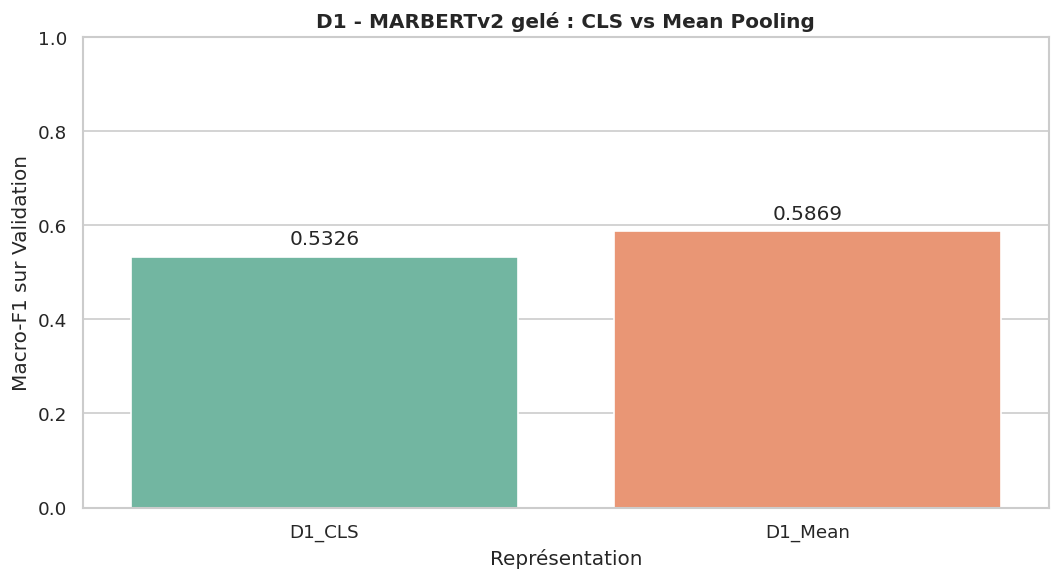

In [71]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=results_D1_df,
    x="Model",
    y="Macro_F1",
    hue="Model",
    palette="Set2",
    legend=False,
    ax=ax
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.4f", padding=5)

ax.set_title("D1 - MARBERTv2 gelé : CLS vs Mean Pooling")
ax.set_xlabel("Représentation")
ax.set_ylabel("Macro-F1 sur Validation")
ax.set_ylim(0, 1)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "D1_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


## D2 — MARBERTv2 gelé + BiLSTM + Attention

In [72]:

import os
import copy
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn

from pathlib import Path
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    classification_report,
    confusion_matrix
)
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
TEXT_COLUMN = "tweet_clean"
MAX_LENGTH = 128
BATCH_SIZE = 32

torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

OUTPUT_D2 = Path("/kaggle/working/results/D2")
OUTPUT_D2.mkdir(parents=True, exist_ok=True)

# Réutiliser les splits de D1
assert TEXT_COLUMN in train_df.columns
assert TEXT_COLUMN in val_df.columns

num_classes = len(label_encoder.classes_)

# MARBERTv2 reste gelé
marbert = marbert.to(device)
marbert.eval()

for param in marbert.parameters():
    param.requires_grad = False

print("Device :", device)
print("Train :", len(train_df))
print("Validation :", len(val_df))
print("Classes :", label_encoder.classes_)
print("Paramètres MARBERT entraînables :",
      sum(p.numel() for p in marbert.parameters()
          if p.requires_grad))


Device : cuda
Train : 2672
Validation : 334
Classes : ['gender' 'origin' 'other' 'religion']
Paramètres MARBERT entraînables : 0


In [73]:

@torch.inference_mode()
def extract_token_states(texts, batch_size=32):

    marbert.eval()

    all_states = []
    all_masks = []

    texts = list(texts)

    for start in tqdm(
        range(0, len(texts), batch_size),
        desc="Extraction états tokens"
    ):
        batch_texts = texts[start:start + batch_size]

        encoded = tokenizer(
            batch_texts,
            padding="max_length",
            truncation=True,
            max_length=MAX_LENGTH,
            return_tensors="pt"
        )

        inputs = {
            k: v.to(device)
            for k, v in encoded.items()
        }

        outputs = marbert(**inputs)

        # [batch, 128, 768]
        states = outputs.last_hidden_state

        all_states.append(
            states.cpu().to(torch.float16)
        )

        all_masks.append(
            encoded["attention_mask"].cpu()
        )

    return (
        torch.cat(all_states, dim=0),
        torch.cat(all_masks, dim=0)
    )


train_states, train_masks = extract_token_states(
    train_df[TEXT_COLUMN].astype(str).tolist(),
    batch_size=BATCH_SIZE
)

val_states, val_masks = extract_token_states(
    val_df[TEXT_COLUMN].astype(str).tolist(),
    batch_size=BATCH_SIZE
)

print("Train states :", train_states.shape)
print("Train masks  :", train_masks.shape)
print("Val states   :", val_states.shape)
print("Val masks    :", val_masks.shape)


Extraction états tokens:   0%|          | 0/84 [00:00<?, ?it/s]

Extraction états tokens:   0%|          | 0/11 [00:00<?, ?it/s]

Train states : torch.Size([2672, 128, 768])
Train masks  : torch.Size([2672, 128])
Val states   : torch.Size([334, 128, 768])
Val masks    : torch.Size([334, 128])


In [75]:

from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(
    train_states,
    train_masks,
    torch.tensor(y_train, dtype=torch.long)
)

val_dataset = TensorDataset(
    val_states,
    val_masks,
    torch.tensor(y_val, dtype=torch.long)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Batchs Train :", len(train_loader))
print("Batchs Val :", len(val_loader))


Batchs Train : 84
Batchs Val : 11


In [76]:

from torch.nn.utils.rnn import (
    pack_padded_sequence,
    pad_packed_sequence
)

class BiLSTMAttention(nn.Module):

    def __init__(
        self,
        input_dim=768,
        hidden_dim=128,
        num_classes=4,
        dropout=0.3
    ):
        super().__init__()

        # BiLSTM : 128 dimensions dans chaque direction
        self.bilstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            bidirectional=True,
            batch_first=True
        )

        # Attention additive
        self.attention = nn.Sequential(
            nn.Linear(hidden_dim * 2, 128),
            nn.Tanh(),
            nn.Linear(128, 1)
        )

        self.dropout = nn.Dropout(dropout)

        self.classifier = nn.Linear(
            hidden_dim * 2,
            num_classes
        )

    def forward(self, states, attention_mask):

        # Longueur réelle des séquences
        lengths = attention_mask.sum(dim=1).cpu()

        # Exclure le padding du traitement BiLSTM
        packed = pack_padded_sequence(
            states,
            lengths,
            batch_first=True,
            enforce_sorted=False
        )

        packed_output, _ = self.bilstm(packed)

        lstm_output, _ = pad_packed_sequence(
            packed_output,
            batch_first=True,
            total_length=states.size(1)
        )

        # [batch, seq_len, 1] -> [batch, seq_len]
        scores = self.attention(
            lstm_output
        ).squeeze(-1)

        # Empêcher l'attention sur le padding
        scores = scores.masked_fill(
            attention_mask == 0,
            -1e9
        )

        # Poids d'attention par token
        attention_weights = torch.softmax(
            scores, dim=1
        )

        # Somme pondérée des états BiLSTM
        context = torch.sum(
            lstm_output * attention_weights.unsqueeze(-1),
            dim=1
        )

        # Classification finale
        context = self.dropout(context)
        logits = self.classifier(context)

        return logits, attention_weights


model_D2 = BiLSTMAttention(
    input_dim=marbert.config.hidden_size,
    hidden_dim=128,
    num_classes=num_classes,
    dropout=0.3
).to(device)

print(model_D2)

print(
    "\nParamètres entraînables D2 :",
    f"{sum(p.numel() for p in model_D2.parameters() if p.requires_grad):,}"
)


BiLSTMAttention(
  (bilstm): LSTM(768, 128, batch_first=True, bidirectional=True)
  (attention): Sequential(
    (0): Linear(in_features=256, out_features=128, bias=True)
    (1): Tanh()
    (2): Linear(in_features=128, out_features=1, bias=True)
  )
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_features=256, out_features=4, bias=True)
)

Paramètres entraînables D2 : 953,605


In [77]:

from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(num_classes),
    y=y_train
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device
)

print("Poids des classes :")
for name, weight in zip(
    label_encoder.classes_,
    class_weights.cpu().numpy()
):
    print(f"{name}: {weight:.4f}")

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = torch.optim.AdamW(
    model_D2.parameters(),
    lr=1e-3,
    weight_decay=0.01
)

EPOCHS = 15
PATIENCE = 3


Poids des classes :
gender: 1.5356
origin: 0.9543
other: 0.4701
religion: 5.7586


In [78]:

def run_epoch(model, loader, optimizer=None):

    is_train = optimizer is not None

    if is_train:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    predictions = []
    targets = []

    for states, masks, labels in loader:

        # Les embeddings en cache sont en float16
        # Convertir en float32 pour le BiLSTM
        states = states.to(
            device=device, dtype=torch.float32
        )
        masks = masks.to(device)
        labels = labels.to(device)

        if is_train:
            optimizer.zero_grad()

        with torch.set_grad_enabled(is_train):

            logits, attention = model(states, masks)

            loss = criterion(logits, labels)

            if is_train:
                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(), max_norm=1.0
                )

                optimizer.step()

        total_loss += loss.item() * len(labels)

        predictions.extend(
            logits.argmax(dim=1).detach().cpu().tolist()
        )
        targets.extend(labels.cpu().tolist())

    avg_loss = total_loss / len(loader.dataset)

    macro_f1 = f1_score(
        targets,
        predictions,
        average="macro",
        labels=np.arange(num_classes),
        zero_division=0
    )

    accuracy = accuracy_score(
        targets, predictions
    )

    return avg_loss, macro_f1, accuracy


In [79]:

history = []

best_f1 = -1
best_state = None
best_epoch = 0
patience_counter = 0

start_time = time.time()

for epoch in range(1, EPOCHS + 1):

    train_loss, train_f1, train_acc = run_epoch(
        model_D2,
        train_loader,
        optimizer=optimizer
    )

    val_loss, val_f1, val_acc = run_epoch(
        model_D2,
        val_loader
    )

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_f1": train_f1,
        "val_loss": val_loss,
        "val_f1": val_f1,
        "val_accuracy": val_acc
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train F1: {train_f1:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val F1: {val_f1:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_f1 > best_f1 + 1e-4:

        best_f1 = val_f1
        best_epoch = epoch

        best_state = copy.deepcopy(
            model_D2.state_dict()
        )

        patience_counter = 0

    else:
        patience_counter += 1

        if patience_counter >= PATIENCE:
            print("\nEarly stopping déclenché.")
            break

training_time = time.time() - start_time

# Restaurer le meilleur modèle
model_D2.load_state_dict(best_state)
model_D2.eval()

print("\nMeilleure époque :", best_epoch)
print(f"Meilleur Macro-F1 Val : {best_f1:.4f}")
print(f"Temps d'entraînement : {training_time:.2f} s")

history_df = pd.DataFrame(history)
display(history_df)


Epoch 01 | Train Loss: 1.1739 | Train F1: 0.3595 | Val Loss: 1.0041 | Val F1: 0.4101 | Val Acc: 0.5269
Epoch 02 | Train Loss: 0.9199 | Train F1: 0.4819 | Val Loss: 1.0435 | Val F1: 0.3949 | Val Acc: 0.5000
Epoch 03 | Train Loss: 0.8208 | Train F1: 0.5306 | Val Loss: 0.8736 | Val F1: 0.4821 | Val Acc: 0.5060
Epoch 04 | Train Loss: 0.7401 | Train F1: 0.5593 | Val Loss: 0.9493 | Val F1: 0.5395 | Val Acc: 0.5539
Epoch 05 | Train Loss: 0.7387 | Train F1: 0.5800 | Val Loss: 0.8954 | Val F1: 0.5275 | Val Acc: 0.5509
Epoch 06 | Train Loss: 0.6875 | Train F1: 0.6068 | Val Loss: 0.9414 | Val F1: 0.5599 | Val Acc: 0.5808
Epoch 07 | Train Loss: 0.6503 | Train F1: 0.6280 | Val Loss: 0.9847 | Val F1: 0.5212 | Val Acc: 0.5719
Epoch 08 | Train Loss: 0.6169 | Train F1: 0.6393 | Val Loss: 1.0300 | Val F1: 0.5424 | Val Acc: 0.5838
Epoch 09 | Train Loss: 0.5948 | Train F1: 0.6641 | Val Loss: 1.0010 | Val F1: 0.5655 | Val Acc: 0.5928
Epoch 10 | Train Loss: 0.5439 | Train F1: 0.6869 | Val Loss: 1.0620 | Val

,epoch,train_loss,train_f1,val_loss,val_f1,val_accuracy
0,1,1.173851,0.359544,1.004090,0.410148,0.526946
1,2,0.919903,0.481948,1.043523,0.394865,0.500000
2,3,0.820837,0.530577,0.873575,0.482123,0.505988
3,4,0.740104,0.559315,0.949267,0.539537,0.553892
4,5,0.738670,0.579978,0.895392,0.527508,0.550898
5,6,0.687533,0.606805,0.941398,0.559871,0.580838
6,7,0.650283,0.628028,0.984672,0.521240,0.571856
7,8,0.616885,0.639278,1.029953,0.542386,0.583832
8,9,0.594839,0.664108,1.001040,0.565458,0.592814
9,10,0.543949,0.686930,1.062004,0.538057,0.568862


===== D2 - VALIDATION =====
              precision    recall  f1-score   support

      gender       0.55      0.78      0.64        54
      origin       0.56      0.43      0.49        88
       other       0.66      0.61      0.63       177
    religion       0.40      0.67      0.50        15

    accuracy                           0.59       334
   macro avg       0.54      0.62      0.57       334
weighted avg       0.60      0.59      0.59       334



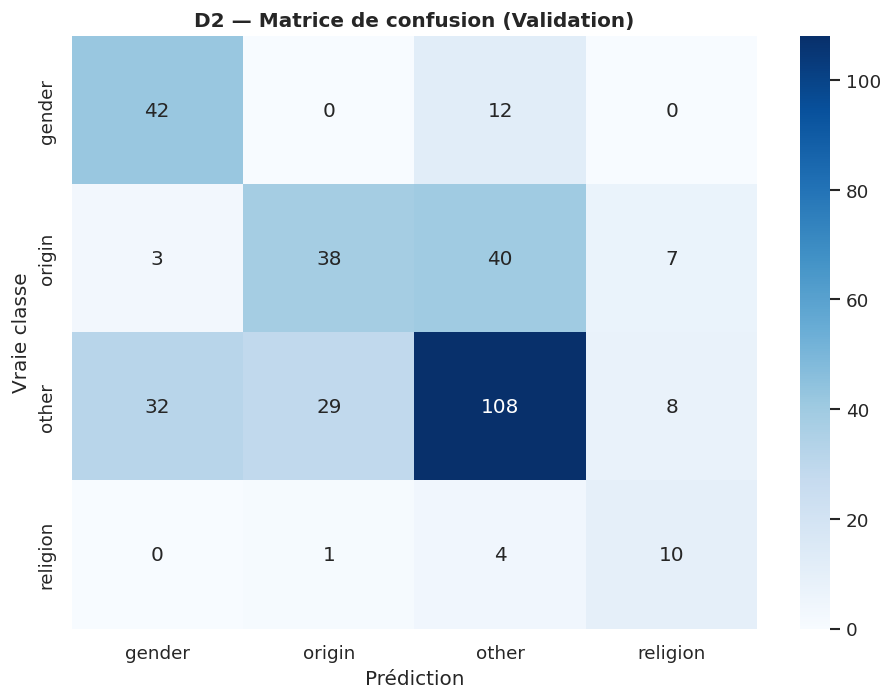

In [80]:

model_D2.eval()

y_pred_D2 = []

with torch.inference_mode():
    for states, masks, labels in val_loader:

        states = states.to(
            device=device, dtype=torch.float32
        )
        masks = masks.to(device)

        logits, weights = model_D2(states, masks)

        y_pred_D2.extend(
            logits.argmax(dim=1).cpu().tolist()
        )

print("===== D2 - VALIDATION =====")

print(
    classification_report(
        y_val,
        y_pred_D2,
        labels=np.arange(num_classes),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

cm = confusion_matrix(
    y_val,
    y_pred_D2,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.title("D2 — Matrice de confusion (Validation)")
plt.xlabel("Prédiction")
plt.ylabel("Vraie classe")
plt.tight_layout()
plt.savefig(OUTPUT_D2 / "D2_confusion_matrix.png", dpi=300)
plt.show()


## E1 — Fine-tuning de MARBERTv2

In [91]:

# Calculer le nombre réel de tokens par tweet
token_lengths = [
    len(tokenizer_E1.encode(
        text,
        add_special_tokens=True,
        truncation=False
    ))
    for text in train_df["tweet_clean"].astype(str)
]

print("Longueur moyenne :", np.mean(token_lengths))
print("Longueur médiane :", np.median(token_lengths))
print("95e percentile :", np.percentile(token_lengths, 95))
print("99e percentile :", np.percentile(token_lengths, 99))
print("Maximum observé :", max(token_lengths))

print(
    "Tweets tronqués avec MAX_LENGTH=128 :",
    sum(length > 128 for length in token_lengths)
)

print(
    "Pourcentage tronqué :",
    round(np.mean(np.array(token_lengths) > 128) * 100, 2),
    "%"
)

print(
    "Capacité maximale du modèle :",
    model_E1.config.max_position_embeddings
)


Longueur moyenne : 18.085329341317365
Longueur médiane : 17.0
95e percentile : 31.0
99e percentile : 35.0
Maximum observé : 45
Tweets tronqués avec MAX_LENGTH=128 : 0
Pourcentage tronqué : 0.0 %
Capacité maximale du modèle : 512


In [82]:

import os
import math
import time
import random
import gc

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup
)

from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Configuration E1
MODEL_NAME_E1 = "UBC-NLP/MARBERTv2"
TEXT_COLUMN_E1 = "tweet_clean"

SEED_E1 = 42
MAX_LENGTH_E1 = 128
BATCH_SIZE_E1 = 8
ACCUMULATION_STEPS_E1 = 4

LR_E1 = 2e-5
WEIGHT_DECAY_E1 = 0.01
EPOCHS_E1 = 5
PATIENCE_E1 = 2
WARMUP_RATIO_E1 = 0.10

OUTPUT_E1 = Path("/kaggle/working/results/E1_MARBERTv2")
OUTPUT_E1.mkdir(parents=True, exist_ok=True)

random.seed(SEED_E1)
np.random.seed(SEED_E1)
torch.manual_seed(SEED_E1)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED_E1)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device :", device)
print("Modèle :", MODEL_NAME_E1)
print("Batch effectif :", BATCH_SIZE_E1 * ACCUMULATION_STEPS_E1)


Device : cuda
Modèle : UBC-NLP/MARBERTv2
Batch effectif : 32


In [83]:

# Vérifier les données existantes
assert "train_df" in globals(), "train_df introuvable"
assert "val_df" in globals(), "val_df introuvable"

assert TEXT_COLUMN_E1 in train_df.columns
assert TEXT_COLUMN_E1 in val_df.columns

assert train_df[TEXT_COLUMN_E1].notna().all()
assert val_df[TEXT_COLUMN_E1].notna().all()

# Labels
label_encoder_E1 = LabelEncoder()
label_encoder_E1.fit(train_df["target"])

y_train_E1 = label_encoder_E1.transform(
    train_df["target"]
)

y_val_E1 = label_encoder_E1.transform(
    val_df["target"]
)

NUM_CLASSES_E1 = len(label_encoder_E1.classes_)

print("Train :", len(train_df))
print("Validation :", len(val_df))
print("Nombre de classes :", NUM_CLASSES_E1)
print("Classes :", label_encoder_E1.classes_)


Train : 2672
Validation : 334
Nombre de classes : 4
Classes : ['gender' 'origin' 'other' 'religion']


In [84]:

tokenizer_E1 = AutoTokenizer.from_pretrained(
    MODEL_NAME_E1
)

class E1Dataset(Dataset):

    def __init__(self, texts, labels):
        self.encodings = tokenizer_E1(
            list(texts),
            truncation=True,
            padding="max_length",
            max_length=MAX_LENGTH_E1,
            return_tensors="pt"
        )

        self.labels = torch.tensor(
            labels, dtype=torch.long
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        item = {
            k: v[index]
            for k, v in self.encodings.items()
        }
        item["labels"] = self.labels[index]
        return item


train_dataset_E1 = E1Dataset(
    train_df[TEXT_COLUMN_E1].astype(str).tolist(),
    y_train_E1
)

val_dataset_E1 = E1Dataset(
    val_df[TEXT_COLUMN_E1].astype(str).tolist(),
    y_val_E1
)

train_loader_E1 = DataLoader(
    train_dataset_E1,
    batch_size=BATCH_SIZE_E1,
    shuffle=True
)

val_loader_E1 = DataLoader(
    val_dataset_E1,
    batch_size=BATCH_SIZE_E1,
    shuffle=False
)

print("Train batches :", len(train_loader_E1))
print("Validation batches :", len(val_loader_E1))


Train batches : 334
Validation batches : 42


In [85]:

id2label_E1 = {
    i: name
    for i, name in enumerate(label_encoder_E1.classes_)
}

label2id_E1 = {
    name: i
    for i, name in id2label_E1.items()
}

model_E1 = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME_E1,
    num_labels=NUM_CLASSES_E1,
    id2label=id2label_E1,
    label2id=label2id_E1
).to(device)

for param in model_E1.parameters():
    param.requires_grad = True

print(
    "Paramètres entraînables :",
    f"{sum(p.numel() for p in model_E1.parameters() if p.requires_grad):,}"
)

print("MARBERTv2 est entièrement entraînable.")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: UBC-NLP/MARBERTv2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were ne

Paramètres entraînables : 162,844,420
MARBERTv2 est entièrement entraînable.


In [86]:

class_weights_E1 = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUM_CLASSES_E1),
    y=y_train_E1
)

class_weights_E1 = torch.tensor(
    class_weights_E1,
    dtype=torch.float32,
    device=device
)

criterion_E1 = nn.CrossEntropyLoss(
    weight=class_weights_E1,
    reduction="none"
)

optimizer_E1 = torch.optim.AdamW(
    model_E1.parameters(),
    lr=LR_E1,
    weight_decay=WEIGHT_DECAY_E1
)

steps_per_epoch_E1 = math.ceil(
    len(train_loader_E1) / ACCUMULATION_STEPS_E1
)

total_steps_E1 = steps_per_epoch_E1 * EPOCHS_E1
warmup_steps_E1 = int(total_steps_E1 * WARMUP_RATIO_E1)

scheduler_E1 = get_linear_schedule_with_warmup(
    optimizer_E1,
    num_warmup_steps=warmup_steps_E1,
    num_training_steps=total_steps_E1
)

print("Poids des classes :")

for name, weight in zip(
    label_encoder_E1.classes_,
    class_weights_E1.cpu().numpy()
):
    print(name, ":", round(float(weight), 4))

print("Total steps :", total_steps_E1)
print("Warmup steps :", warmup_steps_E1)


Poids des classes :
gender : 1.5356
origin : 0.9543
other : 0.4701
religion : 5.7586
Total steps : 420
Warmup steps : 42


In [88]:

def train_epoch_E1():

    model_E1.train()

    all_preds = []
    all_labels = []
    total_loss = 0.0

    optimizer_E1.zero_grad(set_to_none=True)

    accumulation_loss = None
    accumulation_weight = 0.0

    for step, batch in enumerate(
        tqdm(train_loader_E1, desc="Train E1")
    ):

        labels = batch["labels"].to(device)

        inputs = {
            k: v.to(device)
            for k, v in batch.items()
            if k != "labels"
        }

        outputs = model_E1(**inputs)
        logits = outputs.logits

        losses = criterion_E1(logits, labels)

        # Loss pondérée exacte pour le batch effectif
        batch_weight = class_weights_E1[labels].sum()
        weighted_loss_sum = losses.sum()

        # Diviser par la somme des poids du groupe
        group_start = (
            step // ACCUMULATION_STEPS_E1
        ) * ACCUMULATION_STEPS_E1

        group_end = min(
            group_start + ACCUMULATION_STEPS_E1,
            len(train_loader_E1)
        )

        # Accumuler les gradients sans mettre à jour
        # Le facteur de normalisation sera appliqué
        # juste avant optimizer.step()
        weighted_loss_sum.backward()

        accumulation_weight += batch_weight.item()
        total_loss += weighted_loss_sum.item()

        all_preds.extend(
            logits.argmax(dim=1).detach().cpu().tolist()
        )
        all_labels.extend(labels.cpu().tolist())

        should_step = (step + 1 == group_end)

        if should_step:

            # Normaliser les gradients du batch effectif
            for p in model_E1.parameters():
                if p.grad is not None:
                    p.grad.div_(accumulation_weight)

            torch.nn.utils.clip_grad_norm_(
                model_E1.parameters(),
                max_norm=1.0
            )

            optimizer_E1.step()
            scheduler_E1.step()
            optimizer_E1.zero_grad(set_to_none=True)

            accumulation_weight = 0.0

    train_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro",
        zero_division=0
    )

    # Loss pondérée moyenne (normalisation globale)
    global_weights = class_weights_E1[
        torch.tensor(y_train_E1, device=device)
    ].sum().item()

    return total_loss / global_weights, train_f1


@torch.inference_mode()
def evaluate_E1():

    model_E1.eval()

    all_preds = []
    all_labels = []
    total_loss = 0.0
    total_weight = 0.0

    for batch in tqdm(
        val_loader_E1, desc="Validation E1"
    ):

        labels = batch["labels"].to(device)

        inputs = {
            k: v.to(device)
            for k, v in batch.items()
            if k != "labels"
        }

        outputs = model_E1(**inputs)
        logits = outputs.logits

        losses = criterion_E1(logits, labels)

        total_loss += losses.sum().item()
        total_weight += class_weights_E1[labels].sum().item()

        all_preds.extend(
            logits.argmax(dim=1).cpu().tolist()
        )

        all_labels.extend(labels.cpu().tolist())

    val_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro",
        zero_division=0
    )

    val_acc = accuracy_score(
        all_labels, all_preds
    )

    return (
        total_loss / total_weight,
        val_f1,
        val_acc,
        all_preds
    )


# entrainment 

In [89]:

history_E1 = []

best_f1_E1 = -1.0
best_epoch_E1 = 0
patience_counter_E1 = 0

checkpoint_dir_E1 = OUTPUT_E1 / "best_checkpoint"

start_E1 = time.time()

for epoch in range(1, EPOCHS_E1 + 1):

    print(f"\n========== EPOCH {epoch}/{EPOCHS_E1} ==========")

    train_loss, train_f1 = train_epoch_E1()

    val_loss, val_f1, val_acc, _ = evaluate_E1()

    history_E1.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_f1": train_f1,
        "val_loss": val_loss,
        "val_f1": val_f1,
        "val_accuracy": val_acc
    })

    print(f"Train Loss : {train_loss:.4f}")
    print(f"Train Macro-F1 : {train_f1:.4f}")
    print(f"Val Loss : {val_loss:.4f}")
    print(f"Val Macro-F1 : {val_f1:.4f}")
    print(f"Val Accuracy : {val_acc:.4f}")

    if val_f1 > best_f1_E1 + 1e-4:

        best_f1_E1 = val_f1
        best_epoch_E1 = epoch
        patience_counter_E1 = 0

        model_E1.save_pretrained(checkpoint_dir_E1)
        tokenizer_E1.save_pretrained(checkpoint_dir_E1)

        print("Meilleur checkpoint sauvegardé.")

    else:
        patience_counter_E1 += 1

        if patience_counter_E1 >= PATIENCE_E1:
            print("Early stopping déclenché.")
            break

print("\n===== RÉSULTAT FINAL =====")
print("Meilleure époque :", best_epoch_E1)
print("Meilleur Macro-F1 Validation :", round(best_f1_E1, 4))
print("Temps :", round(time.time() - start_E1, 2), "secondes")

history_E1_df = pd.DataFrame(history_E1)
display(history_E1_df)

history_E1_df.to_csv(
    OUTPUT_E1 / "training_history.csv",
    index=False
)



========== EPOCH 1/5 ==========


Train E1:   0%|          | 0/334 [00:00<?, ?it/s]

Validation E1:   0%|          | 0/42 [00:00<?, ?it/s]

Train Loss : 1.2237
Train Macro-F1 : 0.3566
Val Loss : 0.9015
Val Macro-F1 : 0.4614
Val Accuracy : 0.4581


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Meilleur checkpoint sauvegardé.

========== EPOCH 2/5 ==========


... (17 outputs left out)

Train Loss : 0.4642
Train Macro-F1 : 0.7505
Val Loss : 0.6742
Val Macro-F1 : 0.6454
Val Accuracy : 0.6168


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Meilleur checkpoint sauvegardé.

===== RÉSULTAT FINAL =====
Meilleure époque : 5
Meilleur Macro-F1 Validation : 0.6454
Temps : 352.57 secondes


,epoch,train_loss,train_f1,val_loss,val_f1,val_accuracy
0,1,1.223663,0.356603,0.901489,0.461357,0.458084
1,2,0.807450,0.537457,0.743943,0.573092,0.547904
2,3,0.642653,0.649360,0.767661,0.603141,0.592814
3,4,0.532297,0.707323,0.696995,0.634678,0.610778
4,5,0.464239,0.750485,0.674214,0.645422,0.616766


In [93]:

# Recharger le meilleur checkpoint
del model_E1
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

model_E1 = AutoModelForSequenceClassification.from_pretrained(
    checkpoint_dir_E1
).to(device)

val_loss, val_f1, val_acc, y_pred_E1 = evaluate_E1()

print("\n===== MARBERTv2 FINE-TUNED — VALIDATION =====")

print("Macro-F1 :", round(val_f1, 4))
print("Accuracy :", round(val_acc, 4))

print(
    classification_report(
        y_val_E1,
        y_pred_E1,
        labels=np.arange(NUM_CLASSES_E1),
        target_names=label_encoder_E1.classes_,
        zero_division=0
    )
)


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Validation E1:   0%|          | 0/42 [00:00<?, ?it/s]


===== MARBERTv2 FINE-TUNED — VALIDATION =====
Macro-F1 : 0.6454
Accuracy : 0.6168
              precision    recall  f1-score   support

      gender       0.54      0.91      0.68        54
      origin       0.52      0.78      0.63        88
       other       0.85      0.42      0.56       177
    religion       0.58      0.93      0.72        15

    accuracy                           0.62       334
   macro avg       0.62      0.76      0.65       334
weighted avg       0.70      0.62      0.60       334



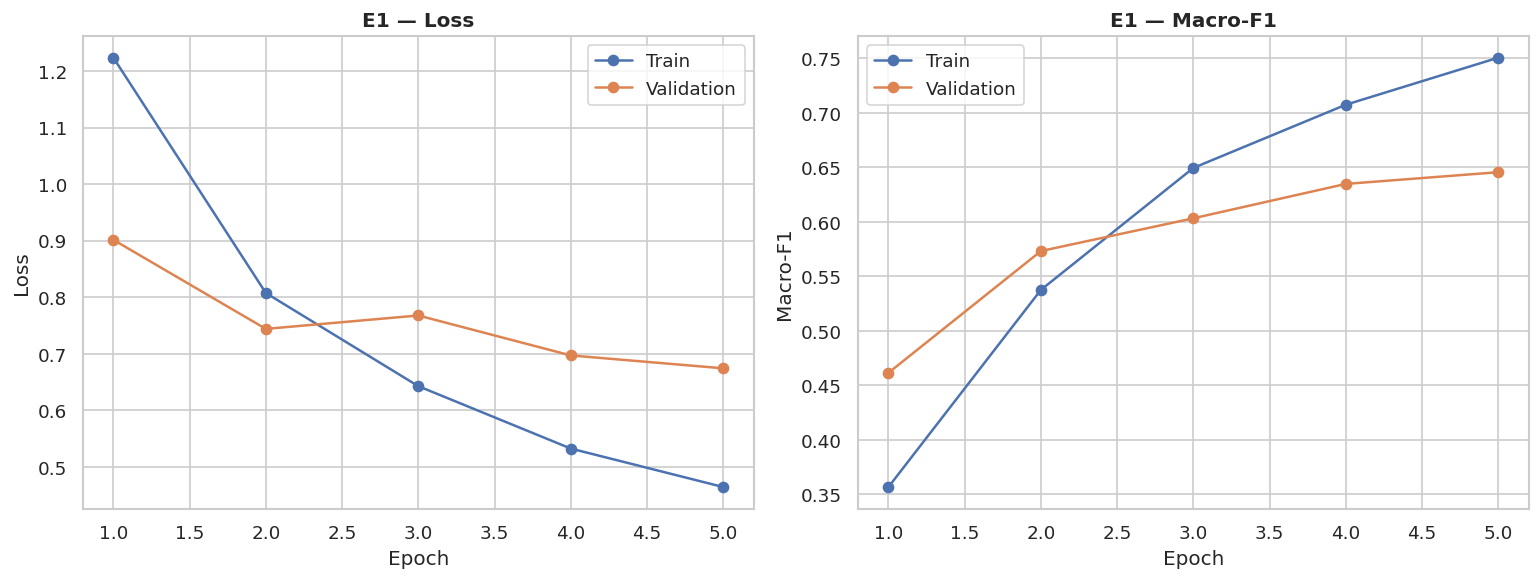

In [94]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    history_E1_df["epoch"],
    history_E1_df["train_loss"],
    marker="o",
    label="Train"
)

axes[0].plot(
    history_E1_df["epoch"],
    history_E1_df["val_loss"],
    marker="o",
    label="Validation"
)

axes[0].set_title("E1 — Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(
    history_E1_df["epoch"],
    history_E1_df["train_f1"],
    marker="o",
    label="Train"
)

axes[1].plot(
    history_E1_df["epoch"],
    history_E1_df["val_f1"],
    marker="o",
    label="Validation"
)

axes[1].set_title("E1 — Macro-F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro-F1")
axes[1].legend()

plt.tight_layout()

plt.savefig(
    OUTPUT_E1 / "learning_curves.png",
    dpi=300
)

plt.show()


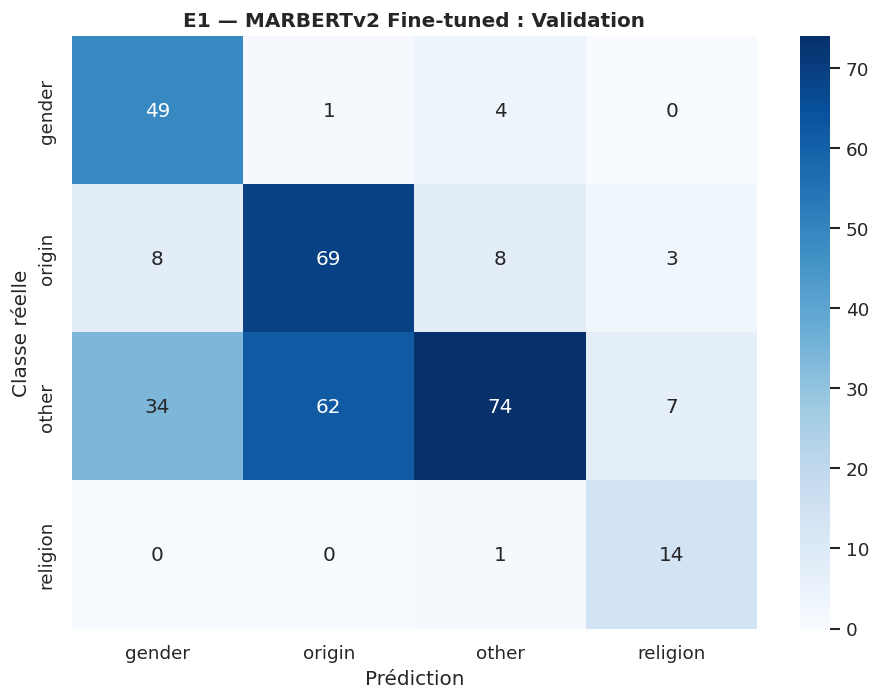

In [95]:

cm_E1 = confusion_matrix(
    y_val_E1,
    y_pred_E1,
    labels=np.arange(NUM_CLASSES_E1)
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_E1,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder_E1.classes_,
    yticklabels=label_encoder_E1.classes_
)

plt.title("E1 — MARBERTv2 Fine-tuned : Validation")
plt.xlabel("Prédiction")
plt.ylabel("Classe réelle")

plt.tight_layout()

plt.savefig(
    OUTPUT_E1 / "confusion_matrix.png",
    dpi=300
)

plt.show()


# E2 — MARBERTv2 Multi-Task Learning : code complet Kaggle

In [96]:

import os
import gc
import json
import math
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader

from transformers import (
    AutoTokenizer,
    AutoModel,
    get_linear_schedule_with_warmup
)

from sklearn.preprocessing import LabelEncoder, MultiLabelBinarizer
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    classification_report,
    confusion_matrix
)

MODEL_NAME_E2 = "UBC-NLP/MARBERTv2"
TEXT_COLUMN_E2 = "tweet_clean"

SEED_E2 = 42
MAX_LENGTH_E2 = 128

# Batch effectif = 4 x 8 = 32
BATCH_SIZE_E2 = 4
ACCUM_STEPS_E2 = 8

LR_E2 = 2e-5
WEIGHT_DECAY_E2 = 0.01
EPOCHS_E2 = 5
PATIENCE_E2 = 2
WARMUP_RATIO_E2 = 0.10

OUTPUT_E2 = Path("/kaggle/working/results/E2_MARBERTv2")
OUTPUT_E2.mkdir(parents=True, exist_ok=True)

def set_seed_E2(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed_E2(SEED_E2)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device :", device)
print("Modèle :", MODEL_NAME_E2)
print("Batch effectif :", BATCH_SIZE_E2 * ACCUM_STEPS_E2)


Device : cuda
Modèle : UBC-NLP/MARBERTv2
Batch effectif : 32


In [97]:

TASK_COLUMNS = [
    "target",
    "sentiment",
    "directness",
    "group",
    "annotator_sentiment"
]

assert "train_df" in globals()
assert "val_df" in globals()

for column in [TEXT_COLUMN_E2] + TASK_COLUMNS:
    assert column in train_df.columns, f"Train : {column} absent"
    assert column in val_df.columns, f"Val : {column} absent"

train_e2 = train_df.reset_index(drop=True).copy()
val_e2 = val_df.reset_index(drop=True).copy()

for name, frame in [("Train", train_e2), ("Val", val_e2)]:
    assert frame[[TEXT_COLUMN_E2] + TASK_COLUMNS].notna().all().all()
    assert frame[TEXT_COLUMN_E2].astype(str).str.strip().ne("").all()

print("Train :", len(train_e2))
print("Validation :", len(val_e2))

for column in TASK_COLUMNS:
    print(f"\n===== {column} =====")
    print(train_e2[column].value_counts().head(10))


Train : 2672
Validation : 334

===== target =====
target
other       1421
origin       700
gender       435
religion     116
Name: count, dtype: int64

===== sentiment =====
sentiment
offensive                776
normal                   718
hateful                  372
abusive_disrespectful    169
disrespectful            134
abusive_hateful          132
disrespectful_normal      73
abusive_offensive         63
abusive_normal            63
hateful_disrespectful     35
Name: count, dtype: int64

===== directness =====
directness
indirect    1554
direct      1118
Name: count, dtype: int64

===== group =====
group
other              1173
individual          728
women               577
african_descent      40
refugees             38
arabs                37
muslims              32
indian/hindu         22
jews                  9
christian             7
Name: count, dtype: int64

===== annotator_sentiment =====
annotator_sentiment
indifference                                1066
shock       

In [99]:

from sklearn.preprocessing import LabelEncoder, MultiLabelBinarizer

MULTICLASS_TASKS = ["target", "directness", "group"]
MULTILABEL_TASKS = ["sentiment", "annotator_sentiment"]

HOSTILITY_LABELS = [
    "abusive", "hateful", "offensive",
    "normal", "disrespectful", "fearful"
]

ANNOTATOR_LABELS = [
    "anger", "confusion", "disgust",
    "fear", "indifference", "sadness", "shock"
]

def split_multilabel(value):
    return [
        x.strip()
        for x in str(value).lower().split("_")
        if x.strip()
    ]

encoders_E2 = {}
train_labels_E2 = {}
val_labels_E2 = {}

for task in MULTICLASS_TASKS:

    encoder = LabelEncoder()

    train_values = train_e2[task].astype(str)
    val_values = val_e2[task].astype(str)

    if task == "group":
        # Classe réservée aux groupes inconnus
        encoder.fit(
            train_values.tolist() + ["__UNSEEN__"]
        )

        val_values = val_values.where(
            val_values.isin(set(train_values)),
            "__UNSEEN__"
        )
    else:
        encoder.fit(train_values)

        unknown = set(val_values) - set(encoder.classes_)
        if unknown:
            raise ValueError(
                f"Classes inconnues pour {task}: {unknown}"
            )

    train_labels_E2[task] = encoder.transform(train_values)
    val_labels_E2[task] = encoder.transform(val_values)

    encoders_E2[task] = encoder

for task, classes in {
    "sentiment": HOSTILITY_LABELS,
    "annotator_sentiment": ANNOTATOR_LABELS
}.items():

    encoder = MultiLabelBinarizer(classes=classes)
    encoder.fit([classes])

    train_lists = train_e2[task].apply(split_multilabel).tolist()
    val_lists = val_e2[task].apply(split_multilabel).tolist()

    for row in train_lists + val_lists:
        unknown = set(row) - set(classes)
        if unknown:
            raise ValueError(
                f"Labels inconnus pour {task}: {unknown}"
            )

    train_labels_E2[task] = encoder.transform(train_lists).astype(np.float32)
    val_labels_E2[task] = encoder.transform(val_lists).astype(np.float32)

    encoders_E2[task] = encoder

for task, encoder in encoders_E2.items():
    print(task, ":", list(encoder.classes_))
    print("Train shape :", train_labels_E2[task].shape)


target : ['gender', 'origin', 'other', 'religion']
Train shape : (2672,)
directness : ['direct', 'indirect']
Train shape : (2672,)
group : [np.str_('__UNSEEN__'), np.str_('african_descent'), np.str_('arabs'), np.str_('christian'), np.str_('gay'), np.str_('immigrants'), np.str_('indian/hindu'), np.str_('individual'), np.str_('jews'), np.str_('muslims'), np.str_('other'), np.str_('refugees'), np.str_('special_needs'), np.str_('women')]
Train shape : (2672,)
sentiment : ['abusive', 'hateful', 'offensive', 'normal', 'disrespectful', 'fearful']
Train shape : (2672, 6)
annotator_sentiment : ['anger', 'confusion', 'disgust', 'fear', 'indifference', 'sadness', 'shock']
Train shape : (2672, 7)


In [100]:

tokenizer_E2 = AutoTokenizer.from_pretrained(
    MODEL_NAME_E2
)

class MultiTaskDataset(Dataset):

    def __init__(self, df, labels_dict):
        self.encodings = tokenizer_E2(
            df[TEXT_COLUMN_E2].astype(str).tolist(),
            truncation=True,
            padding="max_length",
            max_length=MAX_LENGTH_E2,
            return_tensors="pt"
        )

        self.labels = {
            task: torch.tensor(
                values,
                dtype=torch.float32 if task in MULTILABEL_TASKS
                else torch.long
            )
            for task, values in labels_dict.items()
        }

        self.n = len(df)

    def __len__(self):
        return self.n

    def __getitem__(self, idx):
        result = {
            k: v[idx]
            for k, v in self.encodings.items()
        }
        result["labels"] = {
            task: values[idx]
            for task, values in self.labels.items()
        }
        return result


train_dataset_E2 = MultiTaskDataset(
    train_e2, train_labels_E2
)

val_dataset_E2 = MultiTaskDataset(
    val_e2, val_labels_E2
)

train_loader_E2 = DataLoader(
    train_dataset_E2,
    batch_size=BATCH_SIZE_E2,
    shuffle=True
)

val_loader_E2 = DataLoader(
    val_dataset_E2,
    batch_size=BATCH_SIZE_E2,
    shuffle=False
)

print("Train batches :", len(train_loader_E2))
print("Val batches :", len(val_loader_E2))


Train batches : 668
Val batches : 84


In [101]:

class MARBERTMultiTask(nn.Module):

    def __init__(self, model_name, encoders, dropout=0.2):
        super().__init__()

        self.encoder = AutoModel.from_pretrained(model_name)

        hidden_size = self.encoder.config.hidden_size
        self.dropout = nn.Dropout(dropout)

        self.heads = nn.ModuleDict({
            task: nn.Linear(hidden_size, len(encoder.classes_))
            for task, encoder in encoders.items()
        })

    def forward(self, input_ids, attention_mask, token_type_ids=None):

        kwargs = {
            "input_ids": input_ids,
            "attention_mask": attention_mask
        }

        if token_type_ids is not None:
            kwargs["token_type_ids"] = token_type_ids

        outputs = self.encoder(**kwargs)

        # Représentation du premier token [CLS]
        representation = outputs.last_hidden_state[:, 0, :]

        representation = self.dropout(representation)

        logits = {
            task: head(representation)
            for task, head in self.heads.items()
        }

        return logits


model_E2 = MARBERTMultiTask(
    MODEL_NAME_E2,
    encoders_E2
).to(device)

# Fine-tuning complet
for p in model_E2.parameters():
    p.requires_grad = True

# Réduire l'utilisation de mémoire pendant l'entraînement
model_E2.encoder.gradient_checkpointing_enable()

print(model_E2.heads)

print(
    "\nParamètres entraînables :",
    f"{sum(p.numel() for p in model_E2.parameters() if p.requires_grad):,}"
)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: UBC-NLP/MARBERTv2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


ModuleDict(
  (target): Linear(in_features=768, out_features=4, bias=True)
  (directness): Linear(in_features=768, out_features=2, bias=True)
  (group): Linear(in_features=768, out_features=14, bias=True)
  (sentiment): Linear(in_features=768, out_features=6, bias=True)
  (annotator_sentiment): Linear(in_features=768, out_features=7, bias=True)
)

Paramètres entraînables : 162,866,721


# Architecturere

In [102]:

class MARBERTMultiTask(nn.Module):

    def __init__(self, model_name, encoders, dropout=0.2):
        super().__init__()

        self.encoder = AutoModel.from_pretrained(model_name)

        hidden_size = self.encoder.config.hidden_size
        self.dropout = nn.Dropout(dropout)

        self.heads = nn.ModuleDict({
            task: nn.Linear(hidden_size, len(encoder.classes_))
            for task, encoder in encoders.items()
        })

    def forward(self, input_ids, attention_mask, token_type_ids=None):

        kwargs = {
            "input_ids": input_ids,
            "attention_mask": attention_mask
        }

        if token_type_ids is not None:
            kwargs["token_type_ids"] = token_type_ids

        outputs = self.encoder(**kwargs)

        # Représentation du premier token [CLS]
        representation = outputs.last_hidden_state[:, 0, :]

        representation = self.dropout(representation)

        logits = {
            task: head(representation)
            for task, head in self.heads.items()
        }

        return logits


model_E2 = MARBERTMultiTask(
    MODEL_NAME_E2,
    encoders_E2
).to(device)

# Fine-tuning complet
for p in model_E2.parameters():
    p.requires_grad = True

# Réduire l'utilisation de mémoire pendant l'entraînement
model_E2.encoder.gradient_checkpointing_enable()

print(model_E2.heads)

print(
    "\nParamètres entraînables :",
    f"{sum(p.numel() for p in model_E2.parameters() if p.requires_grad):,}"
)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: UBC-NLP/MARBERTv2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


ModuleDict(
  (target): Linear(in_features=768, out_features=4, bias=True)
  (directness): Linear(in_features=768, out_features=2, bias=True)
  (group): Linear(in_features=768, out_features=14, bias=True)
  (sentiment): Linear(in_features=768, out_features=6, bias=True)
  (annotator_sentiment): Linear(in_features=768, out_features=7, bias=True)
)

Paramètres entraînables : 162,866,721


In [103]:

loss_functions_E2 = {}

# CrossEntropy pondérée pour les 3 tâches multi-classes
for task in MULTICLASS_TASKS:

    y = train_labels_E2[task]
    num = len(encoders_E2[task].classes_)

    counts = np.bincount(y, minlength=num)
    weights = np.zeros(num, dtype=np.float32)

    present = counts > 0
    weights[present] = len(y) / (present.sum() * counts[present])

    loss_functions_E2[task] = nn.CrossEntropyLoss(
        weight=torch.tensor(
            weights,
            dtype=torch.float32,
            device=device
        )
    )

# BCE pondérée pour les 2 tâches multi-label
for task in MULTILABEL_TASKS:

    Y = train_labels_E2[task]

    positives = Y.sum(axis=0)
    negatives = len(Y) - positives

    pos_weights = np.where(
        positives > 0,
        negatives / np.maximum(positives, 1),
        1.0
    )

    pos_weights = np.clip(pos_weights, 1.0, 10.0)

    loss_functions_E2[task] = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(
            pos_weights,
            dtype=torch.float32,
            device=device
        )
    )

TASK_WEIGHTS_E2 = {
    task: 1.0
    for task in TASK_COLUMNS
}

def compute_multitask_loss(logits, labels):

    individual_losses = {}

    for task in TASK_COLUMNS:
        individual_losses[task] = loss_functions_E2[task](
            logits[task].float(),
            labels[task]
        )

    total_loss = sum(
        TASK_WEIGHTS_E2[task] * individual_losses[task]
        for task in TASK_COLUMNS
    )

    return total_loss, individual_losses


print("Fonctions de perte configurées.")
print("Poids des tâches :", TASK_WEIGHTS_E2)


Fonctions de perte configurées.
Poids des tâches : {'target': 1.0, 'sentiment': 1.0, 'directness': 1.0, 'group': 1.0, 'annotator_sentiment': 1.0}


In [104]:

optimizer_E2 = torch.optim.AdamW(
    model_E2.parameters(),
    lr=LR_E2,
    weight_decay=WEIGHT_DECAY_E2
)

steps_per_epoch_E2 = math.ceil(
    len(train_loader_E2) / ACCUM_STEPS_E2
)

total_steps_E2 = steps_per_epoch_E2 * EPOCHS_E2
warmup_steps_E2 = int(total_steps_E2 * WARMUP_RATIO_E2)

scheduler_E2 = get_linear_schedule_with_warmup(
    optimizer_E2,
    num_warmup_steps=warmup_steps_E2,
    num_training_steps=total_steps_E2
)

scaler_E2 = torch.amp.GradScaler(
    "cuda",
    enabled=(device.type == "cuda")
)

print("Total steps :", total_steps_E2)
print("Warmup steps :", warmup_steps_E2)



Total steps : 420
Warmup steps : 42


In [105]:

def run_epoch_E2(loader, training=False):

    if training:
        model_E2.train()
        optimizer_E2.zero_grad(set_to_none=True)
    else:
        model_E2.eval()

    total_loss = 0.0
    all_true = {task: [] for task in TASK_COLUMNS}
    all_logits = {task: [] for task in TASK_COLUMNS}

    context = torch.enable_grad() if training else torch.inference_mode()

    with context:

        for step, batch in enumerate(
            tqdm(loader, desc="Train" if training else "Val")
        ):

            labels = {
                task: tensor.to(device)
                for task, tensor in batch["labels"].items()
            }

            inputs = {
                k: v.to(device)
                for k, v in batch.items()
                if k != "labels"
            }

            with torch.autocast(
                device_type="cuda" if device.type == "cuda" else "cpu",
                enabled=(device.type == "cuda")
            ):
                logits = model_E2(**inputs)
                loss, individual_losses = compute_multitask_loss(
                    logits, labels
                )

            if training:

                group_start = (
                    step // ACCUM_STEPS_E2
                ) * ACCUM_STEPS_E2

                group_size = min(
                    ACCUM_STEPS_E2,
                    len(loader) - group_start
                )

                scaler_E2.scale(loss / group_size).backward()

                if (
                    (step + 1) % ACCUM_STEPS_E2 == 0
                    or step + 1 == len(loader)
                ):

                    scaler_E2.unscale_(optimizer_E2)

                    torch.nn.utils.clip_grad_norm_(
                        model_E2.parameters(), 1.0
                    )

                    old_scale = scaler_E2.get_scale()
                    scaler_E2.step(optimizer_E2)
                    scaler_E2.update()

                    # Scheduler seulement si une mise à jour a eu lieu
                    if scaler_E2.get_scale() >= old_scale:
                        scheduler_E2.step()

                    optimizer_E2.zero_grad(set_to_none=True)

            batch_size = labels["target"].size(0)
            total_loss += loss.item() * batch_size

            for task in TASK_COLUMNS:
                all_true[task].append(
                    labels[task].detach().cpu().numpy()
                )
                all_logits[task].append(
                    logits[task].detach().float().cpu().numpy()
                )

    true_arrays = {
        task: np.concatenate(values)
        for task, values in all_true.items()
    }

    logit_arrays = {
        task: np.concatenate(values)
        for task, values in all_logits.items()
    }

    y_true = true_arrays["target"]
    y_pred = logit_arrays["target"].argmax(axis=1)

    macro_f1 = f1_score(
        y_true, y_pred,
        average="macro",
        labels=np.arange(len(encoders_E2["target"].classes_)),
        zero_division=0
    )

    return {
        "loss": total_loss / len(loader.dataset),
        "macro_f1": macro_f1,
        "accuracy": accuracy_score(y_true, y_pred),
        "true": true_arrays,
        "logits": logit_arrays
    }



In [106]:

history_E2 = []

best_f1_E2 = -1.0
best_epoch_E2 = 0
patience_counter_E2 = 0

checkpoint_E2 = OUTPUT_E2 / "best_multitask.pt"

for epoch in range(1, EPOCHS_E2 + 1):

    print(f"\n========== EPOCH {epoch}/{EPOCHS_E2} ==========")

    train_result = run_epoch_E2(
        train_loader_E2, training=True
    )

    val_result = run_epoch_E2(
        val_loader_E2, training=False
    )

    history_E2.append({
        "epoch": epoch,
        "train_loss": train_result["loss"],
        "train_macro_f1": train_result["macro_f1"],
        "val_loss": val_result["loss"],
        "val_macro_f1": val_result["macro_f1"],
        "val_accuracy": val_result["accuracy"]
    })

    print(f"Train Loss : {train_result['loss']:.4f}")
    print(f"Train F1   : {train_result['macro_f1']:.4f}")
    print(f"Val Loss   : {val_result['loss']:.4f}")
    print(f"Val F1     : {val_result['macro_f1']:.4f}")
    print(f"Val Acc    : {val_result['accuracy']:.4f}")

    if val_result["macro_f1"] > best_f1_E2 + 1e-4:

        best_f1_E2 = val_result["macro_f1"]
        best_epoch_E2 = epoch
        patience_counter_E2 = 0

        torch.save(
            {
                "model_state_dict": model_E2.state_dict(),
                "best_epoch": best_epoch_E2,
                "best_val_macro_f1": best_f1_E2,
                "model_name": MODEL_NAME_E2
            },
            checkpoint_E2
        )

        print("Nouveau meilleur checkpoint.")

    else:
        patience_counter_E2 += 1

        if patience_counter_E2 >= PATIENCE_E2:
            print("Early stopping déclenché.")
            break

history_E2_df = pd.DataFrame(history_E2)
display(history_E2_df)

history_E2_df.to_csv(
    OUTPUT_E2 / "training_history.csv",
    index=False
)

tokenizer_E2.save_pretrained(OUTPUT_E2 / "tokenizer")



========== EPOCH 1/5 ==========


Train:   0%|          | 0/668 [00:00<?, ?it/s]

[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


Val:   0%|          | 0/84 [00:00<?, ?it/s]

Train Loss : 5.9497
Train F1   : 0.3245
Val Loss   : 4.9798
Val F1     : 0.4523
Val Acc    : 0.5778
Nouveau meilleur checkpoint.

========== EPOCH 2/5 ==========


Train:   0%|          | 0/668 [00:00<?, ?it/s]

... (9 outputs left out)

Val:   0%|          | 0/84 [00:00<?, ?it/s]

Train Loss : 3.8563
Train F1   : 0.6988
Val Loss   : 4.1809
Val F1     : 0.6471
Val Acc    : 0.6407
Nouveau meilleur checkpoint.


,epoch,train_loss,train_macro_f1,val_loss,val_macro_f1,val_accuracy
0,1,5.949704,0.324526,4.979762,0.452269,0.577844
1,2,4.745774,0.525693,4.428679,0.609097,0.622754
2,3,4.270674,0.621809,4.268702,0.612741,0.607784
3,4,4.017921,0.665009,4.219122,0.620087,0.616766
4,5,3.856328,0.698824,4.180882,0.647095,0.640719


('/kaggle/working/results/E2_MARBERTv2/tokenizer/tokenizer_config.json',
 '/kaggle/working/results/E2_MARBERTv2/tokenizer/tokenizer.json')

In [107]:

checkpoint_data = torch.load(
    checkpoint_E2,
    map_location=device,
    weights_only=True
)

model_E2.load_state_dict(
    checkpoint_data["model_state_dict"]
)

model_E2.eval()

val_result_E2 = run_epoch_E2(
    val_loader_E2,
    training=False
)

y_true_target = val_result_E2["true"]["target"]
y_pred_target = val_result_E2["logits"]["target"].argmax(axis=1)

print("===== E2 : TARGET — VALIDATION =====")
print("Best epoch :", best_epoch_E2)
print("Macro-F1 :", round(val_result_E2["macro_f1"], 4))
print("Accuracy :", round(val_result_E2["accuracy"], 4))

print(
    classification_report(
        y_true_target,
        y_pred_target,
        labels=np.arange(len(encoders_E2["target"].classes_)),
        target_names=encoders_E2["target"].classes_,
        zero_division=0
    )
)


Val:   0%|          | 0/84 [00:00<?, ?it/s]

===== E2 : TARGET — VALIDATION =====
Best epoch : 5
Macro-F1 : 0.6471
Accuracy : 0.6407
              precision    recall  f1-score   support

      gender       0.55      0.87      0.67        54
      origin       0.57      0.75      0.65        88
       other       0.80      0.50      0.62       177
    religion       0.55      0.80      0.65        15

    accuracy                           0.64       334
   macro avg       0.62      0.73      0.65       334
weighted avg       0.69      0.64      0.64       334



In [108]:

from scipy.special import expit

thresholds_E2 = {}
metrics_E2 = []

# Tâches multi-classes
for task in MULTICLASS_TASKS:

    yt = val_result_E2["true"][task]
    yp = val_result_E2["logits"][task].argmax(axis=1)

    metrics_E2.append({
        "task": task,
        "type": "multiclass",
        "macro_f1": f1_score(
            yt, yp, average="macro", zero_division=0
        ),
        "micro_f1": f1_score(
            yt, yp, average="micro", zero_division=0
        ),
        "threshold": None
    })

# Tâches multi-label
for task in MULTILABEL_TASKS:

    yt = val_result_E2["true"][task].astype(int)
    probs = expit(val_result_E2["logits"][task])

    best_threshold = 0.5
    best_micro = -1

    for threshold in np.arange(0.20, 0.81, 0.05):

        yp = (probs >= threshold).astype(int)

        score = f1_score(
            yt, yp, average="micro", zero_division=0
        )

        if score > best_micro:
            best_micro = score
            best_threshold = float(threshold)

    thresholds_E2[task] = best_threshold

    yp = (probs >= best_threshold).astype(int)

    metrics_E2.append({
        "task": task,
        "type": "multilabel",
        "macro_f1": f1_score(
            yt, yp, average="macro", zero_division=0
        ),
        "micro_f1": f1_score(
            yt, yp, average="micro", zero_division=0
        ),
        "threshold": best_threshold
    })

metrics_E2_df = pd.DataFrame(metrics_E2)

display(metrics_E2_df)

metrics_E2_df.to_csv(
    OUTPUT_E2 / "metrics_five_tasks.csv",
    index=False
)

with open(OUTPUT_E2 / "thresholds.json", "w") as f:
    json.dump(thresholds_E2, f, indent=2)

with open(OUTPUT_E2 / "label_vocabularies.json", "w") as f:
    json.dump(
        {
            task: encoder.classes_.tolist()
            for task, encoder in encoders_E2.items()
        },
        f,
        indent=2
    )


,task,type,macro_f1,micro_f1,threshold
0,target,multiclass,0.647095,0.640719,NaN
1,directness,multiclass,0.654993,0.655689,NaN
2,group,multiclass,0.513163,0.709581,NaN
3,sentiment,multilabel,0.408162,0.491828,0.5
4,annotator_sentiment,multilabel,0.288239,0.432767,0.5


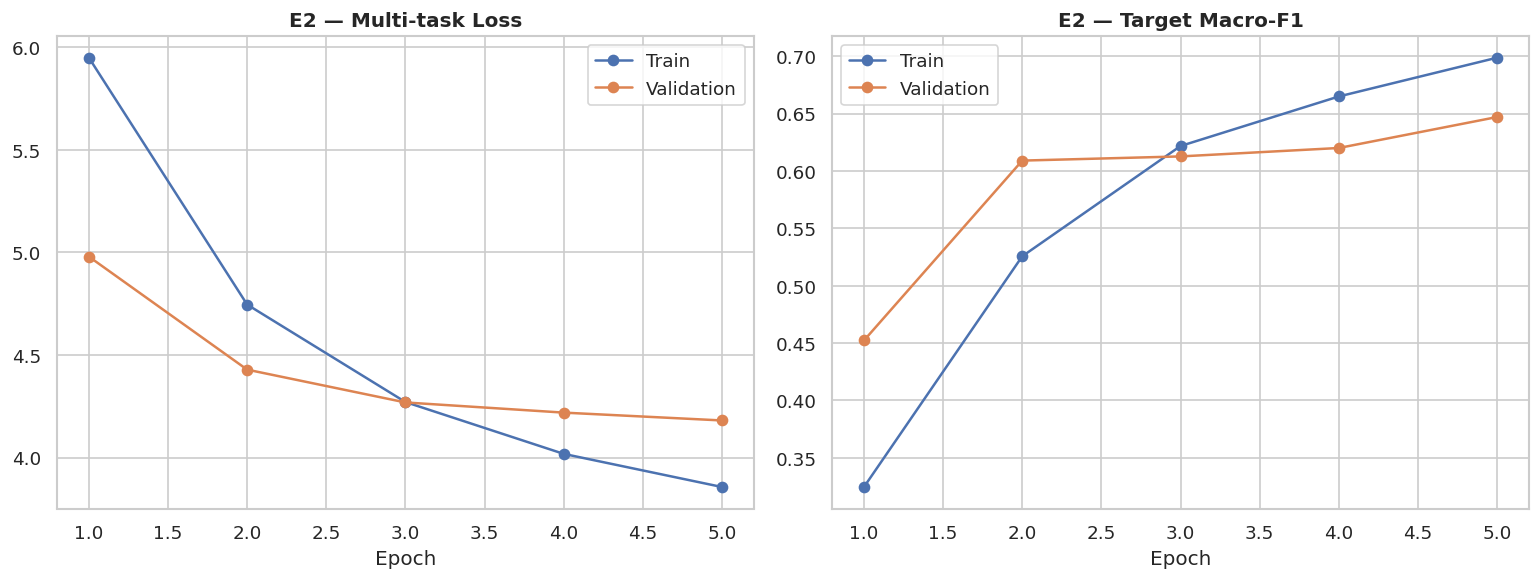

In [109]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    history_E2_df["epoch"],
    history_E2_df["train_loss"],
    marker="o",
    label="Train"
)
axes[0].plot(
    history_E2_df["epoch"],
    history_E2_df["val_loss"],
    marker="o",
    label="Validation"
)
axes[0].set_title("E2 — Multi-task Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(
    history_E2_df["epoch"],
    history_E2_df["train_macro_f1"],
    marker="o",
    label="Train"
)
axes[1].plot(
    history_E2_df["epoch"],
    history_E2_df["val_macro_f1"],
    marker="o",
    label="Validation"
)
axes[1].set_title("E2 — Target Macro-F1")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.savefig(
    OUTPUT_E2 / "learning_curves.png",
    dpi=300
)
plt.show()



In [110]:

# REMPLACER par ton véritable résultat E1
E1_MACRO_F1 = None

comparison_E1_E2 = pd.DataFrame([
    {
        "Model": "E1 — MARBERTv2 Mono-task",
        "Macro-F1 Validation": E1_MACRO_F1
    },
    {
        "Model": "E2 — MARBERTv2 Multi-task",
        "Macro-F1 Validation": best_f1_E2
    }
])

display(comparison_E1_E2)

comparison_E1_E2.to_csv(
    OUTPUT_E2 / "comparison_E1_E2.csv",
    index=False
)


,Model,Macro-F1 Validation
0,E1 — MARBERTv2 Mono-task,NaN
1,E2 — MARBERTv2 Multi-task,0.647095


# Augmentation de dataaset 

# Préparer les sources


In [111]:

import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.model_selection import train_test_split

SEED = 42

OUTPUT_AUG = Path("/kaggle/working/augmentation")
OUTPUT_AUG.mkdir(parents=True, exist_ok=True)

def prepare_source_train(df, language):
    data = df.copy().reset_index(drop=True)

    # Identifiant stable pour retrouver l'exemple original
    data["source_id"] = data.index
    data["source_language"] = language

    # Split 80/10/10 comme le protocole du TP
    # À remplacer par les partitions officielles
    # si elles ont déjà été sauvegardées.
    train, temp = train_test_split(
        data,
        test_size=0.20,
        stratify=data["target"],
        random_state=SEED
    )

    val, test = train_test_split(
        temp,
        test_size=0.50,
        stratify=temp["target"],
        random_state=SEED
    )

    return train.copy(), val.copy(), test.copy()

# Utiliser ici les datasets après premier nettoyage
# si les variables correspondantes sont disponibles.
fr_train, fr_val, fr_test = prepare_source_train(
    df_fr, "fr"
)

en_train, en_val, en_test = prepare_source_train(
    df_en, "en"
)

print("FR Train :", len(fr_train))
print("EN Train :", len(en_train))


FR Train : 3211
EN Train : 4517


# Sélectionner les candidats selon tes quotas


In [112]:

TARGETS_TO_SELECT = ["religion", "origin", "gender"]

def select_candidates(df, language):
    selected = []

    for target in TARGETS_TO_SELECT:
        subset = df[df["target"] == target].copy()

        if target == "origin":
            subset = subset.sample(
                n=min(1000, len(subset)),
                random_state=SEED
            )

        # religion et gender : tous les exemples Train
        selected.append(subset)

    result = pd.concat(
        selected,
        ignore_index=True
    )

    result = result[
        ["source_id", "source_language", "tweet", "target"]
    ].copy()

    return result


fr_candidates = select_candidates(fr_train, "fr")
en_candidates = select_candidates(en_train, "en")

df_translation_candidates = pd.concat(
    [fr_candidates, en_candidates],
    ignore_index=True
)

print("Total sélectionné :", len(df_translation_candidates))

display(
    pd.crosstab(
        df_translation_candidates["target"],
        df_translation_candidates["source_language"],
        margins=True
    )
)


Total sélectionné : 2703


source_language,en,fr,All
target,,,
gender,510,21,531
origin,1000,1000,2000
religion,55,117,172
All,1565,1138,2703


In [113]:

# Vérifier les catégories sélectionnées
assert set(df_translation_candidates["target"]).issubset(
    {"religion", "origin", "gender"}
)

# Supprimer les doublons exacts dans une même langue
df_translation_candidates = (
    df_translation_candidates
    .drop_duplicates(
        subset=["source_language", "tweet"],
        keep="first"
    )
    .reset_index(drop=True)
)

# Vérifier les textes
df_translation_candidates = df_translation_candidates[
    df_translation_candidates["tweet"].notna()
    & df_translation_candidates["tweet"].astype(str).str.strip().ne("")
].copy()

# Identifiant unique pour chaque traduction
df_translation_candidates["translation_id"] = [
    f"TR_{i:05d}"
    for i in range(len(df_translation_candidates))
]

OUTPUT_FILE = OUTPUT_AUG / "translation_candidates.csv"

df_translation_candidates.to_csv(
    OUTPUT_FILE,
    index=False,
    encoding="utf-8-sig"
)

print("Fichier créé :", OUTPUT_FILE)
print("Nombre de tweets :", len(df_translation_candidates))

display(df_translation_candidates.head(10))


Fichier créé : /kaggle/working/augmentation/translation_candidates.csv
Nombre de tweets : 2693


,source_id,source_language,tweet,target,translation_id
0,2865,fr,@user @user c’est déjà mieux que l’islamisatio...,religion,TR_00000
1,1279,fr,les vegans sont-ils contre l'avortement ?,religion,TR_00001
2,3879,fr,vérité #islam #musulmans #mosquee #censure #so...,religion,TR_00002
3,1834,fr,@user @user sachant que 85/90% des musulmans s...,religion,TR_00003
4,3323,fr,@user @user mais j' rigole sale juif,religion,TR_00004
5,1717,fr,@user @user @user il serait:anti islamisme (an...,religion,TR_00005
6,3650,fr,@user t'es drôle sale juif,religion,TR_00006
7,1178,fr,@user le rapport avec le terrorisme c'est l'ar...,religion,TR_00007
8,1666,fr,@user sale juif,religion,TR_00008
9,1872,fr,@user @user vos voulez dire que vous soupçonne...,religion,TR_00009


In [114]:

import gc
import re
import time
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from tqdm.auto import tqdm

from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM
)

SEED = 42
MODEL_TRANSLATION = "facebook/nllb-200-distilled-600M"

OUTPUT_AUG = Path("/kaggle/working/augmentation")
OUTPUT_AUG.mkdir(parents=True, exist_ok=True)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

BATCH_TRANSLATION = 8
MAX_SOURCE_LENGTH = 256
MAX_NEW_TOKENS = 256

print("Device :", device)
print("Traduction :", MODEL_TRANSLATION)


Device : cuda
Traduction : facebook/nllb-200-distilled-600M


# Charger les tweets sélectionnés

In [116]:

candidates_path = OUTPUT_AUG / "translation_candidates.csv"

df_candidates = pd.read_csv(candidates_path)

required = [
    "translation_id",
    "source_language",
    "tweet",
    "target"
]

assert all(c in df_candidates.columns for c in required)

assert df_candidates["tweet"].notna().all()
assert df_candidates["translation_id"].is_unique

assert set(df_candidates["target"]).issubset(
    {"gender", "origin", "religion"}
)

assert set(df_candidates["source_language"]).issubset(
    {"fr", "en"}
)

print("Nombre de tweets à traduire :", len(df_candidates))

display(
    pd.crosstab(
        df_candidates["target"],
        df_candidates["source_language"],
        margins=True
    )
)


Nombre de tweets à traduire : 2693


source_language,en,fr,All
target,,,
gender,504,21,525
origin,996,1000,1996
religion,55,117,172
All,1555,1138,2693


In [117]:

tokenizer_translation = AutoTokenizer.from_pretrained(
    MODEL_TRANSLATION
)

model_translation = AutoModelForSeq2SeqLM.from_pretrained(
    MODEL_TRANSLATION
).to(device)

model_translation.eval()

LANGUAGE_CODES = {
    "fr": "fra_Latn",
    "en": "eng_Latn"
}

TARGET_LANGUAGE = "arb_Arab"

target_token_id = tokenizer_translation.convert_tokens_to_ids(
    TARGET_LANGUAGE
)

print("Target language :", TARGET_LANGUAGE)
print("Target token ID :", target_token_id)


config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 4.85MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (4 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

Target language : arb_Arab
Target token ID : 256011


In [118]:

@torch.inference_mode()
def translate_batch(texts, source_language):

    tokenizer_translation.src_lang = LANGUAGE_CODES[
        source_language
    ]

    inputs = tokenizer_translation(
        list(texts),
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=MAX_SOURCE_LENGTH
    )

    inputs = {
        k: v.to(device)
        for k, v in inputs.items()
    }

    generated = model_translation.generate(
        **inputs,
        forced_bos_token_id=target_token_id,
        max_new_tokens=MAX_NEW_TOKENS,
        num_beams=4,
        do_sample=False
    )

    translations = tokenizer_translation.batch_decode(
        generated,
        skip_special_tokens=True
    )

    return translations


# Tester le fonctionnement
test_translations = translate_batch(
    [
        "This sentence is written in English.",
        "I am learning about language models."
    ],
    source_language="en"
)

for original, translated in zip(
    [
        "This sentence is written in English.",
        "I am learning about language models."
    ],
    test_translations
):
    print("Original :", original)
    print("Arabe :", translated)
    print("-" * 50)


[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Original : This sentence is written in English.
Arabe : هذه الجملة مكتوبة باللغة الإنجليزية.
--------------------------------------------------
Original : I am learning about language models.
Arabe : أنا أتعلم عن نماذج اللغة.
--------------------------------------------------


# Traduire tous les candidats avec sauvegarde progressive

In [119]:

PROGRESS_FILE = OUTPUT_AUG / "translations_progress.csv"

# Reprendre les traductions précédentes si disponibles
if PROGRESS_FILE.exists():

    df_done = pd.read_csv(PROGRESS_FILE)

    completed_ids = set(
        df_done["translation_id"].astype(str)
    )

    print("Traductions déjà enregistrées :", len(completed_ids))

else:
    df_done = pd.DataFrame()
    completed_ids = set()

pending = df_candidates[
    ~df_candidates["translation_id"].astype(str).isin(
        completed_ids
    )
].copy()

new_results = []

start_time = time.time()

for language in ["fr", "en"]:

    subset = pending[
        pending["source_language"] == language
    ].reset_index(drop=True)

    print(f"\nTraduction {language} → ar : {len(subset)} tweets")

    for start in tqdm(
        range(0, len(subset), BATCH_TRANSLATION),
        desc=f"{language} → ar"
    ):

        batch_df = subset.iloc[
            start:start + BATCH_TRANSLATION
        ]

        texts = batch_df["tweet"].astype(str).tolist()

        translations = translate_batch(
            texts,
            source_language=language
        )

        batch_results = batch_df.copy()
        batch_results["tweet_ar"] = translations
        batch_results["translation_model"] = MODEL_TRANSLATION

        new_results.append(batch_results)

        # Sauvegarde toutes les 10 batches
        if len(new_results) >= 10:

            new_df = pd.concat(
                new_results,
                ignore_index=True
            )

            df_done = pd.concat(
                [df_done, new_df],
                ignore_index=True
            )

            df_done = df_done.drop_duplicates(
                subset="translation_id",
                keep="last"
            )

            df_done.to_csv(
                PROGRESS_FILE,
                index=False,
                encoding="utf-8-sig"
            )

            new_results = []

# Sauvegarder les derniers résultats
if new_results:

    new_df = pd.concat(
        new_results,
        ignore_index=True
    )

    df_done = pd.concat(
        [df_done, new_df],
        ignore_index=True
    )

df_done = df_done.drop_duplicates(
    subset="translation_id",
    keep="last"
)

df_done.to_csv(
    PROGRESS_FILE,
    index=False,
    encoding="utf-8-sig"
)

print("\nTraductions enregistrées :", len(df_done))
print("Temps écoulé :", round(time.time() - start_time, 2), "s")
print("Fichier :", PROGRESS_FILE)



Traduction fr → ar : 1138 tweets


fr → ar:   0%|          | 0/143 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface


Traduction en → ar : 1555 tweets


en → ar:   0%|          | 0/195 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface


Traductions enregistrées : 2693
Temps écoulé : 484.25 s
Fichier : /kaggle/working/augmentation/translations_progress.csv


# Préparer tweet_clean en arabe

In [121]:

df_translated = pd.read_csv(
    PROGRESS_FILE
)

df_translated["tweet_ar"] = (
    df_translated["tweet_ar"]
    .fillna("")
    .astype(str)
)

df_translated["has_arabic"] = (
    df_translated["tweet_ar"]
    .str.contains(r"[\u0600-\u06FF]", regex=True)
)

df_translated["non_empty"] = (
    df_translated["tweet_ar"].str.strip().ne("")
)

df_translated["quality_candidate"] = (
    df_translated["has_arabic"]
    & df_translated["non_empty"]
)

print("Total traduit :", len(df_translated))
print("Textes arabes non vides :", df_translated["quality_candidate"].sum())
print("À vérifier :", (~df_translated["quality_candidate"]).sum())

display(
    df_translated[
        ["source_language", "target", "tweet", "tweet_ar", "quality_candidate"]
    ].sample(
        n=min(10, len(df_translated)),
        random_state=SEED
    )
)


Total traduit : 2693
Textes arabes non vides : 2649
À vérifier : 44


,source_language,target,tweet,tweet_ar,quality_candidate
2281,en,gender,twat.,أيها الوغد,True
2220,en,gender,can't buy class!! know clubs dick head fans tw...,لا أستطيع شراء الصف!! أعرف النوادي العصابات ال...,True
368,fr,origin,il est capable de te lâcher un sale arabe ou u...,هو قادر على إطلاق سراح العرب السيئين أو السود ...,True
535,fr,origin,@user @user pk jsuis nrv? psk ton pote et sa c...,@user @user pk jsuis nrv؟,True
2425,en,gender,@user cunt god,@user عاهرة الرب,True
1488,en,origin,@user seriously. kavvanaughs accuser arrested ...,@user على محمل الجد. تم القبض على متهم كافانوغ...,True
1127,fr,gender,@user sale féministe jui déçu,@user نسائية يهودية خيبة أمل,True
1896,en,origin,@user yeah negro,@user نعم الزنجي,True
1963,en,origin,easy solution: send illegal aliens mazie hiron...,الحل السهل: إرسال الأجانب غير الشرعيين إلى منز...,True
2292,en,gender,tweeted last one. doubling cunt. @url,التغريدة الأخيرة. مضاعفة العاهرة. @url,True


In [122]:

assert "clean_arabic" in globals(), (
    "Relance la cellule qui définit clean_arabic "
    "dans ton notebook."
)

df_translated["tweet_clean"] = (
    df_translated["tweet_ar"]
    .apply(clean_arabic)
)

df_translated = df_translated[
    df_translated["quality_candidate"]
    & df_translated["tweet_clean"].str.strip().ne("")
].copy()

# Supprimer les doublons entre traductions
df_translated = df_translated.drop_duplicates(
    subset=["tweet_clean"],
    keep="first"
)

# Exclure les tweets déjà présents dans
# Train, Validation ou Test arabe
arabic_reference = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

existing_texts = set(
    arabic_reference["tweet_clean"].astype(str)
)

df_translated = df_translated[
    ~df_translated["tweet_clean"].isin(existing_texts)
].copy()

df_translated = df_translated.reset_index(drop=True)

print("Traductions candidates après filtres :", len(df_translated))

display(
    pd.crosstab(
        df_translated["target"],
        df_translated["source_language"],
        margins=True
    )
)


Traductions candidates après filtres : 2643


source_language,en,fr,All
target,,,
gender,497,21,518
origin,960,994,1954
religion,54,117,171
All,1511,1132,2643


In [123]:

FINAL_TRANSLATIONS = OUTPUT_AUG / "translated_candidates_ar.csv"

df_translated.to_csv(
    FINAL_TRANSLATIONS,
    index=False,
    encoding="utf-8-sig"
)

print("Fichier enregistré :", FINAL_TRANSLATIONS)
print("Nombre de traductions candidates :", len(df_translated))

print("\nDistribution des classes :")
print(df_translated["target"].value_counts())


Fichier enregistré : /kaggle/working/augmentation/translated_candidates_ar.csv
Nombre de traductions candidates : 2643

Distribution des classes :
target
origin      1954
gender       518
religion     171
Name: count, dtype: int64


In [124]:

import pandas as pd
from pathlib import Path

# ==========================================
# FUSION TRAIN ARABE + TRADUCTIONS FR/EN
# ==========================================

# 1. Charger les traductions
df_aug = pd.read_csv(
    "/kaggle/working/augmentation/translated_candidates_ar.csv"
)

# 2. Conserver les colonnes nécessaires
train_original = train_df[["tweet_clean", "target"]].copy()
train_original["source"] = "arabic_original"

train_translated = df_aug[
    ["tweet_clean", "target"]
].copy()
train_translated["source"] = "translated_fr_en"

# 3. Supprimer les textes vides
train_translated = train_translated.dropna(
    subset=["tweet_clean", "target"]
)

train_translated = train_translated[
    train_translated["tweet_clean"].astype(str).str.strip().ne("")
].copy()

# 4. Supprimer les doublons entre traductions
train_translated = train_translated.drop_duplicates(
    subset="tweet_clean",
    keep="first"
)

# 5. Exclure les textes déjà présents en arabe
# dans Train, Validation et Test
existing_texts = set(
    pd.concat([
        train_df["tweet_clean"],
        val_df["tweet_clean"],
        test_df["tweet_clean"]
    ]).astype(str)
)

train_translated = train_translated[
    ~train_translated["tweet_clean"].isin(existing_texts)
].copy()

# 6. Fusionner uniquement le Train
train_augmented = pd.concat(
    [train_original, train_translated],
    ignore_index=True
)

# 7. Sauvegarder
output_path = Path(
    "/kaggle/working/augmentation/train_ar_augmented.csv"
)

output_path.parent.mkdir(parents=True, exist_ok=True)

train_augmented.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

# 8. Afficher les résultats
print("===== FUSION TERMINÉE =====")
print("Train original :", len(train_original))
print("Traductions disponibles :", len(df_aug))
print("Traductions ajoutées :", len(train_translated))
print("Train augmenté :", len(train_augmented))
print("Validation inchangée :", len(val_df))
print("Test inchangé :", len(test_df))

print("\n===== DISTRIBUTION TARGET =====")

comparison = pd.DataFrame({
    "Avant": train_original["target"].value_counts(),
    "Après": train_augmented["target"].value_counts()
}).fillna(0).astype(int)

comparison["Ajoutés"] = comparison["Après"] - comparison["Avant"]

display(comparison)

print("\nFichier sauvegardé :", output_path)


===== FUSION TERMINÉE =====
Train original : 2672
Traductions disponibles : 2643
Traductions ajoutées : 2643
Train augmenté : 5315
Validation inchangée : 334
Test inchangé : 334

===== DISTRIBUTION TARGET =====


,Avant,Après,Ajoutés
target,,,
gender,435,953,518
origin,700,2654,1954
other,1421,1421,0
religion,116,287,171



Fichier sauvegardé : /kaggle/working/augmentation/train_ar_augmented.csv


Device : cuda

Train augmenté : 5315
Validation : 334

Distribution du Train :
target
origin      2654
other       1421
gender       953
religion     287
Name: count, dtype: int64

Classes : ['gender', 'origin', 'other', 'religion']

Class weights :
gender: 1.3943
origin: 0.5007
other: 0.9351
religion: 4.6298


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: UBC-NLP/MARBERTv2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were ne


===== DÉBUT FINE-TUNING E1 AUGMENTÉ =====


Epoch 1/10:   0%|          | 0/665 [00:00<?, ?it/s]


Epoch 1/10 | Train loss: 1.2371 | Val loss: 0.9288 | Macro-F1: 0.4552 | Accuracy: 0.5210
Meilleur modèle sauvegardé.


... (14 outputs left out)

Epoch 9/10:   0%|          | 0/665 [00:00<?, ?it/s]


Epoch 9/10 | Train loss: 0.0651 | Val loss: 1.6480 | Macro-F1: 0.6046 | Accuracy: 0.6228
Early stopping : 1/3


Epoch 10/10:   0%|          | 0/665 [00:00<?, ?it/s]


Epoch 10/10 | Train loss: 0.0564 | Val loss: 1.6826 | Macro-F1: 0.6050 | Accuracy: 0.6287
Early stopping : 2/3

===== E1 MARBERTv2 AUGMENTÉ — VALIDATION =====
Best epoch : 8
Macro-F1 : 0.6137
Accuracy : 0.6287

Rapport de classification :
              precision    recall  f1-score   support

      gender       0.63      0.67      0.65        54
      origin       0.53      0.62      0.58        88
       other       0.71      0.62      0.66       177
    religion       0.50      0.67      0.57        15

    accuracy                           0.63       334
   macro avg       0.59      0.64      0.61       334
weighted avg       0.64      0.63      0.63       334



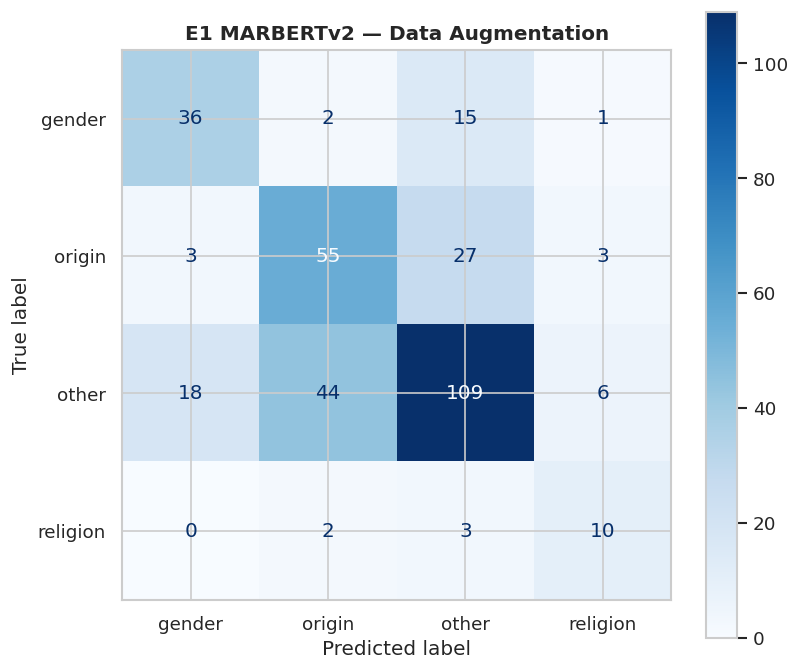

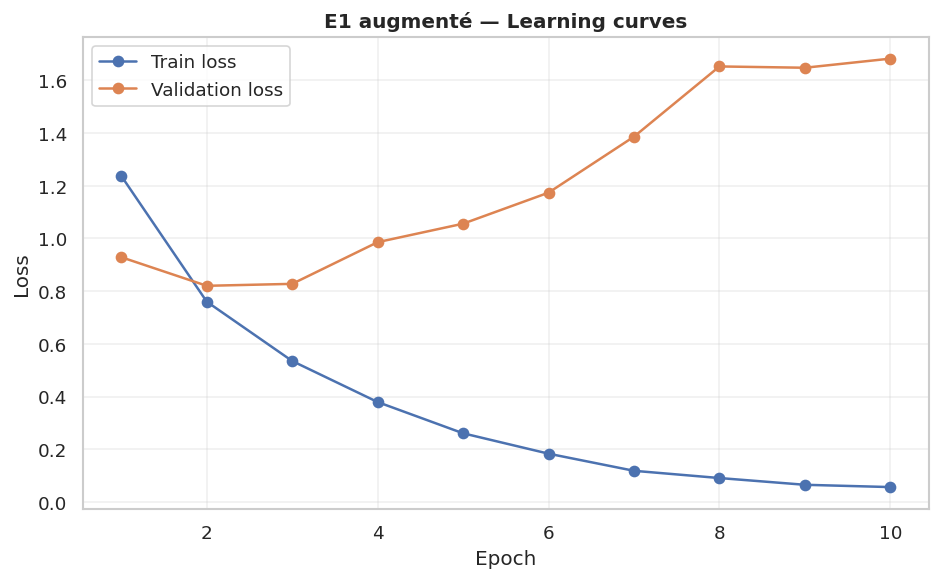


===== COMPARAISON E1 =====
E1 original  : 0.6454
E1 augmenté  : 0.6137
Différence   : -0.0317

Résultats sauvegardés dans : /kaggle/working/results/E1_MARBERTv2_AUGMENTED


In [125]:

# ================================================================
# E1 — MARBERTv2 FINE-TUNING AVEC DATA AUGMENTATION
# 10 epochs max | Weighted CE | Early Stopping | Macro-F1
# ================================================================

import os, random, gc, json, copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from torch import nn
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup
)

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# -------------------- 1. CONFIGURATION --------------------

SEED = 42
MODEL_NAME = "UBC-NLP/MARBERTv2"
MAX_LENGTH = 128
BATCH_SIZE = 8
GRAD_ACCUM = 4                  # Batch effectif = 32
EPOCHS = 10
PATIENCE = 3
LR = 2e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.10

OUTPUT_DIR = Path(
    "/kaggle/working/results/E1_MARBERTv2_AUGMENTED"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_PATH = (
    "/kaggle/working/augmentation/train_ar_augmented.csv"
)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device :", device)

# -------------------- 2. DONNÉES --------------------

train_aug_e1 = pd.read_csv(TRAIN_PATH)

assert "val_df" in globals(), (
    "val_df est nécessaire : charger la Validation "
    "arabe originale de E1."
)

val_e1 = val_df.copy()

required_cols = ["tweet_clean", "target"]

for name, df in [
    ("Train augmenté", train_aug_e1),
    ("Validation", val_e1)
]:
    assert set(required_cols).issubset(df.columns), (
        f"Colonnes manquantes dans {name}"
    )

    assert df[required_cols].notna().all().all(), (
        f"Valeurs manquantes dans {name}"
    )

train_aug_e1["tweet_clean"] = (
    train_aug_e1["tweet_clean"].astype(str)
)
val_e1["tweet_clean"] = val_e1["tweet_clean"].astype(str)

# Contrôle des doublons exacts entre Train et Validation
overlap = set(train_aug_e1["tweet_clean"]) & set(
    val_e1["tweet_clean"]
)
assert len(overlap) == 0, (
    f"Attention : {len(overlap)} textes communs "
    "entre Train et Validation."
)

print("\nTrain augmenté :", len(train_aug_e1))
print("Validation :", len(val_e1))

print("\nDistribution du Train :")
print(train_aug_e1["target"].value_counts())

# -------------------- 3. ENCODAGE DES CLASSES --------------------

label_encoder = LabelEncoder()

# Classes définies par le Train original
label_encoder.fit(train_df["target"].astype(str))

classes = list(label_encoder.classes_)
num_labels = len(classes)

assert set(train_aug_e1["target"]).issubset(set(classes))
assert set(val_e1["target"]).issubset(set(classes))

y_train = label_encoder.transform(
    train_aug_e1["target"]
)
y_val = label_encoder.transform(
    val_e1["target"]
)

print("\nClasses :", classes)

# -------------------- 4. TOKENIZER + DATASET --------------------

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

class HateSpeechDataset(Dataset):

    def __init__(self, texts, labels, tokenizer):
        self.texts = list(texts)
        self.labels = list(labels)
        self.tokenizer = tokenizer

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):

        encoded = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=MAX_LENGTH,
            return_tensors="pt"
        )

        item = {
            k: v.squeeze(0)
            for k, v in encoded.items()
        }

        item["labels"] = torch.tensor(
            self.labels[idx],
            dtype=torch.long
        )

        return item


train_dataset = HateSpeechDataset(
    train_aug_e1["tweet_clean"],
    y_train,
    tokenizer
)

val_dataset = HateSpeechDataset(
    val_e1["tweet_clean"],
    y_val,
    tokenizer
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

# -------------------- 5. CLASS WEIGHTS --------------------

counts = np.bincount(
    y_train,
    minlength=num_labels
)

assert np.all(counts > 0), (
    "Une classe est absente du Train."
)

class_weights = (
    len(y_train) / (num_labels * counts)
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device
)

print("\nClass weights :")
for name, weight in zip(classes, class_weights.tolist()):
    print(f"{name}: {weight:.4f}")

# -------------------- 6. MODÈLE --------------------

# Réinitialisation depuis les poids pré-entraînés
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_labels,
    ignore_mismatched_sizes=True
).to(device)

# Réduction de la consommation mémoire GPU
model.gradient_checkpointing_enable()

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

steps_per_epoch = int(
    np.ceil(len(train_loader) / GRAD_ACCUM)
)

total_steps = steps_per_epoch * EPOCHS
warmup_steps = int(total_steps * WARMUP_RATIO)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(device.type == "cuda")
)

# -------------------- 7. FONCTION EVALUATION --------------------

def evaluate(model, loader):

    model.eval()

    total_loss = 0.0
    all_true = []
    all_pred = []

    with torch.inference_mode():

        for batch in loader:

            labels = batch.pop("labels").to(device)

            inputs = {
                k: v.to(device)
                for k, v in batch.items()
            }

            with torch.autocast(
                device_type=device.type,
                enabled=(device.type == "cuda")
            ):
                outputs = model(**inputs)
                loss = criterion(outputs.logits, labels)

            predictions = outputs.logits.argmax(dim=1)

            total_loss += loss.item() * len(labels)

            all_true.extend(labels.cpu().numpy())
            all_pred.extend(predictions.cpu().numpy())

    macro_f1 = f1_score(
        all_true,
        all_pred,
        average="macro",
        labels=list(range(num_labels)),
        zero_division=0
    )

    accuracy = accuracy_score(
        all_true,
        all_pred
    )

    return (
        total_loss / len(loader.dataset),
        macro_f1,
        accuracy,
        np.array(all_true),
        np.array(all_pred)
    )

# -------------------- 8. ENTRAÎNEMENT --------------------

best_f1 = -1
best_epoch = 0
patience_counter = 0

history = []

best_model_path = OUTPUT_DIR / "best_model.pt"

print("\n===== DÉBUT FINE-TUNING E1 AUGMENTÉ =====")

for epoch in range(1, EPOCHS + 1):

    model.train()
    optimizer.zero_grad(set_to_none=True)

    running_loss = 0.0

    progress = tqdm(
        enumerate(train_loader),
        total=len(train_loader),
        desc=f"Epoch {epoch}/{EPOCHS}"
    )

    for step, batch in progress:

        labels = batch.pop("labels").to(device)

        inputs = {
            k: v.to(device)
            for k, v in batch.items()
        }

        with torch.autocast(
            device_type=device.type,
            enabled=(device.type == "cuda")
        ):
            outputs = model(**inputs)
            loss = criterion(outputs.logits, labels)

        running_loss += loss.item() * len(labels)

        # Gestion correcte du dernier groupe d'accumulation
        group_start = (step // GRAD_ACCUM) * GRAD_ACCUM
        group_size = min(
            GRAD_ACCUM,
            len(train_loader) - group_start
        )

        scaler.scale(loss / group_size).backward()

        update_now = (
            (step + 1) % GRAD_ACCUM == 0
            or (step + 1) == len(train_loader)
        )

        if update_now:

            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            previous_scale = scaler.get_scale()

            scaler.step(optimizer)
            scaler.update()

            # Avancer le scheduler uniquement
            # si l'optimiseur a réellement effectué son pas
            if scaler.get_scale() >= previous_scale:
                scheduler.step()

            optimizer.zero_grad(set_to_none=True)

        progress.set_postfix(
            train_loss=f"{loss.item():.4f}"
        )

    train_loss = running_loss / len(train_dataset)

    val_loss, val_f1, val_acc, _, _ = evaluate(
        model,
        val_loader
    )

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_macro_f1": val_f1,
        "val_accuracy": val_acc
    })

    print(
        f"\nEpoch {epoch}/{EPOCHS}"
        f" | Train loss: {train_loss:.4f}"
        f" | Val loss: {val_loss:.4f}"
        f" | Macro-F1: {val_f1:.4f}"
        f" | Accuracy: {val_acc:.4f}"
    )

    if val_f1 > best_f1:

        best_f1 = val_f1
        best_epoch = epoch
        patience_counter = 0

        torch.save({
            "model_state_dict": model.state_dict(),
            "classes": classes,
            "best_epoch": best_epoch,
            "best_macro_f1": best_f1,
            "seed": SEED
        }, best_model_path)

        print("Meilleur modèle sauvegardé.")

    else:

        patience_counter += 1

        print(
            f"Early stopping : "
            f"{patience_counter}/{PATIENCE}"
        )

        if patience_counter >= PATIENCE:
            print("\nEarly stopping déclenché.")
            break

# -------------------- 9. RECHARGER LE MEILLEUR MODÈLE --------------------

checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

val_loss, val_f1, val_acc, y_true, y_pred = evaluate(
    model,
    val_loader
)

print("\n===== E1 MARBERTv2 AUGMENTÉ — VALIDATION =====")
print("Best epoch :", best_epoch)
print(f"Macro-F1 : {val_f1:.4f}")
print(f"Accuracy : {val_acc:.4f}")

print("\nRapport de classification :")
print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(num_labels)),
        target_names=classes,
        zero_division=0
    )
)

# -------------------- 10. MATRICE DE CONFUSION --------------------

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(num_labels))
)

fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

plt.title("E1 MARBERTv2 — Data Augmentation")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "confusion_matrix.png",
    dpi=180
)
plt.show()

# -------------------- 11. COURBES D'APPRENTISSAGE --------------------

history_df = pd.DataFrame(history)

history_df.to_csv(
    OUTPUT_DIR / "training_history.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Train loss"
)

ax.plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation loss"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title("E1 augmenté — Learning curves")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "learning_curves.png",
    dpi=180
)
plt.show()

# -------------------- 12. COMPARAISON AVEC E1 ORIGINAL --------------------

baseline_macro_f1 = 0.6454

print("\n===== COMPARAISON E1 =====")
print(f"E1 original  : {baseline_macro_f1:.4f}")
print(f"E1 augmenté  : {val_f1:.4f}")
print(f"Différence   : {val_f1 - baseline_macro_f1:+.4f}")

# -------------------- 13. SAUVEGARDE RÉSULTATS --------------------

tokenizer.save_pretrained(OUTPUT_DIR)

metrics = {
    "model": MODEL_NAME,
    "augmentation": True,
    "train_size": len(train_aug_e1),
    "validation_size": len(val_e1),
    "best_epoch": best_epoch,
    "macro_f1": float(val_f1),
    "accuracy": float(val_acc),
    "baseline_macro_f1": baseline_macro_f1
}

with open(
    OUTPUT_DIR / "metrics.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)

print("\nRésultats sauvegardés dans :", OUTPUT_DIR)

# Libération de mémoire intermédiaire
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


Device : cuda

===== DONNÉES =====
Train original : 2672
Traductions ajoutées : 2643
Train E2 augmenté : 5315
Validation : 334

Distribution target :
target
origin      2654
other       1421
gender       953
religion     287
Name: count, dtype: int64
Attention group: 1 labels Validation inconnus ou manquants.

===== CLASSES =====
target : ['gender', 'origin', 'other', 'religion']
directness : ['direct', 'indirect']
group : ['african_descent', 'arabs', 'christian', 'gay', 'immigrants', 'indian/hindu', 'individual', 'jews', 'muslims', 'other', 'refugees', 'special_needs', 'women']
sentiment : ['abusive', 'disrespectful', 'fearful', 'hateful', 'normal', 'offensive']
annotator_sentiment : ['anger', 'confusion', 'disgust', 'fear', 'indifference', 'sadness', 'shock']


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: UBC-NLP/MARBERTv2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Architecture chargée : MARBERTv2 + 5 heads

===== DÉBUT E2 AUGMENTÉ =====


E2 Epoch 1/10:   0%|          | 0/665 [00:00<?, ?it/s]


Epoch 1/10 | Train loss: 6.0502 | Val loss: 5.2479 | Macro-F1: 0.4818 | Accuracy: 0.4910
Meilleur modèle sauvegardé.


... (12 outputs left out)

E2 Epoch 8/10:   0%|          | 0/665 [00:00<?, ?it/s]


Epoch 8/10 | Train loss: 2.6903 | Val loss: 4.5188 | Macro-F1: 0.5840 | Accuracy: 0.6108
Early stopping : 2/3


E2 Epoch 9/10:   0%|          | 0/665 [00:00<?, ?it/s]


Epoch 9/10 | Train loss: 2.5540 | Val loss: 4.5654 | Macro-F1: 0.5740 | Accuracy: 0.6168
Early stopping : 3/3

Early stopping déclenché.

===== E2 AUGMENTÉ — TARGET VALIDATION =====
Best epoch : 6
Macro-F1 : 0.5882
Accuracy : 0.6347

Classification report :
              precision    recall  f1-score   support

      gender       0.59      0.67      0.63        54
      origin       0.64      0.39      0.48        88
       other       0.67      0.75      0.70       177
    religion       0.45      0.67      0.54        15

    accuracy                           0.63       334
   macro avg       0.59      0.62      0.59       334
weighted avg       0.64      0.63      0.63       334



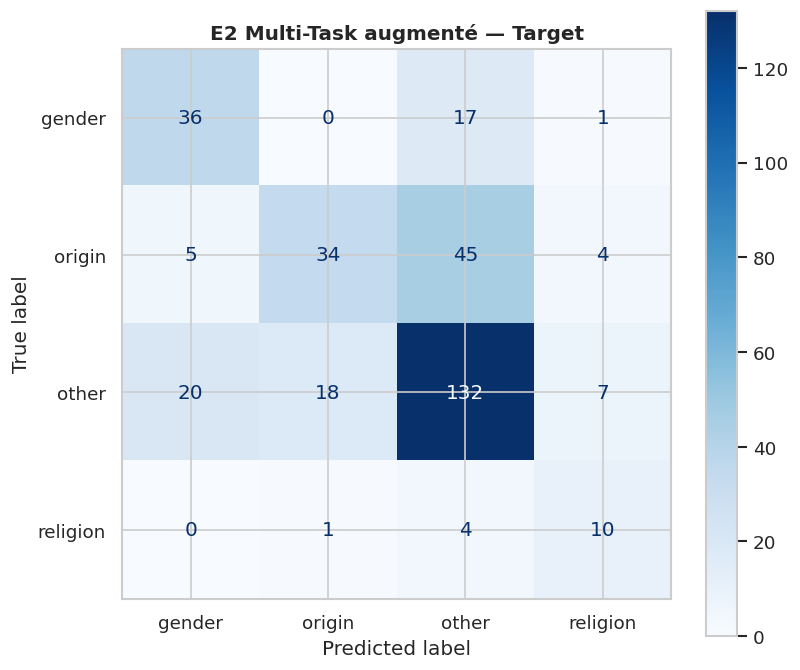

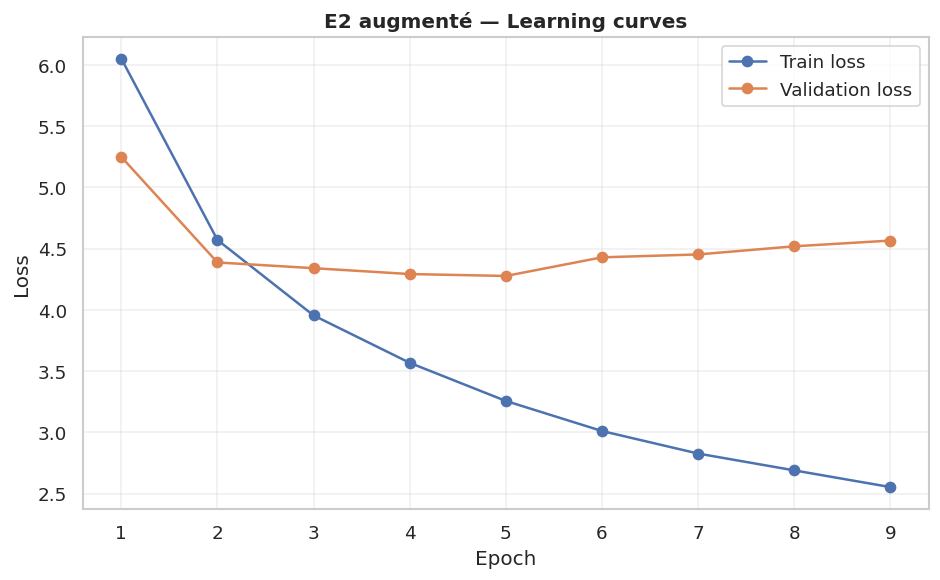


===== MÉTRIQUES DES CINQ TÂCHES =====


,task,macro_f1,accuracy,threshold,n_evaluated
0,target,0.588224,0.634731,NaN,334
1,directness,0.659770,0.661677,NaN,334
2,group,0.544453,0.690691,NaN,333
3,sentiment,0.417764,NaN,0.5,334
4,annotator_sentiment,0.294621,NaN,0.5,334



===== COMPARAISON E2 =====


,Model,Macro-F1,Accuracy
0,E2 original,0.647100,0.640700
1,E2 augmenté,0.588224,0.634731


Différence Macro-F1 : -0.0589

Résultats enregistrés : /kaggle/working/results/E2_MARBERTv2_AUGMENTED


In [126]:

# ================================================================
# E2 — MARBERTv2 MULTI-TASK + DATA AUGMENTATION
# 10 EPOCHS MAX | 5 HEADS | PARTIAL LABELS | EARLY STOPPING
# ================================================================

import os, gc, json, random, math
from pathlib import Path
from contextlib import nullcontext

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from torch import nn
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

from transformers import (
    AutoTokenizer,
    AutoModel,
    get_linear_schedule_with_warmup
)

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ================================================================
# 1. CONFIGURATION
# ================================================================

SEED = 42
MODEL_NAME = "UBC-NLP/MARBERTv2"

MAX_LENGTH = 128
BATCH_SIZE = 8
GRAD_ACCUM = 4
EPOCHS = 10
PATIENCE = 3

LR = 2e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.10

OUTPUT_DIR = Path(
    "/kaggle/working/results/E2_MARBERTv2_AUGMENTED"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_AUG_PATH = (
    "/kaggle/working/augmentation/train_ar_augmented.csv"
)

TASKS_MC = ["target", "directness", "group"]
TASKS_ML = ["sentiment", "annotator_sentiment"]
TASKS = TASKS_MC + TASKS_ML

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device :", device)

# ================================================================
# 2. CHARGEMENT ET FUSION DES DONNÉES E2
# ================================================================

assert "train_df" in globals(), "train_df original manquant"
assert "val_df" in globals(), "val_df original manquant"

train_original = train_df.copy().reset_index(drop=True)
val_e2 = val_df.copy().reset_index(drop=True)

train_aug_file = pd.read_csv(TRAIN_AUG_PATH)

required_columns = [
    "tweet_clean", "target",
    "sentiment", "directness",
    "group", "annotator_sentiment"
]

for name, data in [
    ("Train original", train_original),
    ("Validation", val_e2)
]:
    missing = [
        c for c in required_columns
        if c not in data.columns
    ]
    assert not missing, f"{name}: colonnes manquantes {missing}"

assert {"tweet_clean", "target", "source"}.issubset(
    train_aug_file.columns
)

# On récupère uniquement les exemples traduits.
# Le fichier augmenté contient déjà le Train original.
train_translated = train_aug_file[
    train_aug_file["source"] == "translated_fr_en"
][["tweet_clean", "target"]].copy()

# Les 4 labels auxiliaires n'existent pas pour ces exemples.
for task in TASKS:
    if task not in train_translated.columns:
        train_translated[task] = pd.NA

train_original = train_original[required_columns].copy()
train_translated = train_translated[required_columns].copy()

train_original["is_original"] = True
train_translated["is_original"] = False

# Sécurité : exclure les duplications exactes
reference_texts = set(
    pd.concat([
        train_original["tweet_clean"],
        val_e2["tweet_clean"],
        test_df["tweet_clean"]
    ]).astype(str)
) if "test_df" in globals() else set(
    pd.concat([
        train_original["tweet_clean"],
        val_e2["tweet_clean"]
    ]).astype(str)
)

train_translated = (
    train_translated
    .dropna(subset=["tweet_clean", "target"])
    .drop_duplicates(subset="tweet_clean")
)

train_translated = train_translated[
    ~train_translated["tweet_clean"].astype(str).isin(
        reference_texts
    )
].copy()

train_e2_aug = pd.concat(
    [train_original, train_translated],
    ignore_index=True
)

print("\n===== DONNÉES =====")
print("Train original :", len(train_original))
print("Traductions ajoutées :", len(train_translated))
print("Train E2 augmenté :", len(train_e2_aug))
print("Validation :", len(val_e2))

print("\nDistribution target :")
print(train_e2_aug["target"].value_counts())

# ================================================================
# 3. ENCODAGE DES LABELS
# ================================================================

encoders = {}
train_labels = {}
val_labels = {}

def split_multilabel(value):
    if pd.isna(value):
        return []
    return [
        x.strip().lower()
        for x in str(value).split("_")
        if x.strip()
    ]

# TARGET : classes du Train original
target_encoder = LabelEncoder()
target_encoder.fit(train_original["target"].astype(str))

# Directness et Group : classes originales uniquement.
# Une catégorie jamais observée en Train ne peut pas
# être apprise. En Validation, elle sera ignorée.
for task in TASKS_MC:

    encoder = LabelEncoder()
    encoder.fit(train_original[task].dropna().astype(str))

    encoders[task] = encoder

    # -100 désigne un label absent / non entraînable
    train_y = np.full(
        len(train_e2_aug), -100, dtype=np.int64
    )
    val_y = np.full(
        len(val_e2), -100, dtype=np.int64
    )

    train_values = train_e2_aug[task]
    val_values = val_e2[task]

    known_train = (
        train_values.notna()
        & train_values.astype(str).isin(encoder.classes_)
    )
    known_val = (
        val_values.notna()
        & val_values.astype(str).isin(encoder.classes_)
    )

    train_y[known_train.to_numpy()] = encoder.transform(
        train_values.loc[known_train].astype(str)
    )

    val_y[known_val.to_numpy()] = encoder.transform(
        val_values.loc[known_val].astype(str)
    )

    train_labels[task] = train_y
    val_labels[task] = val_y

    if (~known_val).any():
        print(
            f"Attention {task}: {(~known_val).sum()} "
            "labels Validation inconnus ou manquants."
        )

# Multi-label : vocabulaire construit à partir du Train
# original et non de Validation
for task in TASKS_ML:

    original_lists = (
        train_original[task]
        .apply(split_multilabel)
        .tolist()
    )

    vocabulary = sorted(set(
        label
        for row in original_lists
        for label in row
    ))

    assert len(vocabulary) > 0, (
        f"Aucune classe trouvée pour {task}"
    )

    mlb = MultiLabelBinarizer(classes=vocabulary)
    mlb.fit([vocabulary])

    encoders[task] = mlb

    # Les traductions sont temporairement encodées par
    # des zéros, mais leur perte sera masquée.
    all_train_lists = (
        train_e2_aug[task]
        .apply(split_multilabel)
        .tolist()
    )

    all_val_lists = (
        val_e2[task]
        .apply(split_multilabel)
        .tolist()
    )

    def keep_known(rows):
        return [
            [x for x in row if x in vocabulary]
            for row in rows
        ]

    train_labels[task] = mlb.transform(
        keep_known(all_train_lists)
    ).astype(np.float32)

    val_labels[task] = mlb.transform(
        keep_known(all_val_lists)
    ).astype(np.float32)

    unknown_val = sorted(set(
        label
        for row in all_val_lists
        for label in row
        if label not in vocabulary
    ))

    if unknown_val:
        print(
            f"Attention {task}: labels inconnus "
            f"en Validation : {unknown_val}"
        )

print("\n===== CLASSES =====")
for task in TASKS:
    print(task, ":", list(encoders[task].classes_))

# ================================================================
# 4. TOKENIZER + DATASET
# ================================================================

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class E2Dataset(Dataset):

    def __init__(self, df, labels, training=True):

        self.df = df.reset_index(drop=True)
        self.labels = labels
        self.training = training

        self.encodings = tokenizer(
            self.df["tweet_clean"].astype(str).tolist(),
            padding="max_length",
            truncation=True,
            max_length=MAX_LENGTH
        )

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        item = {
            key: torch.tensor(value[idx], dtype=torch.long)
            for key, value in self.encodings.items()
        }

        item["labels"] = {}

        for task in TASKS:

            dtype = (
                torch.long
                if task in TASKS_MC
                else torch.float32
            )

            item["labels"][task] = torch.tensor(
                self.labels[task][idx],
                dtype=dtype
            )

        # Mask de supervision.
        # Les traductions n'ont que target.
        is_original = (
            bool(self.df.iloc[idx]["is_original"])
            if self.training else True
        )

        item["supervision"] = {
            task: torch.tensor(
                True if task == "target" else is_original,
                dtype=torch.bool
            )
            for task in TASKS
        }

        return item


train_dataset = E2Dataset(
    train_e2_aug, train_labels, training=True
)
val_e2["is_original"] = True

val_dataset = E2Dataset(
    val_e2, val_labels, training=False
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

# ================================================================
# 5. ARCHITECTURE MARBERT MULTI-TASK
# ================================================================

class MARBERTMultiTask(nn.Module):

    def __init__(self, model_name, encoders):
        super().__init__()

        self.encoder = AutoModel.from_pretrained(
            model_name
        )

        self.dropout = nn.Dropout(0.2)

        hidden_size = self.encoder.config.hidden_size

        self.heads = nn.ModuleDict({
            task: nn.Linear(
                hidden_size,
                len(encoders[task].classes_)
            )
            for task in TASKS
        })

    def forward(self, **inputs):

        outputs = self.encoder(**inputs)

        cls = outputs.last_hidden_state[:, 0, :]
        cls = self.dropout(cls)

        return {
            task: head(cls)
            for task, head in self.heads.items()
        }


model = MARBERTMultiTask(
    MODEL_NAME, encoders
).to(device)

model.encoder.gradient_checkpointing_enable()

print("\nArchitecture chargée : MARBERTv2 + 5 heads")

# ================================================================
# 6. LOSSES PONDÉRÉES
# ================================================================

criterions = {}

for task in TASKS_MC:

    y = train_labels[task]
    y = y[y >= 0]

    n_classes = len(encoders[task].classes_)

    counts = np.bincount(
        y, minlength=n_classes
    )

    # Évite une division par zéro
    weights = np.ones(n_classes, dtype=np.float32)
    present = counts > 0
    weights[present] = (
        len(y) / (present.sum() * counts[present])
    )

    # Les poids sont construits sur les exemples
    # qui possèdent réellement ce label
    weights_tensor = torch.tensor(
        weights, dtype=torch.float32, device=device
    )

    criterions[task] = nn.CrossEntropyLoss(
        weight=weights_tensor
    )

for task in TASKS_ML:

    # Seulement les originaux, car seuls eux ont
    # les labels multi-label
    y = train_labels[task][:len(train_original)]

    positive = y.sum(axis=0)
    negative = len(y) - positive

    pos_weight = (
        negative / np.maximum(positive, 1)
    )
    pos_weight = np.clip(
        pos_weight, 1, 10
    )

    criterions[task] = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(
            pos_weight,
            dtype=torch.float32,
            device=device
        )
    )

# Même importance nominale pour chaque tâche.
# Les 4 tâches auxiliaires ne reçoivent aucune
# loss pour les tweets traduits.
TASK_WEIGHTS = {task: 1.0 for task in TASKS}

def compute_loss(logits, labels, supervision):

    losses = {}

    for task in TASKS:

        mask = supervision[task]

        if task in TASKS_MC:
            mask = mask & (labels[task] >= 0)

        if mask.any():

            loss = criterions[task](
                logits[task][mask].float(),
                labels[task][mask]
            )

            losses[task] = (
                TASK_WEIGHTS[task] * loss
            )

    if not losses:
        raise RuntimeError(
            "Aucun label supervisé dans ce batch."
        )

    total = sum(losses.values())

    return total, losses

# ================================================================
# 7. OPTIMIZER + SCHEDULER
# ================================================================

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

steps_per_epoch = math.ceil(
    len(train_loader) / GRAD_ACCUM
)

total_steps = steps_per_epoch * EPOCHS

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(total_steps * WARMUP_RATIO),
    num_training_steps=total_steps
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(device.type == "cuda")
)

# ================================================================
# 8. FONCTION D'ÉVALUATION
# ================================================================

def evaluate_e2():

    model.eval()
    losses_all = []

    predictions = {
        task: [] for task in TASKS
    }

    truths = {
        task: [] for task in TASKS
    }

    with torch.inference_mode():

        for batch in val_loader:

            labels = {
                k: v.to(device)
                for k, v in batch.pop("labels").items()
            }

            supervision = {
                k: v.to(device)
                for k, v in batch.pop("supervision").items()
            }

            inputs = {
                k: v.to(device)
                for k, v in batch.items()
            }

            with torch.autocast(
                device_type=device.type,
                enabled=(device.type == "cuda")
            ):

                logits = model(**inputs)

                loss, _ = compute_loss(
                    logits, labels, supervision
                )

            losses_all.append(
                (loss.item(), len(inputs["input_ids"]))
            )

            for task in TASKS:

                truths[task].append(
                    labels[task].cpu().numpy()
                )

                predictions[task].append(
                    logits[task].float().cpu().numpy()
                )

    truths = {
        t: np.concatenate(truths[t])
        for t in TASKS
    }

    predictions = {
        t: np.concatenate(predictions[t])
        for t in TASKS
    }

    true_target = truths["target"]

    pred_target = predictions["target"].argmax(axis=1)

    macro_f1 = f1_score(
        true_target,
        pred_target,
        labels=list(range(
            len(encoders["target"].classes_)
        )),
        average="macro",
        zero_division=0
    )

    accuracy = accuracy_score(
        true_target, pred_target
    )

    val_loss = (
        sum(l * n for l, n in losses_all)
        / sum(n for _, n in losses_all)
    )

    return (
        val_loss,
        macro_f1,
        accuracy,
        truths,
        predictions
    )

# ================================================================
# 9. ENTRAÎNEMENT 10 EPOCHS MAX
# ================================================================

best_f1 = -1
best_epoch = 0
patience_counter = 0
history = []

best_path = OUTPUT_DIR / "best_multitask.pt"

print("\n===== DÉBUT E2 AUGMENTÉ =====")

for epoch in range(1, EPOCHS + 1):

    model.train()
    optimizer.zero_grad(set_to_none=True)

    total_train_loss = 0.0
    total_train_examples = 0

    progress = tqdm(
        enumerate(train_loader),
        total=len(train_loader),
        desc=f"E2 Epoch {epoch}/{EPOCHS}"
    )

    for step, batch in progress:

        labels = {
            k: v.to(device)
            for k, v in batch.pop("labels").items()
        }

        supervision = {
            k: v.to(device)
            for k, v in batch.pop("supervision").items()
        }

        inputs = {
            k: v.to(device)
            for k, v in batch.items()
        }

        with torch.autocast(
            device_type=device.type,
            enabled=(device.type == "cuda")
        ):

            logits = model(**inputs)

            loss, partial_losses = compute_loss(
                logits, labels, supervision
            )

        batch_n = inputs["input_ids"].size(0)

        total_train_loss += loss.item() * batch_n
        total_train_examples += batch_n

        # Corriger l'accumulation du dernier groupe
        group_start = (
            step // GRAD_ACCUM
        ) * GRAD_ACCUM

        group_size = min(
            GRAD_ACCUM,
            len(train_loader) - group_start
        )

        scaler.scale(
            loss / group_size
        ).backward()

        update_now = (
            (step + 1) % GRAD_ACCUM == 0
            or (step + 1) == len(train_loader)
        )

        if update_now:

            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            old_scale = scaler.get_scale()

            scaler.step(optimizer)
            scaler.update()

            if scaler.get_scale() >= old_scale:
                scheduler.step()

            optimizer.zero_grad(set_to_none=True)

        progress.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    train_loss = (
        total_train_loss / total_train_examples
    )

    val_loss, val_f1, val_acc, _, _ = evaluate_e2()

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_macro_f1": val_f1,
        "val_accuracy": val_acc
    })

    print(
        f"\nEpoch {epoch}/{EPOCHS}"
        f" | Train loss: {train_loss:.4f}"
        f" | Val loss: {val_loss:.4f}"
        f" | Macro-F1: {val_f1:.4f}"
        f" | Accuracy: {val_acc:.4f}"
    )

    if val_f1 > best_f1:

        best_f1 = val_f1
        best_epoch = epoch
        patience_counter = 0

        torch.save({
            "model_state_dict": model.state_dict(),
            "best_epoch": best_epoch,
            "best_macro_f1": best_f1,
            "classes": {
                task: list(encoders[task].classes_)
                for task in TASKS
            },
            "seed": SEED
        }, best_path)

        print("Meilleur modèle sauvegardé.")

    else:

        patience_counter += 1

        print(
            f"Early stopping : "
            f"{patience_counter}/{PATIENCE}"
        )

        if patience_counter >= PATIENCE:
            print("\nEarly stopping déclenché.")
            break

# ================================================================
# 10. MEILLEUR MODÈLE + MÉTRIQUES
# ================================================================

checkpoint = torch.load(
    best_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

val_loss, val_f1, val_acc, all_true, all_logits = (
    evaluate_e2()
)

y_true = all_true["target"]
y_pred = all_logits["target"].argmax(axis=1)

classes = list(encoders["target"].classes_)

print("\n===== E2 AUGMENTÉ — TARGET VALIDATION =====")
print("Best epoch :", best_epoch)
print(f"Macro-F1 : {val_f1:.4f}")
print(f"Accuracy : {val_acc:.4f}")

print("\nClassification report :")
print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(len(classes))),
        target_names=classes,
        zero_division=0
    )
)

# ================================================================
# 11. MATRICE DE CONFUSION
# ================================================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(classes)))
)

fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

plt.title("E2 Multi-Task augmenté — Target")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "confusion_matrix.png",
    dpi=180
)
plt.show()

# ================================================================
# 12. COURBES D'APPRENTISSAGE
# ================================================================

history_df = pd.DataFrame(history)

history_df.to_csv(
    OUTPUT_DIR / "training_history.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Train loss"
)

ax.plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation loss"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title("E2 augmenté — Learning curves")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "learning_curves.png",
    dpi=180
)
plt.show()

# ================================================================
# 13. MÉTRIQUES POUR LES CINQ TÂCHES
# ================================================================

from scipy.special import expit

rows = []

for task in TASKS:

    true = all_true[task]
    logits = all_logits[task]

    if task in TASKS_MC:

        pred = logits.argmax(axis=1)

        valid = true >= 0

        score = f1_score(
            true[valid],
            pred[valid],
            average="macro",
            zero_division=0
        ) if valid.any() else np.nan

        accuracy = accuracy_score(
            true[valid], pred[valid]
        ) if valid.any() else np.nan

        rows.append({
            "task": task,
            "macro_f1": score,
            "accuracy": accuracy,
            "threshold": None,
            "n_evaluated": int(valid.sum())
        })

    else:

        probs = expit(logits)

        # Seuil fixe : pas de calibration sur Test
        threshold = 0.5
        pred = (probs >= threshold).astype(int)

        score = f1_score(
            true,
            pred,
            average="macro",
            zero_division=0
        )

        rows.append({
            "task": task,
            "macro_f1": score,
            "accuracy": None,
            "threshold": threshold,
            "n_evaluated": len(true)
        })

metrics_df = pd.DataFrame(rows)

print("\n===== MÉTRIQUES DES CINQ TÂCHES =====")
display(metrics_df)

metrics_df.to_csv(
    OUTPUT_DIR / "task_metrics.csv",
    index=False
)

# ================================================================
# 14. COMPARAISON E2 ORIGINAL VS AUGMENTÉ
# ================================================================

baseline_f1 = 0.6471
baseline_acc = 0.6407

print("\n===== COMPARAISON E2 =====")

comparison = pd.DataFrame({
    "Model": [
        "E2 original",
        "E2 augmenté"
    ],
    "Macro-F1": [
        baseline_f1,
        val_f1
    ],
    "Accuracy": [
        baseline_acc,
        val_acc
    ]
})

display(comparison)

print(
    f"Différence Macro-F1 : "
    f"{val_f1 - baseline_f1:+.4f}"
)

# ================================================================
# 15. SAUVEGARDE
# ================================================================

tokenizer.save_pretrained(OUTPUT_DIR)

metadata = {
    "model": MODEL_NAME,
    "architecture": "MARBERTv2_5_heads_partial_labels",
    "augmentation": True,
    "original_train_size": len(train_original),
    "translated_train_size": len(train_translated),
    "total_train_size": len(train_e2_aug),
    "validation_size": len(val_e2),
    "best_epoch": best_epoch,
    "target_macro_f1": float(val_f1),
    "target_accuracy": float(val_acc),
    "baseline_macro_f1": baseline_f1,
    "seed": SEED,
    "epochs_max": EPOCHS,
    "auxiliary_loss": "original_samples_only"
}

with open(
    OUTPUT_DIR / "metrics.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )

print("\nRésultats enregistrés :", OUTPUT_DIR)

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
